In [1]:
# [01] คำอธิบายโน้ตบุ๊ค อภิธานศัพท์ และ import ทั้งหมด
# ==================================================
# ทำอะไร: โน้ตบุ๊คนี้ฝึกโมเดล Decision Tree (ต้นไม้ตัดสินใจ) ทายราคารถมือสองจากไฟล์ merge_50min_clean.csv
#         ใช้ไฟล์ที่ทำความสะอาดนอกโน้ตบุ๊คด้วย data/main/clean_merged_min50.py (บันทึก: data/main/merge_50min_clean_steps.md); เซลล์ตรวจคุณภาพ [05]-[11] ตรวจอย่างเดียว ไม่ลบแถว
#         บนเครื่องของเราเองใน VS Code แล้วปรับค่าตั้งของโมเดล (hyperparameter) ด้วย cross-validation
#         และพิมพ์ผลบนชุด train / validation / test โดยไม่เขียนไฟล์ใดๆ ลงเครื่อง
#         เซลล์นี้เป็นทั้งคำอธิบายภาพรวมและที่รวม import ทั้งหมด (เซลล์อื่นไม่ import เพิ่ม)
#
# วิธีรัน:
#   1) ปิดโปรแกรมที่กินหน่วยความจำมากก่อน (เช่น แท็บเบราว์เซอร์จำนวนมาก) เพราะช่วง grid search
#      ใช้หลาย process พร้อมกัน และแต่ละ process ถือสำเนาข้อมูลของตัวเอง
#   2) เปิดไฟล์นี้ใน VS Code แล้วกด "Select Kernel" มุมขวาบน เลือก Python ของ research/.venv
#      (D:/AI_Workspace/car-project/research/.venv/Scripts/python.exe)
#   3) กด "Run All" แล้วรอจนเซลล์สุดท้าย [46] พิมพ์ผลสรุป
#      เวลาที่คาดไว้ประมาณ 5-10 นาทีบนเครื่องนี้ (ประมาณจากการรันทดลองเมื่อ 2026-10-23
#      ไม่ใช่การวัดซ้ำทุกครั้ง) ส่วนที่นานที่สุดคือ grid search ในเซลล์ [32] ช่วงนั้นเซลล์จะเงียบ
#      เป็นเรื่องปกติ
#   4) ถ้าเซลล์ไหน error ให้หยุดอ่านข้อความ error ก่อน อย่ากดรันต่อ เพราะเซลล์ถัดไปใช้ผลของเซลล์ก่อนหน้า
#
# แผนที่ของโน้ตบุ๊ค (เลขในวงเล็บคือเลขเซลล์):
#   - ตั้งค่าและอ่านข้อมูล             [01]-[04]
#   - ตรวจคุณภาพข้อมูล                 [05]-[11]
#   - เตรียมข้อมูลและแบ่งชุด           [12]-[14]
#   - ความสัมพันธ์ระหว่างตัวแปรทีละคู่  [15]-[17]
#   - โมเดล                            [18]-[21]
#   - เลือกค่า ccp_alpha               [22]-[27]
#   - grid search ด้วยกฎ 1-SE          [28]-[33]
#   - ตรวจขอบ grid                     [34]
#   - วัดผล                            [35]-[37]
#   - การตรวจเพิ่มเติม                 [38]-[45]
#   - สรุปการตรวจ overfit              [46]
#
# ต่างจากโน้ตบุ๊คต้นฉบับ (เหตุผลอยู่ในคอมเมนต์ของแต่ละเซลล์):
#   - รันบนเครื่องใน VS Code เท่านั้น ไม่เชื่อม Google Drive / Colab และไม่เขียนไฟล์ใดๆ        [02]
#   - ไม่เปลี่ยนชื่อคอลัมน์                                                          [12]
#   - ไม่มีขั้นคัดเลือกตัวแปร (feature selection)                                   [18]
#   - ขยาย grid ของ max_depth และ min_samples_leaf                                [21]
#     และเลือก ccp_alpha จากข้อมูลก่อนค้นหา                                       [22]-[26]
#   - เลือกผู้ชนะด้วยกฎ 1-SE คือเลือกต้นไม้ที่มีใบน้อยที่สุด
#     ในช่วงหนึ่ง SE จากค่า MAE ต่ำสุด แทนการเลือก MAE ต่ำสุดตรงๆ                   [28]-[33]
#   - เพิ่มการตรวจที่ต้นฉบับไม่มี:
#       คุณภาพข้อมูล [05]-[11], ความสัมพันธ์ทีละคู่ [15]-[17], ขอบ grid [34],
#       ความไวของ ccp_alpha [38]-[39], ตาราง 10 อันดับแรก [40],
#       learning curve [41]-[42], CV train เทียบ validation [43],
#       validation curve [44]-[45], สรุปการตรวจ overfit [46]
#
# โน้ตบุ๊คนี้คือ Decision Tree ฉบับที่ปรับให้รันบนเครื่องเอง ใช้โครงสร้างเซลล์เดียวกับโน้ตบุ๊ค
# Random Forest และ XGBoost ที่รันบนเครื่อง เซลล์ [01]-[19] ของทั้งสามเล่มมีเลขและงานเดียวกัน
# จะเทียบทีละเซลล์ได้ ส่วนเรื่องที่ DT ต่างจากสองโมเดลนั้น:
#   - DT มีต้นไม้ต้นเดียว ปรับความซับซ้อนด้วย max_depth, min_samples_leaf และ ccp_alpha
#     (การตัดกิ่ง) ซึ่ง Random Forest และ XGBoost ไม่มี                                [22]-[27]
#   - DT นับใบด้วยการฝึกต้นไม้ซ้ำบน train ทั้งชุด (ไม่ได้นับระหว่าง cross-validation)       [28]
#
# อภิธานศัพท์ (ศัพท์ที่จะเจอตลอดโน้ตบุ๊ค):
#   - train / validation / test: ข้อมูลสามชุด
#       train       ใช้สอนโมเดล (ให้โมเดลดูคำตอบแล้วเรียนรู้)
#       validation  กันไว้ตรวจผลอีกชุดที่โมเดลไม่เคยเห็น (ในโน้ตบุ๊คนี้การเลือกพารามิเตอร์
#                   ใช้ cross-validation บน train ส่วน validation ใช้รายงานผลคู่กับ test)
#       test        เก็บไว้ตัดสินผลสุดท้ายครั้งเดียว ไม่เอามาปรับโมเดล
#   - fold และ cross-validation (CV): แบ่งชุด train เป็นหลายส่วน (fold)
#       แล้วผลัดกันเอาทีละ fold ไปเป็นชุดทดสอบ ส่วนที่เหลือใช้สอน
#       ได้คะแนนหลายรอบมาเฉลี่ย เชื่อถือกว่าการลองแค่รอบเดียว
#   - feature: คอลัมน์ที่โมเดลใช้ทายราคา เช่น ยี่ห้อ รุ่น เลขไมล์ อายุรถ
#   - hyperparameter: ค่าที่เราตั้งเองก่อนฝึก เช่น ความลึกของต้นไม้
#       (ต่างจากค่าที่โมเดลเรียนรู้เอง)
#   - ต้นไม้ตัดสินใจ (decision tree): โมเดลที่ถามคำถามใช่/ไม่ใช่ต่อกันเป็นกิ่ง เช่น "อายุรถ <= 5 ปี?"
#       ปลายกิ่งเรียกว่าใบ (leaf) แต่ละใบให้คำตอบเป็นราคาเฉลี่ยของรถในใบนั้น
#       ใบยิ่งมาก ต้นไม้ยิ่งละเอียดและยิ่งจำข้อมูลฝึกได้มาก
#   - pruning และ ccp_alpha: pruning คือการตัดกิ่งที่ไม่คุ้มออกหลังต้นไม้โตเสร็จ
#       ccp_alpha คือ "ค่าปรับต่อหนึ่งใบ" ยิ่งมากยิ่งตัดมาก ต้นไม้ยิ่งเล็ก (0 = ไม่ตัดเลย)
#   - กฎ 1-SE: ไม่เลือกชุดค่าที่ MAE ต่ำสุดตรงๆ แต่เลือกต้นไม้ที่ใบน้อยที่สุดในกลุ่มที่ MAE
#       ไม่แย่กว่าค่าต่ำสุดเกินหนึ่ง SE (ความคลาดเคลื่อนมาตรฐาน) ได้ต้นไม้เรียบง่ายที่ดีพอๆ กัน
#   - MAE (Mean Absolute Error): ค่าเฉลี่ยของ "ทายผิดไปกี่บาท" ไม่สนว่าสูงหรือต่ำไป
#       ยิ่งต่ำยิ่งดี หน่วยเป็นบาท
#   - RMSE (Root Mean Squared Error): คล้าย MAE แต่ลงโทษความผิดพลาดก้อนใหญ่หนักกว่า
#       หน่วยเป็นบาท ยิ่งต่ำยิ่งดี
#   - MAPE (Mean Absolute Percentage Error): ทายผิดเฉลี่ยกี่เปอร์เซ็นต์ของราคาจริง
#       ยิ่งต่ำยิ่งดี
#   - R² : สัดส่วนความผันผวนของราคาที่โมเดลอธิบายได้ 1 = ทายตรงทุกคัน
#       0 = ไม่ดีกว่าการทายราคาเฉลี่ยทุกคัน (ค่าติดลบได้ถ้าแย่กว่านั้น)
#   - overfit: โมเดลจำข้อมูล train ได้ดีเกินไป จนทายข้อมูลใหม่ไม่ดี
#       (คะแนน train ดีมาก แต่ validation / test แย่กว่ามาก)
#   - underfit: โมเดลง่ายเกินไป จับรูปแบบในข้อมูลไม่ได้ ทายแย่ทั้ง train และข้อมูลใหม่
# ==================================================
import hashlib
import json
import time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
from IPython.display import display
from joblib import parallel_backend
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import (GridSearchCV, KFold, train_test_split,
                                     cross_val_score, cross_validate, validation_curve)
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeRegressor

print("=== [01] คำอธิบายโน้ตบุ๊ค อภิธานศัพท์ และ import ทั้งหมด ===")
print("import ครบแล้ว")
from sklearn.compose import TransformedTargetRegressor
from sklearn.inspection import permutation_importance
from sklearn.model_selection import cross_val_score


=== [01] คำอธิบายโน้ตบุ๊ค อภิธานศัพท์ และ import ทั้งหมด ===
import ครบแล้ว


In [2]:
# [02] กำหนดที่อยู่ไฟล์ข้อมูล
# ==================================================
# ทำอะไร: กำหนดตัวแปร DATA_PATH ให้ชี้ไปที่ไฟล์ merge_50min_clean.csv บนเครื่องนี้
# ทำไม: โน้ตบุ๊คนี้รันบนเครื่องใน VS Code เท่านั้น ไม่ได้รันใน Google Colab
#       จึงไม่ต้องเชื่อม Google Drive และไม่ต้องตรวจว่ารันที่ไหน เซลล์ถัดไปอ่านไฟล์จาก DATA_PATH
# ผลที่ควรเห็น: บรรทัดเดียวบอกที่อยู่ไฟล์ DATA_PATH
# ข้อควรระวัง: ถ้าย้ายไฟล์ข้อมูลไปที่อื่น ให้แก้ที่อยู่ในเซลล์นี้ที่เดียว
#       ใช้เครื่องหมาย / คั่นโฟลเดอร์ได้แม้บน Windows (Python เข้าใจทั้ง / และ \)
# ==================================================
print("=== [02] กำหนดที่อยู่ไฟล์ข้อมูล ===")

DATA_PATH = "D:/AI_Workspace/car-project/data/main/merge_50min_clean.csv"

print(f"DATA_PATH : {DATA_PATH}")

=== [02] กำหนดที่อยู่ไฟล์ข้อมูล ===
DATA_PATH : D:/AI_Workspace/car-project/data/main/merge_50min_clean.csv


In [3]:
# [03] ค่าคงที่ของการทดลอง
# ==================================================
# ทำอะไร: รวมค่าที่ตั้งเองทั้งหมดของการทดลองไว้ที่เดียว (เลขสุ่ม จำนวน fold รายชื่อคอลัมน์
#         สัดส่วนการแบ่งข้อมูล จำนวนงานค้นหา ฯลฯ) เซลล์อื่นอ่านค่าจากที่นี่
# ทำไม: อยากเปลี่ยนค่าไหนก็แก้ที่เดียว และไม่มี "เลขมายากล" กระจายอยู่ในโค้ด
#       ใช้เลขสุ่ม SEED เดิมทุกที่ ผลจึงทำซ้ำได้ รันกี่รอบก็ได้ตัวเลขเดิม
#   - SEARCH_JOBS = 8 และ MODEL_THREADS = 1: DecisionTreeRegressor ฝึกต้นไม้ต้นเดียวด้วย thread เดียว
#     (ไม่มีตัวเลือก n_jobs ในโมเดล) MODEL_THREADS จึงไม่ถูกส่งให้โมเดลโดยตรง แต่ใช้จำกัดจำนวน thread
#     ของไลบรารีคำนวณ (เช่น numpy) ภายในแต่ละ process ของ grid search ในเซลล์ [32] ให้ไม่แย่ง core กันเอง
#     ความเร็วจึงมาจากการให้ grid search ฝึกหลายต้นพร้อมกัน (SEARCH_JOBS ต้น) เครื่องนี้มี 22 logical CPU
#     เลือก SEARCH_JOBS x MODEL_THREADS = 8 ซึ่งไม่เกิน 20 และเหลือ core ให้ระบบ
#     เหตุผลที่ไม่ใช้ 20: แต่ละงานเป็น process แยก ถือสำเนาข้อมูลและต้นไม้ของตัวเอง หน่วยความจำว่างของ
#     เครื่องนี้มีจำกัด 8 งานยังเร็วพอเพราะต้นไม้ต้นหนึ่งฝึกเสร็จเร็ว และหน่วยความจำรวมยังเล็ก
#     จำนวนงานไม่เปลี่ยนผลลัพธ์ เพราะต้นไม้ที่ได้ขึ้นกับข้อมูลกับ SEED เท่านั้น
#   - แกนกราฟที่ล็อกไว้ (MAE_AXIS, R2_AXIS, ROWS_AXIS ฯลฯ) ประกาศไว้ท้ายเซลล์นี้ เพื่อให้กราฟของ DT / RF / XGB เทียบกันที่ความสูงเดียวกัน
# ผลที่ควรเห็น: สรุปค่าตั้งหลักๆ เรียงเป็นบรรทัด
# ข้อควรระวัง:
#   - MIN_LEAVES, CCP_N_CANDIDATES และ CCP_NEIGHBOURS เป็นกฎประมาณ (heuristic) ที่ใช้ตอนรัน
#     เพื่อเลือกค่า ccp_alpha ในเซลล์ [22]-[26] ไม่ใช่ค่าที่พิสูจน์แล้วว่าดีที่สุด
#   - ถ้าเครื่องที่รันมี CPU น้อยกว่า 10 logical CPU ให้ลด SEARCH_JOBS ลงให้ไม่เกินจำนวน logical CPU ลบ 2
#     ผลลัพธ์จะเหมือนเดิมแต่ใช้เวลานานขึ้น
#   - CURRENT_YEAR คือปีที่เก็บข้อมูล (ไม่ใช่ปีที่รันโน้ตบุ๊ค) ใช้คำนวณอายุรถ
#     ถ้าเปลี่ยนเป็นปีปัจจุบัน ตัวเลขอายุและผลของโมเดลจะเปลี่ยนไป
# ==================================================
print("=== [03] ค่าคงที่ของการทดลอง ===")

SEED = 99  # เลขสุ่มกลาง ใช้ทุกที่ที่มีการสุ่ม เพื่อให้ผลซ้ำได้
N_FOLDS = 5  # จำนวน fold ของ cross-validation
NUM_COLS = ["engine", "mileage", "car_age"]  # feature ตัวเลข
CAT_COLS = ["brand", "model", "car_type", "fuel", "gear"]  # feature ประเภทกลุ่ม
DATA_SHA256 = "191adb789285fe531bf82521e7ac0892020cbf0bf4325d22f6a657fabaab8aa1"  # ลายนิ้วมือไฟล์ข้อมูล
MODEL_NAME = "DT"  # ชื่อโมเดล ใช้ในผลลัพธ์ JSON
VERSION = "v5"  # เวอร์ชันของวิธีฝึก ใช้ในผลลัพธ์ JSON
CURRENT_YEAR = 2026  # ปีที่เก็บข้อมูล ใช้คำนวณ car_age = CURRENT_YEAR - year
TRAIN_SIZE, VAL_SIZE, TEST_SIZE = 0.8, 0.1, 0.1  # สัดส่วนแบ่ง train / validation / test
MIN_LEAVES = 20  # จำนวนใบขั้นต่ำที่ยอมรับตอนเลือก ccp_alpha (heuristic)
CCP_N_CANDIDATES = 20  # จำนวนค่า ccp_alpha ที่คัดมาลอง (heuristic)
CCP_NEIGHBOURS = 3  # จำนวนค่าข้างเคียงที่เพิ่มรอบค่าที่เลือก (heuristic)
LC_FRACTIONS = np.arange(1, 11) / 10  # สัดส่วน train ที่ใช้วาด learning curve: 10% ถึง 100%
LC_REPEATS = 5  # จำนวนรอบสุ่มซ้ำของ learning curve ต่อหนึ่งสัดส่วน
SEARCH_JOBS = 8  # จำนวนงานค้นหาที่รันพร้อมกันใน GridSearchCV (SEARCH_JOBS x MODEL_THREADS ไม่เกิน 20)
MODEL_THREADS = 1  # จำนวน thread ของไลบรารีคำนวณภายในแต่ละงาน (DT ฝึกด้วย thread เดียวอยู่แล้ว)

# --- แกนกราฟที่ล็อกไว้ (ค่าเหมือนกันทั้ง 3 โน้ตบุ๊ค DT / RF / XGB ต้องแก้ให้ตรงกันทุกไฟล์) ---
# ทำไมต้องล็อก: ให้กราฟของ DT / RF / XGB เทียบกันด้วยตาได้ที่ความสูงเดียวกัน
#   ถ้าปล่อยให้ matplotlib เลือกช่วงเอง ค่าเดียวกันจะไปอยู่คนละความสูงในแต่ละโน้ตบุ๊ค
# เลือกช่วงอย่างไร: ดูค่าต่ำสุด/สูงสุดที่กราฟวาด (รวมแถบ ±1 sd) จากผลที่บันทึกไว้ของทั้ง 3 โน้ตบุ๊ค
#   แล้วเผื่อขอบเล็กน้อยและปัดเป็นเลขกลม ถ้าข้อมูลเปลี่ยนจนค่าหลุดช่วง เซลล์กราฟจะพิมพ์ WARN
MAE_AXIS = (20000, 90000)  # แกน MAE (บาท) ของ learning curve และ validation curve ครอบทุกโมเดล
R2_AXIS = (0.8, 1.0)  # แกน R² ของ learning curve
ROWS_AXIS = (0, 40000)  # แกน x ของ learning curve: จำนวนแถวฝึก (ทุกโมเดลฝึกบนข้อมูลชุดเดียวกัน)
FOLD_AXIS = (-0.5, 4.5)  # แกน x ของกราฟแท่งราย fold: ตำแหน่ง 0..4 (ต้องสัมพันธ์กับ N_FOLDS = 5)
MAE_BAR_AXIS = (0, 70000)  # แกน y ของกราฟแท่ง MAE ต่อ fold: แท่งต้องเริ่มที่ 0 จึงแยกจาก MAE_AXIS
MAE_CCP_AXIS = (50000, 130000)  # แกน y ของกราฟ ccp_alpha (เฉพาะ DT): ฝั่ง alpha สูงเกิน MAE_AXIS จึงใช้ช่วงซูมแยก
MAE_OOB_AXIS = (52000, 54000)  # แกน y ของกราฟ OOB (เฉพาะ RF): เส้นแบนมาก ถ้าใช้ MAE_AXIS เส้นจะเป็นขีดตรง จึงใช้ช่วงซูมแยก
MAE_ROUND_AXIS = (30000, 70000)  # แกน y ของกราฟรายรอบ (เฉพาะ XGB): ตัดรอบแรกๆ ที่ MAE สูงมากทิ้งเหมือนเดิม จึงใช้ช่วงซูมแยก

print(f"SEED                   : {SEED}")
print(f"จำนวน fold             : {N_FOLDS}")
print(f"ตัวแปรตัวเลข           : {NUM_COLS}")
print(f"ตัวแปรประเภทกลุ่ม      : {CAT_COLS}")
print(f"สัดส่วน train/val/test : {TRAIN_SIZE} / {VAL_SIZE} / {TEST_SIZE}")
print(f"ปีที่เก็บข้อมูล        : {CURRENT_YEAR}")
print(f"โมเดล / เวอร์ชัน       : {MODEL_NAME} / {VERSION}")
print(f"งานค้นหา x thread      : {SEARCH_JOBS} x {MODEL_THREADS}")
RUN_ID = "DT_merge50minC_adj"
DATASET = "merge_50min_clean.csv"
VARIANT = "adj"
PERM_AXIS = (0, 150000)
SHARE_AXIS = (0, 1.0)


=== [03] ค่าคงที่ของการทดลอง ===
SEED                   : 99
จำนวน fold             : 5
ตัวแปรตัวเลข           : ['engine', 'mileage', 'car_age']
ตัวแปรประเภทกลุ่ม      : ['brand', 'model', 'car_type', 'fuel', 'gear']
สัดส่วน train/val/test : 0.8 / 0.1 / 0.1
ปีที่เก็บข้อมูล        : 2026
โมเดล / เวอร์ชัน       : DT / v5
งานค้นหา x thread      : 8 x 1


In [4]:
# [04] อ่าน CSV และตรวจ sha256
# ==================================================
# ทำอะไร: อ่านไฟล์ข้อมูลเป็นไบต์ ตัดตัวอักษร CR (b"\r") ออก คำนวณ sha256 เทียบกับ DATA_SHA256
#         ถ้าตรงจึงอ่านไฟล์เป็นตาราง raw_df
# ทำไม:
#   - sha256 คือ "ลายนิ้วมือ" ของไฟล์ ถ้าแม้แต่ตัวอักษรเดียวต่าง ลายนิ้วมือจะเปลี่ยนทั้งหมด
#     จึงใช้ยืนยันว่าเป็นข้อมูลเวอร์ชันที่ถูกต้อง ไม่ใช่ไฟล์ที่ถูกแก้หรือผิดรุ่น
#   - ตัด CR ก่อน เพราะ Windows ขึ้นบรรทัดใหม่ด้วย \r\n ส่วน Linux ใช้ \n
#     ไฟล์เดียวกันจึงให้ hash เดียวกันทุกระบบ
#   - เก็บตารางต้นทางไว้ใน raw_df และไม่แก้ไข เซลล์ [12] จะทำสำเนาไปเตรียมข้อมูลต่อ
#     จึงรันซ้ำได้โดยไม่ต้องอ่านไฟล์ใหม่
#   - encoding="utf-8-sig" รองรับ BOM (ตัวอักษรพิเศษต้นไฟล์ที่ Excel ชอบใส่)
# ผลที่ควรเห็น: ข้อความว่าตรวจผ่าน จำนวนแถวและคอลัมน์ และตัวอย่าง 5 แถวแรก
# ข้อควรระวัง: ถ้า assert ล้ม แปลว่าไฟล์ไม่ใช่ข้อมูลชุดเดิม ให้หยุดและตรวจไฟล์ก่อน
#       อย่าปรับ DATA_SHA256 ให้ตรงโดยไม่รู้สาเหตุ
# ==================================================
print("=== [04] อ่าน CSV และตรวจ sha256 ===")

raw_bytes = Path(DATA_PATH).read_bytes().replace(b"\r", b"")
assert hashlib.sha256(raw_bytes).hexdigest() == DATA_SHA256, "sha256 ของข้อมูลไม่ตรงกับต้นฉบับ"
raw_df = pd.read_csv(DATA_PATH, encoding="utf-8-sig")

print("ตรวจ sha256 ผ่าน: ข้อมูลตรงกับต้นฉบับ")
print(f"จำนวนแถว     : {raw_df.shape[0]:,}")
print(f"จำนวนคอลัมน์ : {raw_df.shape[1]:,}")
print("ตัวอย่าง 5 แถวแรก:")
display(raw_df.head())

=== [04] อ่าน CSV และตรวจ sha256 ===
ตรวจ sha256 ผ่าน: ข้อมูลตรงกับต้นฉบับ
จำนวนแถว     : 47,001
จำนวนคอลัมน์ : 10
ตัวอย่าง 5 แถวแรก:


,brand,model,year,price,mileage,engine,gear,fuel,color,car_type
0,HONDA,CR-V,2024,1129000,42500,2000,Automatic,Hybrid,Grey,SUV
1,TOYOTA,VELLFIRE,2015,999000,147500,2500,Automatic,Hybrid,White,MPV
2,BMW,530E,2021,899000,107500,2000,Automatic,Hybrid,White,Sedan
3,HONDA,HR-V,2023,759000,97500,1500,Automatic,Hybrid,Grey,SUV
4,TOYOTA,YARIS CROSS,2024,749000,32500,1500,Automatic,Hybrid,Grey,SUV


=== [05] ตรวจคุณภาพ 1: ค่าว่าง ===
ตารางนี้บอกว่าแต่ละคอลัมน์มีค่าว่างกี่ช่อง และคิดเป็นกี่เปอร์เซ็นต์ของทุกแถว


,missing_count,missing_percent
brand,0,0.00
model,0,0.00
year,0,0.00
price,0,0.00
mileage,0,0.00
engine,0,0.00
gear,0,0.00
fuel,0,0.00
color,0,0.00
car_type,0,0.00


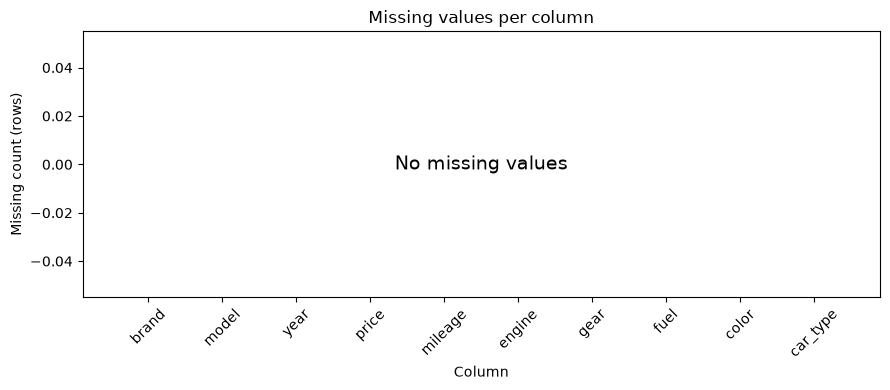

ไม่พบค่าว่าง


In [5]:
# [05] ตรวจคุณภาพ 1: ค่าว่าง
# ==================================================
# ทำอะไร: นับจำนวนและเปอร์เซ็นต์ของ "ค่าว่าง" (missing value, ช่องที่ไม่มีข้อมูล) ในทุกคอลัมน์ของ raw_df
#         แล้ววาดแท่งกราฟจำนวนค่าว่างต่อคอลัมน์
# ทำไม: ส่วนนี้ ([05]–[11]) คือการตรวจคุณภาพข้อมูลก่อนสร้างโมเดล เพราะหลัก "garbage in, garbage out"
#       คือถ้าข้อมูลเข้าไม่ดี (ว่าง ซ้ำ เป็นไปไม่ได้ กระจายแปลก) ต่อให้โมเดลดีแค่ไหน ผลลัพธ์ก็ไม่น่าเชื่อถือ
#       ค่าว่างต้องรู้ก่อนเสมอ เพราะถ้ามีอยู่ ต้องตัดสินใจว่าจะเติม ลบ หรือปล่อยไว้
#       ข้อตกลงของทั้งส่วนนี้:
#       1) ทุกเซลล์ตรวจบน raw_df ทั้งไฟล์ (ก่อนเตรียมข้อมูล) ซึ่งปลอดภัย เพราะไม่มีผลการตรวจใดถูกนำไปเลือก
#          อะไรให้โมเดลเลย (ไม่มี data leakage คือข้อมูลชุดทดสอบไม่รั่วไปมีอิทธิพลต่อการเลือกโมเดล)
#       2) ส่วนนี้ "รายงานอย่างเดียว" ไม่แก้ raw_df และไม่สร้างตัวแปรที่เซลล์อื่นต้องใช้
#          ถ้าพบปัญหา ผู้ใช้เป็นคนตัดสินใจทีหลังว่าจะทำอย่างไร ข้อมูลจึงไม่ถูกเปลี่ยนที่นี่
#          และผลของโมเดลไม่เปลี่ยน
#       3) ข้อสรุปท้ายแต่ละเซลล์ถูกคำนวณโดยโค้ด ไม่ได้พิมพ์ตายตัว
# ผลที่ควรเห็น: ตารางหนึ่งแถวต่อคอลัมน์ (10 แถว) บอกจำนวนค่าว่างและเปอร์เซ็นต์ กราฟแท่งจำนวนค่าว่างต่อคอลัมน์
#       ถ้าทุกแท่งเป็นศูนย์ บนกราฟจะมีข้อความ "No missing values" และบรรทัดสุดท้ายบอกว่าไม่พบค่าว่าง
#       ถ้ามีแท่งสูง แสดงว่าคอลัมน์นั้นมีข้อมูลหาย ควรหาสาเหตุก่อนไปต่อ
# ==================================================
print("=== [05] ตรวจคุณภาพ 1: ค่าว่าง ===")

missing_table = pd.DataFrame({
    "missing_count": raw_df.isna().sum(),
    "missing_percent": raw_df.isna().mean() * 100,
})

print("ตารางนี้บอกว่าแต่ละคอลัมน์มีค่าว่างกี่ช่อง และคิดเป็นกี่เปอร์เซ็นต์ของทุกแถว")
display(missing_table.style.format({
    "missing_count": "{:,.0f}",
    "missing_percent": "{:.2f}",
}))

total_missing = int(missing_table["missing_count"].sum())

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(missing_table.index, missing_table["missing_count"])
ax.set_title("Missing values per column")
ax.set_xlabel("Column")
ax.set_ylabel("Missing count (rows)")
ax.tick_params(axis="x", rotation=45)
if total_missing == 0:
    ax.text(0.5, 0.5, "No missing values", transform=ax.transAxes,
            ha="center", va="center", fontsize=14)
plt.tight_layout()
plt.show()

if total_missing == 0:
    print("ไม่พบค่าว่าง")
else:
    columns_with_missing = int((missing_table["missing_count"] > 0).sum())
    print(f"พบค่าว่างรวม {total_missing:,} ค่า ใน {columns_with_missing} คอลัมน์")

=== [06] ตรวจคุณภาพ 2: แถวซ้ำ ===
ตารางนี้บอกจำนวนแถวที่ซ้ำกับแถวก่อนหน้า ตามแต่ละนิยามของคำว่า 'ซ้ำ'


,duplicate_rows,percent_of_rows
all columns,0,0.00
all except price,"9,103",19.37
all except color,"1,467",3.12


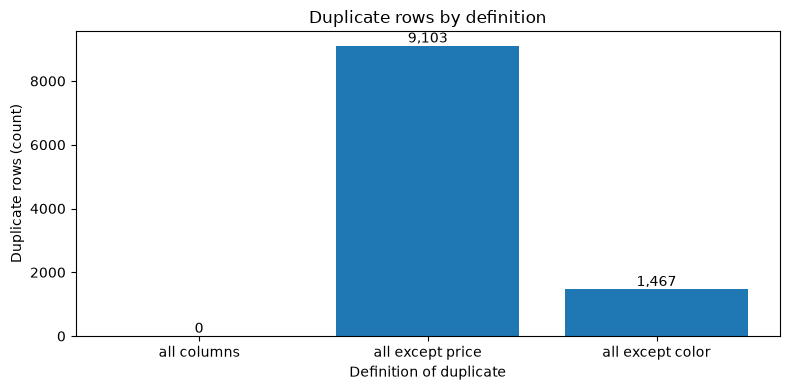

ไม่พบแถวที่ซ้ำกันทุกคอลัมน์
แถวที่ต่างกันแค่ price (ธงเตือน)   : 9,103 แถว
แถวที่ต่างกันแค่ color (รถคนละคัน) : 1,467 แถว


In [6]:
# [06] ตรวจคุณภาพ 2: แถวซ้ำ
# ==================================================
# ทำอะไร: นับแถวที่ "ซ้ำกับแถวก่อนหน้า" (ตัวสำเนาส่วนเกิน ไม่นับแถวแรกที่เจอ) ตาม 3 นิยาม
#         1) เหมือนกันทุกคอลัมน์
#         2) เหมือนกันทุกคอลัมน์ ยกเว้น price
#         3) เหมือนกันทุกคอลัมน์ ยกเว้น color
# ทำไม: กฎของโปรเจกต์นี้คือ "แถวที่ต่างกันในคอลัมน์ใดก็ตามที่ไม่ใช่ price ถือว่าเป็นรถคนละคัน"
#       ดังนั้น
#       - นิยาม 1 คือแถวซ้ำจริง ๆ (อาจเป็นข้อมูลที่ถูกบันทึกซ้ำ)
#       - นิยาม 2 คือแถวที่ทุกอย่างเหมือนกันหมดแต่ราคาต่างกัน ตามกฎอาจเป็นรถคันเดียวที่ถูกประกาศขายสองราคา
#         จึงเป็นธงเตือนคุณภาพ (quality flag) ไม่ใช่ข้อผิดพลาดที่ยืนยันแล้ว
#       - นิยาม 3 คือแถวที่ต่างกันแค่สี ตามกฎเป็นรถคนละคัน (สีต่างกัน) จึงไม่ใช่ข้อมูลซ้ำ
#         ข้อนี้เชื่อมกับหมายเหตุในเซลล์ [13] ที่อธิบายเรื่องการแบ่งข้อมูล
#       แถวซ้ำสำคัญเพราะถ้าแถวเดียวกันอยู่ทั้งชุดเทรนและชุดทดสอบ คะแนนทดสอบจะดีเกินจริง
#       เซลล์นี้รายงานอย่างเดียว ไม่ลบแถวใดเลย
# ผลที่ควรเห็น: ตารางสามแถว (นิยามละหนึ่งแถว) บอกจำนวนแถวซ้ำและเปอร์เซ็นต์ กราฟแท่งสามแท่งเขียนตัวเลขบนแท่ง
#       ตัวเลขนิยาม 2 และ 3 จะมากกว่าหรือเท่ากับนิยาม 1 เสมอ (เพราะเทียบน้อยคอลัมน์กว่า เจอซ้ำง่ายกว่า)
# ==================================================
print("=== [06] ตรวจคุณภาพ 2: แถวซ้ำ ===")

definitions = {
    "all columns": list(raw_df.columns),
    "all except price": [c for c in raw_df.columns if c != "price"],
    "all except color": [c for c in raw_df.columns if c != "color"],
}

duplicate_counts = {}
for name, columns in definitions.items():
    duplicate_counts[name] = int(raw_df.duplicated(subset=columns, keep="first").sum())

duplicate_table = pd.DataFrame({
    "duplicate_rows": pd.Series(duplicate_counts),
})
duplicate_table["percent_of_rows"] = duplicate_table["duplicate_rows"] / len(raw_df) * 100

print("ตารางนี้บอกจำนวนแถวที่ซ้ำกับแถวก่อนหน้า ตามแต่ละนิยามของคำว่า 'ซ้ำ'")
display(duplicate_table.style.format({
    "duplicate_rows": "{:,.0f}",
    "percent_of_rows": "{:.2f}",
}))

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(duplicate_table.index, duplicate_table["duplicate_rows"])
ax.bar_label(bars, fmt="{:,.0f}")
ax.set_title("Duplicate rows by definition")
ax.set_xlabel("Definition of duplicate")
ax.set_ylabel("Duplicate rows (count)")
plt.tight_layout()
plt.show()

if duplicate_counts["all columns"] == 0:
    print("ไม่พบแถวที่ซ้ำกันทุกคอลัมน์")
else:
    print(f"พบแถวซ้ำทุกคอลัมน์ {duplicate_counts['all columns']:,} แถว")
print(f"แถวที่ต่างกันแค่ price (ธงเตือน)   : {duplicate_counts['all except price']:,} แถว")
print(f"แถวที่ต่างกันแค่ color (รถคนละคัน) : {duplicate_counts['all except color']:,} แถว")

=== [07] ตรวจคุณภาพ 3: ค่าที่เป็นไปไม่ได้ ===
ตารางนี้บอกว่าแต่ละกฎมีกี่แถวที่ฝ่าฝืน (ควรเป็น 0 ทุกกฎ)


,rows_violating
price <= 0,0
engine <= 0,0
mileage < 0,0
year > 2026,0


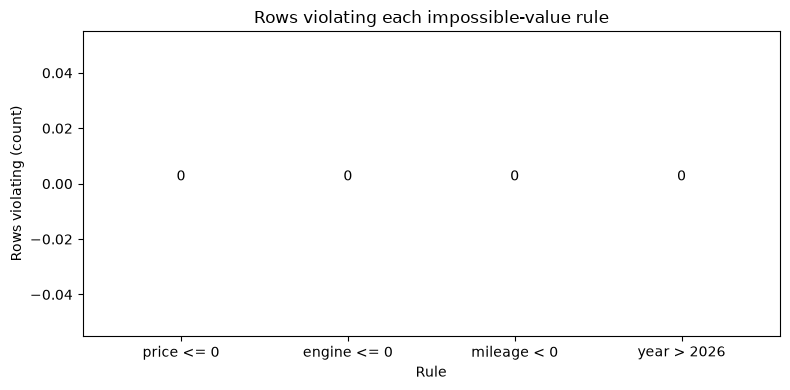

ไม่พบค่าที่เป็นไปไม่ได้


In [7]:
# [07] ตรวจคุณภาพ 3: ค่าที่เป็นไปไม่ได้
# ==================================================
# ทำอะไร: นับแถวที่ฝ่าฝืนกฎ "ค่าที่เป็นไปไม่ได้ในโลกจริง" 4 ข้อ
#         1) price <= 0     ราคาขายต้องมากกว่า 0 บาท
#         2) engine <= 0    ขนาดเครื่องยนต์ (cc) ต้องมากกว่า 0
#         3) mileage < 0    เลขไมล์ติดลบไม่ได้ (ไมล์เป็น 0 ได้ เช่นรถใหม่)
#         4) year > CURRENT_YEAR   ปีของรถต้องไม่เกินปีปัจจุบัน (CURRENT_YEAR กำหนดในเซลล์ [03])
# ทำไม: ค่าที่เป็นไปไม่ได้แปลว่าข้อมูลผิดแน่นอน (เช่นกรอกผิดหรือระบบเก็บพลาด) ไม่เหมือนค่าที่แค่หายาก
#       ถ้ามีอยู่จะทำให้โมเดลเรียนรู้จากข้อมูลเท็จ ใช้เฉพาะกฎที่ตรรกะบังคับเท่านั้น
#       ไม่คิดเกณฑ์ที่ตั้งเองตามใจ เช่น "รถเก่าเกินไป" เพราะรถเก่ามากที่ราคาสูงก็มีจริง (รถคลาสสิก)
# ผลที่ควรเห็น: ตารางแต่ละกฎกับจำนวนแถวที่ฝ่าฝืน และกราฟแท่งของแต่ละกฎ
#       ถ้าทุกกฎเป็น 0 แปลว่าไม่พบค่าที่เป็นไปไม่ได้ ถ้าไม่ใช่ ควรดูแถวนั้นก่อนตัดสินใจว่าจะทำอย่างไร
#       (เซลล์นี้ไม่แก้และไม่ลบข้อมูล)
# ==================================================
print("=== [07] ตรวจคุณภาพ 3: ค่าที่เป็นไปไม่ได้ ===")

impossible_counts = {
    "price <= 0": int((raw_df["price"] <= 0).sum()),
    "engine <= 0": int((raw_df["engine"] <= 0).sum()),
    "mileage < 0": int((raw_df["mileage"] < 0).sum()),
    f"year > {CURRENT_YEAR}": int((raw_df["year"] > CURRENT_YEAR).sum()),
}

impossible_table = pd.DataFrame({
    "rows_violating": pd.Series(impossible_counts),
})

print("ตารางนี้บอกว่าแต่ละกฎมีกี่แถวที่ฝ่าฝืน (ควรเป็น 0 ทุกกฎ)")
display(impossible_table.style.format({"rows_violating": "{:,.0f}"}))

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(impossible_table.index, impossible_table["rows_violating"])
ax.bar_label(bars, fmt="{:,.0f}")
ax.set_title("Rows violating each impossible-value rule")
ax.set_xlabel("Rule")
ax.set_ylabel("Rows violating (count)")
plt.tight_layout()
plt.show()

total_impossible = sum(impossible_counts.values())
if total_impossible == 0:
    print("ไม่พบค่าที่เป็นไปไม่ได้")
else:
    print(f"พบการฝ่าฝืนกฎรวม {total_impossible:,} ครั้ง (นับซ้ำได้ถ้าแถวเดียวฝ่าฝืนหลายกฎ)")

=== [08] ตรวจคุณภาพ 4: การกระจายของตัวเลข ===
ตารางนี้สรุปสถิติของคอลัมน์ตัวเลข: count=จำนวนแถว, 25%/50%/75%=Q1/มัธยฐาน/Q3


,price,engine,mileage,year
count,"47,001","47,001","47,001","47,001"
mean,"555,726","1,923","114,673","2,019"
std,"328,569",514,"63,036",4
min,"27,900","1,000",183,"2,006"
25%,"339,000","1,500","67,500","2,017"
50%,"469,000","2,000","107,000","2,019"
75%,"689,000","2,400","156,406","2,022"
max,"2,000,000","3,600","300,000","2,026"


C:\Users\putaw\AppData\Local\Temp\ipykernel_17684\3351676981.py:28: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1, position].boxplot(raw_df[column], vert=False)
C:\Users\putaw\AppData\Local\Temp\ipykernel_17684\3351676981.py:28: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1, position].boxplot(raw_df[column], vert=False)
C:\Users\putaw\AppData\Local\Temp\ipykernel_17684\3351676981.py:28: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1, position].boxplot(raw_df[column], vert=False)
C:\Users\putaw\AppData\Local\Temp\ipykernel_17684\3351676981.py:28: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be re

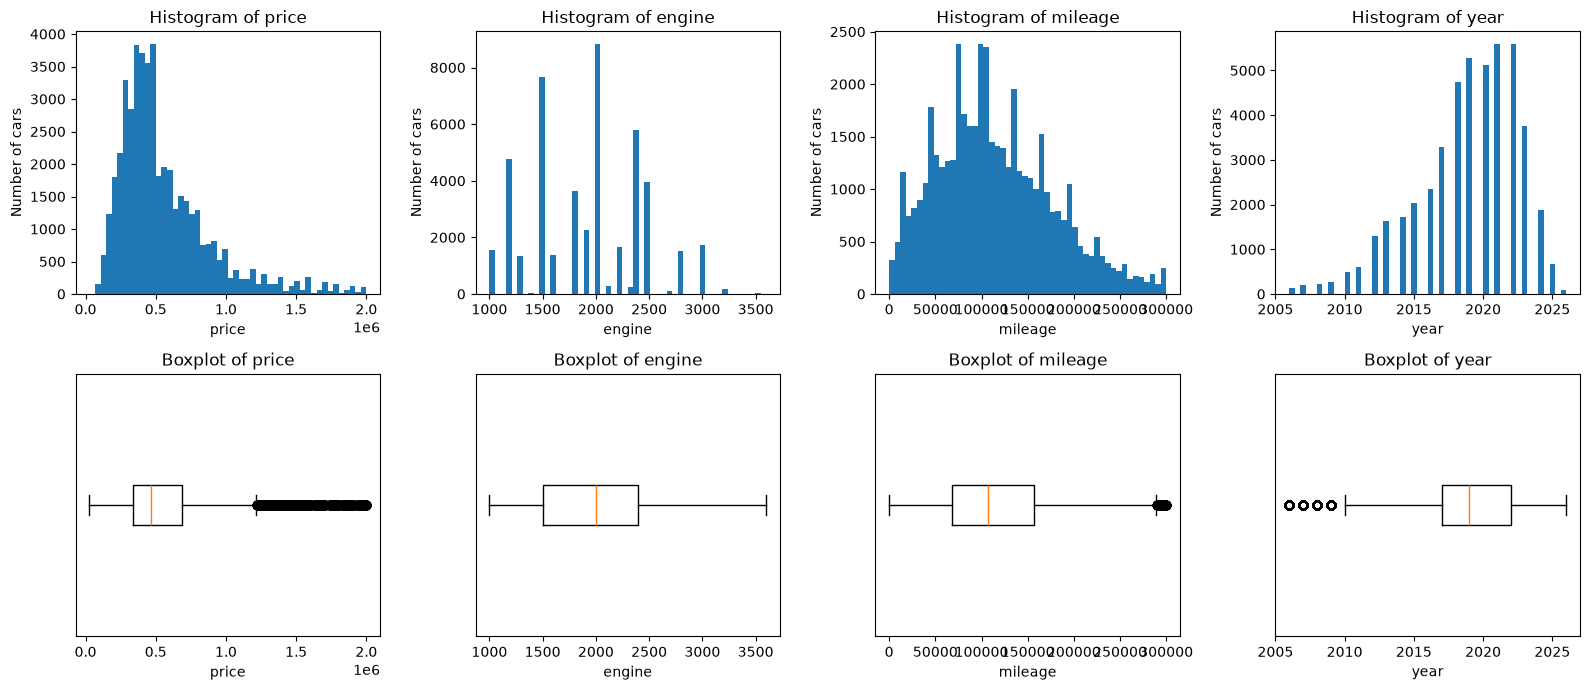

price   : ค่าความเบ้ +1.65 -> เบ้ขวาชัดเจน (หางยาวไปทางค่าสูง)
engine  : ค่าความเบ้ +0.20 -> ไม่เบ้มาก
mileage : ค่าความเบ้ +0.54 -> ไม่เบ้มาก
year    : ค่าความเบ้ -0.80 -> ไม่เบ้มาก


In [8]:
# [08] ตรวจคุณภาพ 4: การกระจายของตัวเลข
# ==================================================
# ทำอะไร: สรุปสถิติ (describe) ของคอลัมน์ตัวเลข 4 ตัว (price, engine, mileage, year)
#         แล้ววาด histogram (แถวบน) และ boxplot (แถวล่าง) ของแต่ละตัว
# ทำไม: การดูรูปร่างการกระจายของข้อมูลช่วยให้เห็นสิ่งที่ตัวเลขสรุปไม่บอก เช่น ข้อมูลเบ้ หรือถูกตัดที่ค่าสูงสุด
# วิธีอ่านกราฟ (เป็นสิ่งที่ควรสังเกต ไม่ใช่ข้อเท็จจริงของการรันครั้งนี้):
#   - Histogram: แบ่งค่าเป็นช่วง (bins = 50 ช่วง) แท่งสูง = มีรถในช่วงราคา/ค่านั้นมาก
#   - Boxplot: กล่อง = ข้อมูลตรงกลาง 50% (จาก Q1 ถึง Q3), เส้นในกล่อง = มัธยฐาน (median คือค่ากลางเมื่อเรียงลำดับ),
#              หนวด (whiskers) = ช่วงที่ยังถือว่าปกติ, จุดนอกหนวด = ค่าที่ห่างมาก (outlier)
#   - ความเบ้ (skew): ถ้าหางยาวไปทางขวา (ส่วนใหญ่ค่าต่ำ มีบางคันแพงมาก) เรียกว่าเบ้ขวา ราคารถมักเป็นแบบนี้
#   - แท่งสูงผิดปกติที่ค่าสูงสุด: อาจหมายถึงข้อมูลถูกตัดเพดาน (capped) ตอนเก็บ เช่น ทุกคันที่แพงกว่าเพดานถูกบันทึกเป็นค่าเพดาน
# ผลที่ควรเห็น: ตารางสถิติ (จำนวน ค่าเฉลี่ย ส่วนเบี่ยงเบนมาตรฐาน ต่ำสุด quartile สูงสุด) และรูป 2 แถว 4 คอลัมน์
#       ตารางไม่ได้ถูกแก้ข้อมูลใด ๆ เซลล์นี้รายงานอย่างเดียว
# ==================================================
print("=== [08] ตรวจคุณภาพ 4: การกระจายของตัวเลข ===")

numeric_check_columns = ["price", "engine", "mileage", "year"]

print("ตารางนี้สรุปสถิติของคอลัมน์ตัวเลข: count=จำนวนแถว, 25%/50%/75%=Q1/มัธยฐาน/Q3")
display(raw_df[numeric_check_columns].describe().style.format("{:,.0f}"))

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for position, column in enumerate(numeric_check_columns):
    axes[0, position].hist(raw_df[column], bins=50)
    axes[0, position].set_title(f"Histogram of {column}")
    axes[0, position].set_xlabel(column)
    axes[0, position].set_ylabel("Number of cars")
    axes[1, position].boxplot(raw_df[column], vert=False)
    axes[1, position].set_title(f"Boxplot of {column}")
    axes[1, position].set_xlabel(column)
    axes[1, position].set_yticks([])
plt.tight_layout()
plt.show()

skewness = raw_df[numeric_check_columns].skew()
for column in numeric_check_columns:
    if skewness[column] > 1:
        shape = "เบ้ขวาชัดเจน (หางยาวไปทางค่าสูง)"
    elif skewness[column] < -1:
        shape = "เบ้ซ้ายชัดเจน (หางยาวไปทางค่าต่ำ)"
    else:
        shape = "ไม่เบ้มาก"
    print(f"{column:<8}: ค่าความเบ้ {skewness[column]:+.2f} -> {shape}")

=== [09] ตรวจคุณภาพ 5: ค่าผิดปกติ (IQR) ===
ตารางนี้บอกรั้วล่าง/บนของแต่ละคอลัมน์ และจำนวนแถวที่อยู่นอกรั้ว


column,q1,q3,iqr,lower_fence,upper_fence,below,above,outlier_percent,outliers
price,"339,000","689,000","350,000","-186,000","1,214,000",0,"2,509",5.34,"2,509"
engine,"1,500","2,400",900,150,"3,750",0,0,0.00,0
mileage,"67,500","156,406","88,906","-65,859","289,765",0,342,0.73,342
year,"2,017","2,022",5,"2,010","2,030",839,0,1.79,839


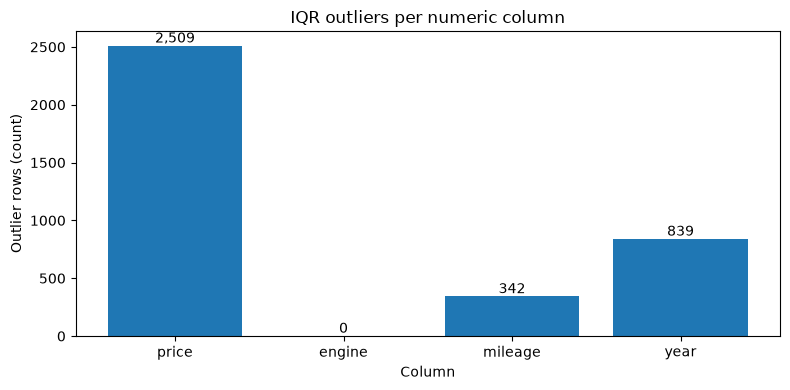

พบค่านอกรั้ว IQR รวม 3,690 ค่า (ไม่ได้ลบ เพราะอาจเป็นข้อมูลจริง)


In [9]:
# [09] ตรวจคุณภาพ 5: ค่าผิดปกติ (IQR)
# ==================================================
# ทำอะไร: หาค่าผิดปกติ (outlier คือค่าที่ห่างจากส่วนใหญ่มาก) ของคอลัมน์ตัวเลขแต่ละตัวด้วยกฎ IQR ของ Tukey
#         ขั้นตอน: หา Q1 (ค่าที่ 25% ของข้อมูลต่ำกว่า) และ Q3 (ค่าที่ 75%)
#                  IQR = Q3 - Q1 (ความกว้างของข้อมูลตรงกลาง 50%)
#                  รั้วล่าง = Q1 - 1.5 x IQR, รั้วบน = Q3 + 1.5 x IQR
#                  ค่าที่ต่ำกว่ารั้วล่างหรือสูงกว่ารั้วบนนับเป็น outlier
# ทำไม: 1.5 เป็นค่าที่ John Tukey เสนอไว้เป็นธรรมเนียมปฏิบัติ (convention) ไม่ใช่กฎธรรมชาติ
#       ต้องระวังว่า outlier ไม่ได้แปลว่าข้อมูลผิดเสมอไป รถแพงมากมีอยู่จริง จึงเป็นข้อมูลจริงที่ควรเก็บไว้
#       ต้นไม้ตัดสินใจ (decision tree) แบ่งข้อมูลด้วยลำดับ (มากกว่า/น้อยกว่าเกณฑ์) จึงไม่สนใจว่าค่าสุดโต่งนั้นสุดโต่งแค่ไหน
#       ค่าฟีเจอร์ที่สุดโต่งจึงกระทบต้นไม้น้อย (ต่างจากโมเดลเชิงเส้นที่ถูกลากง่าย)
#       เซลล์นี้ไม่ลบหรือแก้ค่าใดเลย รายงานอย่างเดียว
# ผลที่ควรเห็น: ตารางต่อคอลัมน์ (Q1, Q3, IQR, รั้วล่าง/บน, จำนวนที่ต่ำกว่า/สูงกว่า, เปอร์เซ็นต์ของแถวทั้งหมด)
#       และกราฟแท่งจำนวน outlier ต่อคอลัมน์ ถ้าแท่งสูงให้ดูว่าเป็นค่าจริงที่หายากหรือสัญญาณข้อมูลผิด
# ==================================================
print("=== [09] ตรวจคุณภาพ 5: ค่าผิดปกติ (IQR) ===")

numeric_check_columns = ["price", "engine", "mileage", "year"]

rows = []
for column in numeric_check_columns:
    q1 = raw_df[column].quantile(0.25)
    q3 = raw_df[column].quantile(0.75)
    iqr = q3 - q1
    lower_fence = q1 - 1.5 * iqr
    upper_fence = q3 + 1.5 * iqr
    below = int((raw_df[column] < lower_fence).sum())
    above = int((raw_df[column] > upper_fence).sum())
    rows.append({
        "column": column,
        "q1": q1,
        "q3": q3,
        "iqr": iqr,
        "lower_fence": lower_fence,
        "upper_fence": upper_fence,
        "below": below,
        "above": above,
        "outlier_percent": (below + above) / len(raw_df) * 100,
    })

outlier_table = pd.DataFrame(rows)
outlier_table["outliers"] = outlier_table["below"] + outlier_table["above"]

print("ตารางนี้บอกรั้วล่าง/บนของแต่ละคอลัมน์ และจำนวนแถวที่อยู่นอกรั้ว")
display(outlier_table.style.hide(axis="index").format({
    "q1": "{:,.0f}",
    "q3": "{:,.0f}",
    "iqr": "{:,.0f}",
    "lower_fence": "{:,.0f}",
    "upper_fence": "{:,.0f}",
    "below": "{:,.0f}",
    "above": "{:,.0f}",
    "outlier_percent": "{:.2f}",
    "outliers": "{:,.0f}",
}))

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(outlier_table["column"], outlier_table["outliers"])
ax.bar_label(bars, fmt="{:,.0f}")
ax.set_title("IQR outliers per numeric column")
ax.set_xlabel("Column")
ax.set_ylabel("Outlier rows (count)")
plt.tight_layout()
plt.show()

total_outliers = int(outlier_table["outliers"].sum())
if total_outliers == 0:
    print("ไม่พบค่าผิดปกติตามกฎ IQR")
else:
    print(f"พบค่านอกรั้ว IQR รวม {total_outliers:,} ค่า (ไม่ได้ลบ เพราะอาจเป็นข้อมูลจริง)")

=== [10] ตรวจคุณภาพ 6: ตัวแปรกลุ่ม ===
ตารางนี้บอกจำนวนระดับของแต่ละคอลัมน์กลุ่ม และระดับที่พบบ่อยที่สุดพร้อมสัดส่วน


column,levels,most_common,most_common_share_percent,smallest_level_rows
brand,20,TOYOTA,32.91,91
model,115,HILUX REVO,5.77,52
car_type,7,Sedan,29.23,"1,798"
fuel,3,Benzine,49.88,"5,423"
gear,2,Automatic,87.92,"5,677"
color,20,White,34.85,1


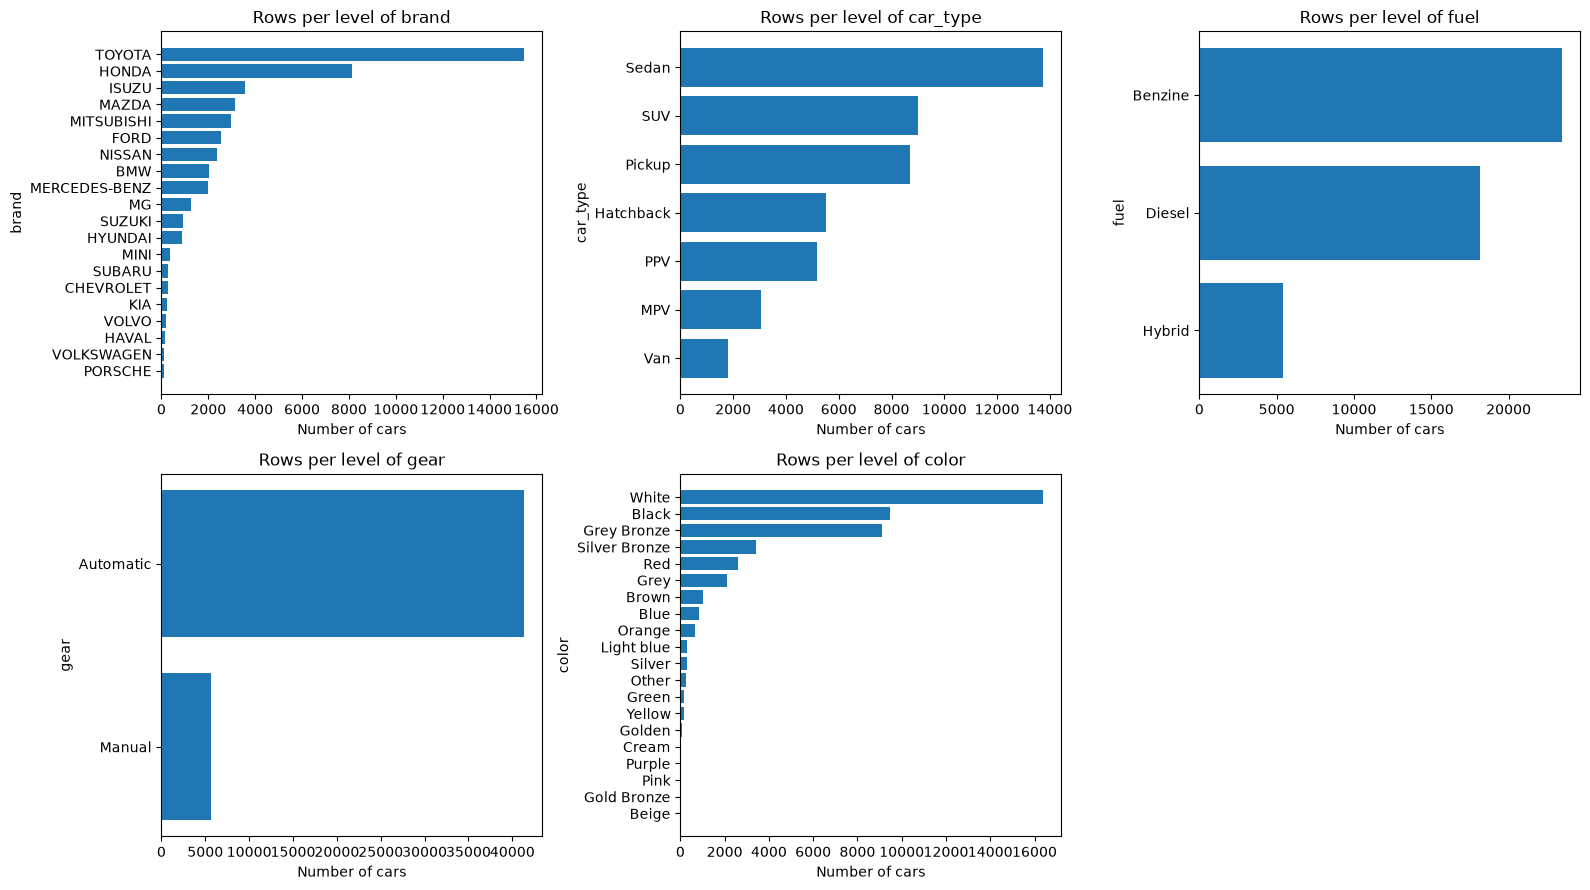

ระดับที่มีแถวน้อยที่สุดในทุกคอลัมน์กลุ่ม มี 1 แถว


In [10]:
# [10] ตรวจคุณภาพ 6: ตัวแปรกลุ่ม
# ==================================================
# ทำอะไร: ดูคอลัมน์ที่เป็นกลุ่ม/ประเภท (categorical) 6 ตัว: brand, model, car_type, fuel, gear, color
#         นับจำนวนระดับ (level คือค่าที่แตกต่างกัน เช่น fuel มี เบนซิน/ดีเซล/...) ระดับที่พบบ่อยที่สุดและสัดส่วนของมัน
#         แล้ววาดแท่งแนวนอนจำนวนแถวต่อระดับ ของ brand, car_type, fuel, gear, color
# ทำไม: ระดับที่หายาก (rare level คือมีแถวน้อยมาก) สร้างปัญหาสองอย่าง
#       1) One-hot encoding (แปลงแต่ละระดับเป็นคอลัมน์ 0/1) จะได้คอลัมน์ที่เกือบทั้งหมดเป็น 0 และเรียนรู้อะไรไม่ได้มาก
#       2) การแบ่งข้อมูลและการแบ่งโหนดของต้นไม้: ถ้าระดับหนึ่งมีไม่กี่แถว อาจไม่มีตัวอย่างในชุดทดสอบ หรือต้นไม้
#          แบ่งตามระดับนั้นแล้วได้ใบ (leaf) เล็กจนไม่น่าเชื่อถือ
#       คอลัมน์ model มีหลายระดับเกินกว่าจะวาดเป็นกราฟแท่ง เซลล์ [11] ดูเรื่องนี้แยกต่างหาก
# ผลที่ควรเห็น: ตารางต่อคอลัมน์ (จำนวนระดับ ระดับที่พบมากสุด สัดส่วน) และรูป 2x3 ช่อง ใช้ 5 ช่อง
#       ช่องที่หกถูกลบทิ้ง ในกราฟ แท่งสั้นมาก ๆ คือระดับหายาก
# ==================================================
print("=== [10] ตรวจคุณภาพ 6: ตัวแปรกลุ่ม ===")

categorical_check_columns = ["brand", "model", "car_type", "fuel", "gear", "color"]

rows = []
for column in categorical_check_columns:
    counts = raw_df[column].value_counts()
    rows.append({
        "column": column,
        "levels": len(counts),
        "most_common": counts.index[0],
        "most_common_share_percent": counts.iloc[0] / len(raw_df) * 100,
        "smallest_level_rows": counts.min(),
    })
level_table = pd.DataFrame(rows)

print("ตารางนี้บอกจำนวนระดับของแต่ละคอลัมน์กลุ่ม และระดับที่พบบ่อยที่สุดพร้อมสัดส่วน")
display(level_table.style.hide(axis="index").format({
    "levels": "{:,.0f}",
    "most_common_share_percent": "{:.2f}",
    "smallest_level_rows": "{:,.0f}",
}))

plot_columns = ["brand", "car_type", "fuel", "gear", "color"]
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
flat_axes = axes.flatten()
for position, column in enumerate(plot_columns):
    counts = raw_df[column].value_counts().sort_values()
    flat_axes[position].barh(counts.index.astype(str), counts.to_numpy())
    flat_axes[position].set_title(f"Rows per level of {column}")
    flat_axes[position].set_xlabel("Number of cars")
    flat_axes[position].set_ylabel(column)
fig.delaxes(flat_axes[5])
plt.tight_layout()
plt.show()

smallest_level_rows = level_table["smallest_level_rows"].min()
print(f"ระดับที่มีแถวน้อยที่สุดในทุกคอลัมน์กลุ่ม มี {smallest_level_rows:,} แถว")

=== [11] ตรวจคุณภาพ 7: จำนวนรถต่อรุ่น ===
จำนวนรุ่น (brand|model) : 115
แถวต่อรุ่น ต่ำสุด       : 52
แถวต่อรุ่น มัธยฐาน      : 193
แถวต่อรุ่น สูงสุด       : 2,712
ตารางนี้แสดง 10 รุ่นที่มีแถวน้อยที่สุด


brand,model,rows
MERCEDES-BENZ,S300,52
VOLVO,XC40,52
TOYOTA,PRIUS,52
MG,VS HEV,53
VOLVO,XC90,53
NISSAN,SYLPHY,53
CHEVROLET,TRAILBLAZER,55
HAVAL,JOLION,61
MERCEDES-BENZ,E250,62
TOYOTA,HARRIER,67


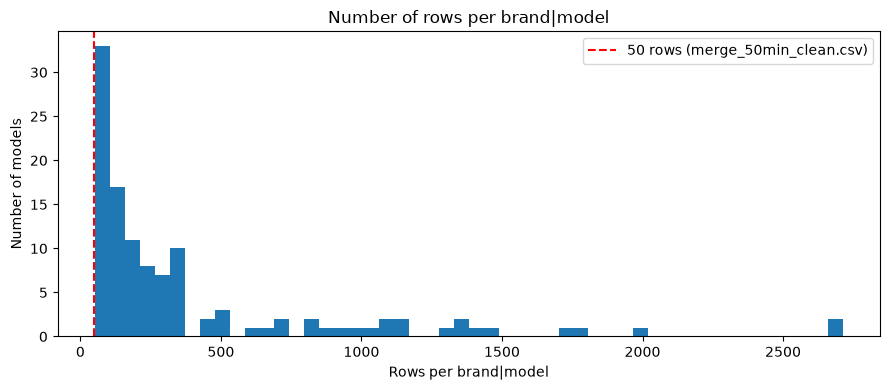

ทุกรุ่นมีอย่างน้อย 50 แถว ตามเงื่อนไขของไฟล์ merge_50min_clean.csv


In [11]:
# [11] ตรวจคุณภาพ 7: จำนวนรถต่อรุ่น
# ==================================================
# ทำอะไร: นับจำนวนแถวต่อรุ่นรถ (หนึ่งรุ่น = หนึ่งคู่ brand + model) แล้วแสดงค่าต่ำสุด มัธยฐาน สูงสุด
#         ตาราง 10 รุ่นที่มีแถวน้อยที่สุด และ histogram ของจำนวนแถวต่อรุ่น
#         มีเส้นประแนวตั้งที่ 50 แถว (ขอบล่างตามชื่อไฟล์)
# ทำไม: ไฟล์ merge_50min_clean.csv ยังคงเก็บเฉพาะรุ่นที่มีอย่างน้อย 50 แถว
#       จำนวนแถวต่อรุ่นสำคัญ เพราะเซลล์ [13] แบ่งข้อมูลแบบ stratified (แบ่งโดยรักษาสัดส่วนของแต่ละรุ่น)
#       คือเอา 80/10/10 ของ "แต่ละรุ่น" ไปไว้ใน train/validation/test
#       ถ้ารุ่นหนึ่งมีแถวน้อย ชุดทดสอบจะได้แถวของรุ่นนั้นน้อยมาก (เช่น 50 แถว x 10% = 5 แถว)
#       ผลการวัดของรุ่นนั้นจึงไม่นิ่ง การตรวจนี้จึงยืนยันว่าเงื่อนไขขั้นต่ำ 50 แถวเป็นจริง
# ผลที่ควรเห็น: ค่า min/median/max, ตาราง 10 รุ่นที่เล็กที่สุด, histogram (หางขวายาวเป็นปกติ
#       เพราะรุ่นยอดนิยมมีแถวมาก) ถ้าค่าต่ำสุดน้อยกว่า 50 แสดงว่าไฟล์ไม่ตรงกับชื่อ ซึ่งบรรทัดสุดท้ายจะรายงานให้
# ==================================================
print("=== [11] ตรวจคุณภาพ 7: จำนวนรถต่อรุ่น ===")

rows_per_model = raw_df.groupby(["brand", "model"]).size()

print(f"จำนวนรุ่น (brand|model) : {len(rows_per_model):,}")
print(f"แถวต่อรุ่น ต่ำสุด       : {rows_per_model.min():,.0f}")
print(f"แถวต่อรุ่น มัธยฐาน      : {rows_per_model.median():,.0f}")
print(f"แถวต่อรุ่น สูงสุด       : {rows_per_model.max():,.0f}")

smallest_models = rows_per_model.sort_values().head(10).rename("rows").reset_index()
print("ตารางนี้แสดง 10 รุ่นที่มีแถวน้อยที่สุด")
display(smallest_models.style.hide(axis="index").format({"rows": "{:,.0f}"}))

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(rows_per_model, bins=50)
ax.axvline(50, color="red", linestyle="--", label="50 rows (merge_50min_clean.csv)")
ax.set_title("Number of rows per brand|model")
ax.set_xlabel("Rows per brand|model")
ax.set_ylabel("Number of models")
ax.legend()
plt.tight_layout()
plt.show()

if rows_per_model.min() >= 50:
    print("ทุกรุ่นมีอย่างน้อย 50 แถว ตามเงื่อนไขของไฟล์ merge_50min_clean.csv")
else:
    print(f"พบรุ่นที่มีแถวน้อยกว่า 50: {int((rows_per_model < 50).sum()):,} รุ่น")

In [12]:
# [12] เตรียมข้อมูล: car_age และตัดคอลัมน์
# ==================================================
# ทำอะไร: ทำสำเนาของ raw_df เป็น df แล้ว
#         (1) สร้างคอลัมน์ car_age = CURRENT_YEAR - year (อายุรถเป็นปี)
#         (2) ตัดคอลัมน์ year และ color ทิ้ง
#         (3) ตรวจว่าคอลัมน์ที่ใช้ทั้งหมดไม่มีค่าว่าง
# ทำไม:
#   - ตัด year เพราะ car_age บอกข้อมูลเดียวกันอยู่แล้ว (ปีที่ผลิตมากขึ้น = อายุน้อยลง)
#     เก็บไว้ทั้งสองจะซ้ำซ้อน
#   - ตัด color เพราะเป็นการตัดสินใจของโปรเจกต์ที่จะไม่ใช้สีเป็น feature
#     (ผลของการตัดนี้ต่อแถวที่ค่าเหมือนกันข้ามชุด อธิบายไว้ในเซลล์ [13])
#   - สร้าง df จาก raw_df.copy() ทุกครั้ง เพื่อให้รันเซลล์นี้ซ้ำได้ ไม่แก้ raw_df
#     ถ้าแก้ df ตรงๆ รอบที่สองจะไม่มีคอลัมน์ year ให้คำนวณแล้ว
#   - ไม่เปลี่ยนชื่อคอลัมน์ engine, fuel, gear เป็น engine_capacity, fuel_type, gear_type
#     ที่ต้นฉบับทำ เพราะผู้ใช้สั่งให้ใช้ชื่อตามไฟล์ข้อมูล การเปลี่ยนชื่อไม่มีผลกับตัวเลขของโมเดล
#     (ทดสอบแล้วได้ R² เท่าเดิมทุกหลัก) ต่างกันแค่ชื่อที่แสดงใน features และ RESULT_JSON
#     ถ้าจะเทียบกับไฟล์โมเดล V4 เดิม (V4_*_min50.json) ต้องจับคู่ชื่อเอง
# ผลที่ควรเห็น: ขนาดตาราง df และรายชื่อคอลัมน์ (ต้องไม่มี year และ color แต่มี car_age)
# ==================================================
print("=== [12] เตรียมข้อมูล: car_age และตัดคอลัมน์ ===")

df = raw_df.copy()
df["car_age"] = CURRENT_YEAR - df["year"]
df = df.drop(columns=["year", "color"])
assert df[NUM_COLS + CAT_COLS + ["price"]].notna().all().all()

print(f"ขนาดตาราง df : {df.shape[0]:,} แถว x {df.shape[1]:,} คอลัมน์")
print(f"คอลัมน์      : {list(df.columns)}")
assert (df["price"] > 0).all(), "log(price) ต้องมีราคาเป็นบวกทุกแถว"


=== [12] เตรียมข้อมูล: car_age และตัดคอลัมน์ ===
ขนาดตาราง df : 47,001 แถว x 9 คอลัมน์
คอลัมน์      : ['brand', 'model', 'price', 'mileage', 'engine', 'gear', 'fuel', 'car_type', 'car_age']


In [13]:
# [13] แบ่ง train / validation / test
# ==================================================
# ทำอะไร: แบ่ง df เป็น train 80% / validation 10% / test 10% โดยแบ่งทีละรุ่นรถ (stratify)
# ทำไม:
#   - ทำไมแบ่งสามชุด: train สอนโมเดล, validation กันไว้ตรวจผลอีกชุด (การเลือกพารามิเตอร์ใช้ CV บน train),
#     test ตัดสินผลสุดท้ายครั้งเดียว (ดูอภิธานศัพท์ในเซลล์ [01])
#   - ทำไมต้อง stratify: แบ่งทีละรุ่น ไม่ใช่สุ่มรวมทั้งก้อน
#     ตัวอย่าง: HONDA|CR-V มี 100 แถว จะได้ train 80, validation 10, test 10
#               TOYOTA|Camry มี 60 แถว จะได้ train 48, validation 6, test 6
#     ทำให้ทุกรุ่นอยู่ครบทั้ง 3 ชุดในสัดส่วนเดียวกัน ผล test จึงสะท้อนข้อมูลทั้งชุด
#     ถ้าสุ่มเฉยๆ รุ่นที่มีน้อยอาจไปกองอยู่ใน test หรือไม่มีใน test เลย
#   - ทำไมป้ายกลุ่ม (model_key) มียี่ห้อด้วย: เป็นรูปแบบ "ยี่ห้อ|รุ่น" เช่น "HONDA|CR-V"
#     เพราะรุ่นชื่อเดียวกันจากต่างยี่ห้อต้องไม่ถูกนับเป็นกลุ่มเดียวกัน
#     และ stratify รับป้ายได้คอลัมน์เดียว ป้ายนี้ใช้แค่ตอนแบ่งข้อมูล
#     ไม่ได้เพิ่มเข้าตาราง และโมเดลไม่เคยเห็น
#   - แบ่งสองรอบ: รอบแรกแยก train 80% ส่วนที่เหลือ 20% เก็บใน temp
#     รอบสองแบ่ง temp ครึ่งต่อครึ่ง (0.1 / 0.2 = 0.5) ได้ validation 10% และ test 10%
#   - random_state=SEED ทำให้แบ่งกี่ครั้งก็ได้ชุดเดิม
# ผลที่ควรเห็น: ตารางสรุปแต่ละชุด ได้แก่ จำนวนแถว สัดส่วนต่อทั้งหมด และจำนวนรุ่น (ยี่ห้อ|รุ่น)
#       ที่ไม่ซ้ำ จำนวนรุ่นของ validation และ test ควรใกล้เคียงกัน เพราะแบ่งแบบ stratify
# ข้อควรระวัง: แถวที่ค่าเหมือนกันข้ามชุด
#   หลังตัด color อาจมีแถวใน test หรือ validation ที่ค่าทุกคอลัมน์ที่ใช้
#   (รวมราคา) ตรงกับแถวใน train แม้แถวต้นทางจะต่างกันที่สี
#   ดูจำนวนแถวซ้ำในไฟล์ที่ทำความสะอาดแล้วจากเซลล์ [06]
#   และดูขนาดของแต่ละชุดจากตารางด้านล่าง ไม่ใช้ตัวเลขจากไฟล์ก่อนทำความสะอาด
#   ตามกติกาของโปรเจกต์ ถ้าสองแถวไม่เหมือนกันทุกคอลัมน์ (นอกจากราคา)
#   ถือเป็นรถคนละคัน เช่น แถวที่ต่างกันที่สีอาจมีสเปกและราคาเหมือนกัน
#   จึงควรตรวจลักษณะของแถวที่ตรงกันก่อนสรุปว่าเป็นรถคันเดียวที่ลงประกาศซ้ำ
# ==================================================
print("=== [13] แบ่ง train / validation / test ===")

model_key = df["brand"] + "|" + df["model"]

# รอบแรก: แยก train 80% ที่เหลือ 20% เก็บใน temp
train, temp = train_test_split(df, train_size=TRAIN_SIZE, stratify=model_key, random_state=SEED)

# รอบสอง: แบ่ง temp ครึ่งต่อครึ่ง ได้ validation และ test
val, test = train_test_split(
    temp,
    test_size=TEST_SIZE / (VAL_SIZE + TEST_SIZE),
    stratify=model_key.loc[temp.index],
    random_state=SEED,
)

split_table = pd.DataFrame({
    "ชุด": ["train", "validation", "test"],
    "แถว": [len(train), len(val), len(test)],
    "สัดส่วน (%)": [100 * len(part) / len(df) for part in (train, val, test)],
    "จำนวนรุ่น": [model_key.loc[part.index].nunique() for part in (train, val, test)],
})
print("อ่านตาราง: แต่ละชุดมีกี่แถว คิดเป็นกี่ % ของทั้งหมด และมีกี่รุ่น (ยี่ห้อ|รุ่น) ที่ไม่ซ้ำ")
display(
    split_table.style
    .format({"แถว": "{:,.0f}", "สัดส่วน (%)": "{:.2f}", "จำนวนรุ่น": "{:,.0f}"})
    .hide(axis="index")
)

=== [13] แบ่ง train / validation / test ===
อ่านตาราง: แต่ละชุดมีกี่แถว คิดเป็นกี่ % ของทั้งหมด และมีกี่รุ่น (ยี่ห้อ|รุ่น) ที่ไม่ซ้ำ


ชุด,แถว,สัดส่วน (%),จำนวนรุ่น
train,"37,600",80.00,115
validation,"4,700",10.00,115
test,"4,701",10.00,115


In [14]:
# [14] สร้าง 5 fold
# ==================================================
# ทำอะไร: แบ่งชุด train เป็น N_FOLDS ส่วน (fold) ด้วย KFold เก็บเป็นรายการ folds
#         แต่ละสมาชิกคือคู่ (แถวที่ใช้สอน, แถวที่ใช้ตรวจ)
# ทำไม:
#   - K-fold cross-validation: แบ่ง train เป็น K ส่วนเท่าๆ กัน แล้วผลัดกันเอา 1 ส่วนเป็นชุดตรวจ
#     อีก K-1 ส่วนเป็นชุดสอน ทำ K รอบ แล้วเฉลี่ยคะแนน ได้ค่าที่เชื่อถือกว่าการตรวจรอบเดียว
#     และไม่ต้องแตะ validation / test
#   - สร้าง folds ครั้งเดียวแล้วให้ทุกขั้นตอนถัดไปใช้ร่วมกัน ทุกการเปรียบเทียบจึงใช้แถวชุดเดียวกัน
#     ผลต่างที่เห็นมาจากตัวเลือกที่เทียบจริง ไม่ใช่จากการแบ่ง fold ที่ต่างกัน
#   - shuffle=True สลับลำดับแถวก่อนแบ่ง เพราะข้อมูลอาจเรียงตามยี่ห้อหรือราคา
#     การแบ่งตามลำดับจะทำให้ fold ไม่เป็นตัวแทนของทั้งชุด
#     และใช้ random_state=SEED ให้สลับแล้วได้ผลเดิมทุกครั้ง
# ผลที่ควรเห็น: ตารางหนึ่งแถวต่อ fold บอกจำนวนแถวที่ใช้สอนและแถวที่ใช้ตรวจ
#       ผลรวมสองคอลัมน์ในแต่ละแถวเท่ากับจำนวนแถวของ train
# ข้อควรระวัง: validation และ test ไม่ถูกใช้จนถึงขั้นวัดผลสุดท้าย
# ==================================================
print("=== [14] สร้าง 5 fold ===")

folds = list(KFold(N_FOLDS, shuffle=True, random_state=SEED).split(train))

fold_rows = []
for fold_number, (train_index, valid_index) in enumerate(folds, start=1):
    fold_rows.append({
        "fold": fold_number,
        "แถวสำหรับสอน": len(train_index),
        "แถวสำหรับตรวจ": len(valid_index),
    })
fold_table = pd.DataFrame(fold_rows)
print("อ่านตาราง: แต่ละ fold ใช้กี่แถวสอนและกี่แถวตรวจ (ทุก fold ใช้ train ชุดเดียวกัน)")
display(
    fold_table.style
    .format({"fold": "{:.0f}", "แถวสำหรับสอน": "{:,.0f}", "แถวสำหรับตรวจ": "{:,.0f}"})
    .hide(axis="index")
)

=== [14] สร้าง 5 fold ===
อ่านตาราง: แต่ละ fold ใช้กี่แถวสอนและกี่แถวตรวจ (ทุก fold ใช้ train ชุดเดียวกัน)


fold,แถวสำหรับสอน,แถวสำหรับตรวจ
1,"30,080","7,520"
2,"30,080","7,520"
3,"30,080","7,520"
4,"30,080","7,520"
5,"30,080","7,520"


In [15]:
# [15] ฟังก์ชันวัดความสัมพันธ์
# ==================================================
# ทำอะไร: สร้างฟังก์ชัน 2 ตัวไว้วัดว่าตัวแปร 2 ตัว "สัมพันธ์กัน" มากแค่ไหน
#   - cramers_v(x, y)              : ใช้กับตัวแปรหมวดหมู่ 2 ตัว (เช่น brand กับ model)
#   - correlation_ratio(cats, vals): ใช้กับตัวแปรหมวดหมู่ 1 ตัว กับตัวเลข 1 ตัว (เช่น brand กับ price)
#   ส่วนตัวเลขกับตัวเลขใช้ Spearman ของ pandas ได้เลย ไม่ต้องสร้างฟังก์ชันเอง
# ทำไม: ข้อมูลรถมีทั้งตัวเลข (engine, mileage, car_age, price) และหมวดหมู่ (brand, model,
#   car_type, fuel, gear) การวัดแบบเดียวไม่เหมาะกับทุกคู่
#   เช่น ค่าสหสัมพันธ์ปกติ (Pearson) ใช้กับ "brand" ไม่ได้เพราะ brand ไม่ใช่ตัวเลข
#   จึงต้องเลือกตัววัดให้ตรงกับชนิดของตัวแปรแต่ละคู่:
#     1) ตัวเลข-ตัวเลข   : Spearman  = สหสัมพันธ์แบบเรียงอันดับ (rank) ค่าจริง -1..1
#                          เซลล์ [16] ใช้ค่าสัมบูรณ์ เพื่อให้อยู่สเกล 0..1 เหมือนตัววัดอื่น
#     2) หมวดหมู่-หมวดหมู่ : Cramér's V = ปรับจากค่าไคสแควร์ (chi-square) ของตารางไขว้
#                          ให้อยู่ในช่วง 0..1
#     3) หมวดหมู่-ตัวเลข  : η (อีตา, correlation ratio)
#                          = รากของ (ความแปรปรวนระหว่างกลุ่ม / ความแปรปรวนรวม)
#                          บอกว่าค่าเฉลี่ยของแต่ละหมวด อธิบายความผันผวนของตัวเลขได้กี่ส่วน
#   ทั้งสามตัววัดตีความเหมือนกัน: 0 = ไม่สัมพันธ์กันเลย, 1 = สัมพันธ์กันสมบูรณ์
#   (รู้ค่าของตัวหนึ่งก็บอกอีกตัวได้แน่นอน)
# ผลที่ควรเห็น: พิมพ์ข้อความว่าสร้างฟังก์ชันแล้ว และผ่านการเช็กตัวเอง (assert) 2 ข้อ
# ข้อควรระวัง: สามตัววัดไม่ได้อยู่บนสเกลเดียวกันเป๊ะ ๆ จึงเทียบค่าข้ามชนิดได้แค่คร่าว ๆ
#   เซลล์นี้ใช้ train เท่านั้น (เช็กตัวเองกับ train) ไม่แตะ val และ test
# ==================================================
print("=== [15] ฟังก์ชันวัดความสัมพันธ์ ===")


def cramers_v(x, y):
    """Cramér's V ของตัวแปรหมวดหมู่ 2 ตัว (Series): 0 = ไม่สัมพันธ์, 1 = สัมพันธ์สมบูรณ์"""
    table = pd.crosstab(x, y)
    chi2 = chi2_contingency(table, correction=False)[0]
    n = table.to_numpy().sum()
    smaller_side = min(table.shape[0], table.shape[1])
    return np.sqrt(chi2 / (n * (smaller_side - 1)))


def correlation_ratio(categories, values):
    """η ของตัวแปรหมวดหมู่ (Series) กับตัวเลข (Series): 0 = ไม่สัมพันธ์, 1 = สัมพันธ์สมบูรณ์"""
    group_means = values.groupby(categories).transform("mean")
    overall_mean = values.mean()
    between_group = ((group_means - overall_mean) ** 2).sum()
    total = ((values - overall_mean) ** 2).sum()
    return np.sqrt(between_group / total)


# เช็กตัวเอง: ตัวแปรเทียบกับตัวมันเอง ต้องได้ 1
assert abs(cramers_v(train["brand"], train["brand"]) - 1) < 1e-9

# ค่าที่ขึ้นกับ fuel อย่างเดียว (เลขรหัสของแต่ละชนิดเชื้อเพลิง) ต้องได้ η = 1
fuel_codes = {level: code for code, level in enumerate(train["fuel"].unique())}
values_from_fuel = train["fuel"].map(fuel_codes)
assert abs(correlation_ratio(train["fuel"], values_from_fuel) - 1) < 1e-9

print("สร้างฟังก์ชัน cramers_v และ correlation_ratio แล้ว")
print("เช็กตัวเองผ่าน: brand กับ brand ได้ 1 และ fuel กับค่าที่ขึ้นกับ fuel อย่างเดียวได้ 1")

=== [15] ฟังก์ชันวัดความสัมพันธ์ ===


สร้างฟังก์ชัน cramers_v และ correlation_ratio แล้ว
เช็กตัวเองผ่าน: brand กับ brand ได้ 1 และ fuel กับค่าที่ขึ้นกับ fuel อย่างเดียวได้ 1


=== [16] ความสัมพันธ์ทุกคู่ (heatmap 9x9) ===


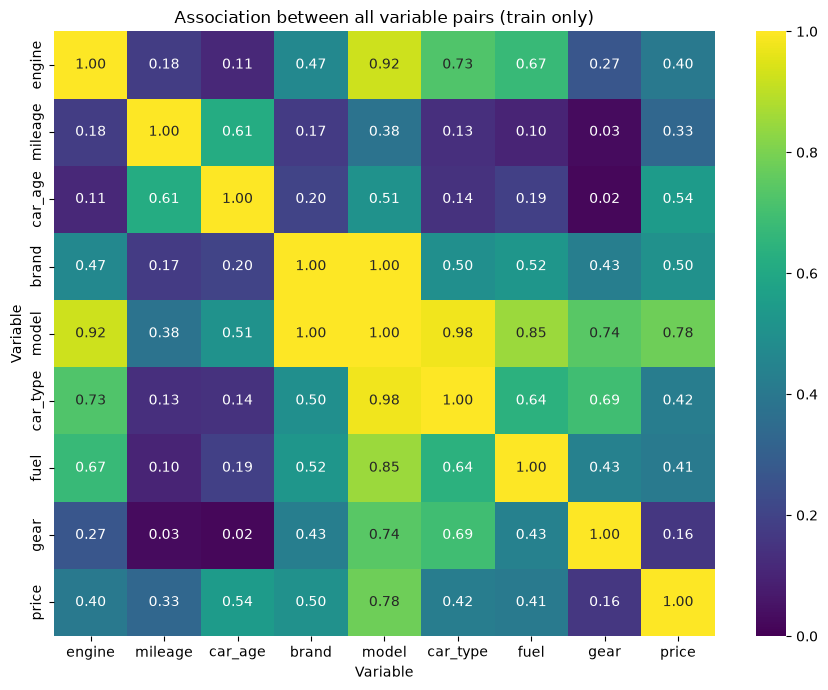

ตารางทั้ง 36 คู่ เรียงจากสัมพันธ์มากที่สุดไปน้อยที่สุด (value 0 = ไม่สัมพันธ์, 1 = สมบูรณ์)


variable 1,variable 2,method,value
brand,model,Cramér's V,1.0000
model,car_type,Cramér's V,0.9799
engine,model,η,0.9223
model,fuel,Cramér's V,0.8514
model,price,η,0.7791
model,gear,Cramér's V,0.7413
engine,car_type,η,0.7256
car_type,gear,Cramér's V,0.6923
engine,fuel,η,0.6726
car_type,fuel,Cramér's V,0.6402


In [16]:
# [16] ความสัมพันธ์ทุกคู่ (heatmap 9x9)
# ==================================================
# ทำอะไร: วัดความสัมพันธ์ของตัวแปรทุกคู่ใน train (9 ตัว = 8 ฟีเจอร์ที่โมเดลใช้ + price
#   ซึ่งเป็นค่าที่จะทำนาย ได้ 36 คู่) แล้วสรุปเป็นตาราง 9x9 (association_matrix)
#   วาดเป็น heatmap (แผนที่สี) และพิมพ์ตาราง 36 คู่เรียงจากสัมพันธ์มากไปน้อย
#   วิธีวัดเลือกตามชนิดของคู่ (อธิบายไว้ที่เซลล์ [15]):
#     ตัวเลข-ตัวเลข   -> |Spearman| (ค่าสัมบูรณ์ ตัดเครื่องหมายทิ้งให้อยู่ช่วง 0..1)
#     หมวดหมู่-หมวดหมู่ -> Cramér's V
#     หมวดหมู่-ตัวเลข  -> η (correlation ratio)
#   เส้นทแยงมุมเป็น 1 เสมอ (ตัวแปรเทียบกับตัวเอง) แต่ละคู่คำนวณครั้งเดียวแล้วเติมทั้ง 2 ฝั่ง
# ทำไม: ก่อนสร้างโมเดล ควรรู้ว่าฟีเจอร์ไหนเกี่ยวข้องกับ price มาก และฟีเจอร์ไหนซ้ำซ้อนกันเอง
#   ใช้ train เท่านั้น เพราะ val และ test ต้องเป็นข้อมูลที่ไม่เคยเห็น
#   ถ้าเอาไปคำนวณด้วย จะเท่ากับแอบดูคำตอบก่อนวัดผล (data leakage)
# ผลที่ควรเห็น: heatmap 9x9 ยิ่งสีสว่าง (ใกล้ 1) ยิ่งสัมพันธ์กันมาก แล้วตาราง 36 คู่
#   วิธีอ่าน:
#     - แถวหรือคอลัมน์ของ price บอกว่าฟีเจอร์ไหนสัมพันธ์กับราคามากที่สุด
#     - คู่ model กับ brand จะใกล้ 1 เป็นเรื่องปกติ เพราะรุ่นหนึ่งสังกัดยี่ห้อเดียว
#       ไม่ใช่ข้อมูลผิดพลาด
#     - ฟีเจอร์สองตัวสัมพันธ์กันสูง ไม่ได้ทำให้ decision tree ทำนายแย่ลง
#       แต่ทำให้บอกยากว่าฟีเจอร์ไหน "สำคัญ" จริง เพราะทั้งคู่ให้ข้อมูลซ้ำกัน
#     - ความสัมพันธ์ไม่ใช่เหตุและผล (association is not causation)
#       เช่น รถอายุมากราคาต่ำ ไม่ได้แปลว่าอายุเป็นตัวกำหนดราคาเพียงอย่างเดียว
# ข้อควรระวัง: ตัววัด 3 ชนิดไม่ได้อยู่บนสเกลเดียวกันเป๊ะ ๆ
#   จึงเทียบค่าข้ามชนิดได้แค่คร่าว ๆ เทียบในชนิดเดียวกันแม่นกว่า
# ==================================================
print("=== [16] ความสัมพันธ์ทุกคู่ (heatmap 9x9) ===")

variables = NUM_COLS + CAT_COLS + ["price"]
numeric_variables = NUM_COLS + ["price"]

association_matrix = pd.DataFrame(np.eye(len(variables)), index=variables, columns=variables)
pair_rows = []
for i in range(len(variables)):
    for j in range(i + 1, len(variables)):
        first = variables[i]
        second = variables[j]
        first_is_numeric = first in numeric_variables
        second_is_numeric = second in numeric_variables
        if first_is_numeric and second_is_numeric:
            method = "Spearman"
            value = abs(train[first].corr(train[second], method="spearman"))
        elif not first_is_numeric and not second_is_numeric:
            method = "Cramér's V"
            value = cramers_v(train[first], train[second])
        elif first_is_numeric:
            method = "η"
            value = correlation_ratio(train[second], train[first])
        else:
            method = "η"
            value = correlation_ratio(train[first], train[second])
        association_matrix.loc[first, second] = value
        association_matrix.loc[second, first] = value
        pair_rows.append(
            {"variable 1": first, "variable 2": second, "method": method, "value": value}
        )

plt.figure(figsize=(9, 7))
sns.heatmap(association_matrix, annot=True, fmt=".2f", vmin=0, vmax=1, cmap="viridis")
plt.title("Association between all variable pairs (train only)")
plt.xlabel("Variable")
plt.ylabel("Variable")
plt.tight_layout()
plt.show()

pair_table = pd.DataFrame(pair_rows).sort_values("value", ascending=False)
print("ตารางทั้ง 36 คู่ เรียงจากสัมพันธ์มากที่สุดไปน้อยที่สุด (value 0 = ไม่สัมพันธ์, 1 = สมบูรณ์)")
display(pair_table.style.format({"value": "{:.4f}"}).hide(axis="index"))

=== [17] Spearman ของตัวแปรตัวเลข ===


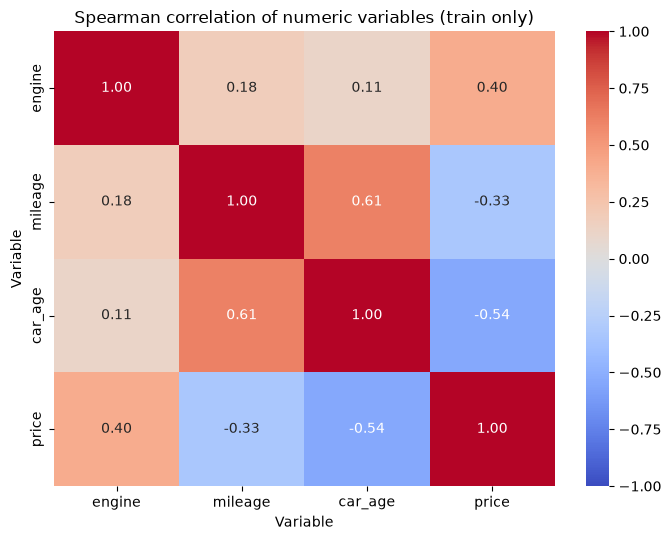

ตาราง Spearman (บวก = ไปทางเดียวกัน, ลบ = สวนทางกัน, ใกล้ 0 = ไม่มีแนวโน้มชัด)


,engine,mileage,car_age,price
engine,1.0000,0.1779,0.1103,0.4039
mileage,0.1779,1.0000,0.6145,-0.3318
car_age,0.1103,0.6145,1.0000,-0.5432
price,0.4039,-0.3318,-0.5432,1.0000


In [17]:
# [17] Spearman ของตัวแปรตัวเลข
# ==================================================
# ทำอะไร: คำนวณ Spearman ของตัวแปรตัวเลข 4 ตัว (engine, mileage, car_age, price) ใน train
#   แล้ววาด heatmap และแสดงตาราง ต่างจากเซลล์ [16] ตรงที่เก็บเครื่องหมายบวก/ลบไว้ (ช่วง -1..1)
# ทำไม: เครื่องหมายบอกทิศทางที่เซลล์ [16] (ใช้ค่าสัมบูรณ์) มองไม่เห็น
#   Spearman คือสหสัมพันธ์ของ "อันดับ" (rank) ของข้อมูล ไม่ใช่ค่าจริง จึงเลือกใช้แทน Pearson เพราะ
#     - ทนต่อค่าผิดปกติ (outlier) เช่น รถราคาสูงมากไม่กี่คัน Pearson จะถูกดึงไปมาก
#     - จับความสัมพันธ์ที่ไม่เป็นเส้นตรงแต่ไปทางเดียวกันได้ (monotonic)
#       เช่น ราคาลดลงเรื่อย ๆ เมื่อเลขไมล์เพิ่ม แม้ไม่ลดเป็นเส้นตรง
# ผลที่ควรเห็น: heatmap สีแดง-น้ำเงิน (coolwarm) พร้อมตัวเลขในช่อง แล้วตารางตัวเลขชุดเดียวกัน
#   วิธีอ่านเครื่องหมาย:
#     - บวก (สีแดง) = สองตัวนี้เพิ่มไปด้วยกัน
#     - ลบ (สีน้ำเงิน) = ตัวหนึ่งเพิ่มขณะที่อีกตัวลด
#     - ใกล้ 0 (สีขาว) = ไม่มีแนวโน้มทางเดียวกันชัดเจน
#   สิ่งที่ควรดู: (1) แถว price ว่าตัวไหนสัมพันธ์กับราคามากและทิศทางใด
#   (2) ฟีเจอร์ตัวเลขสองตัวที่สัมพันธ์กันเองสูง (เช่น car_age กับ mileage มักไปด้วยกัน)
#   ซึ่งหมายความว่าให้ข้อมูลซ้ำกันบางส่วน ควรเทียบกับผลในเซลล์ [16]
# ข้อควรระวัง: สัมพันธ์ไม่ใช่เหตุและผล และใช้ train เท่านั้นเหมือนเซลล์ [16]
# ==================================================
print("=== [17] Spearman ของตัวแปรตัวเลข ===")

spearman_table = train[NUM_COLS + ["price"]].corr(method="spearman")

plt.figure(figsize=(7, 5.5))
sns.heatmap(spearman_table, annot=True, fmt=".2f", vmin=-1, vmax=1, cmap="coolwarm")
plt.title("Spearman correlation of numeric variables (train only)")
plt.xlabel("Variable")
plt.ylabel("Variable")
plt.tight_layout()
plt.show()

print("ตาราง Spearman (บวก = ไปทางเดียวกัน, ลบ = สวนทางกัน, ใกล้ 0 = ไม่มีแนวโน้มชัด)")
display(spearman_table.style.format("{:.4f}"))

In [18]:
# [18] รายชื่อฟีเจอร์
# ==================================================
# ทำอะไร: ประกาศตัวแปร features = รายชื่อคอลัมน์ทั้งหมดที่จะป้อนให้โมเดลใช้ทายราคา
#         "ฟีเจอร์ (feature)" คือคอลัมน์ข้อมูลที่โมเดลใช้เป็นเบาะแสในการทาย
#         เช่น ปีรถ เลขไมล์ ยี่ห้อ ส่วน "ราคา" คือคำตอบที่โมเดลต้องทาย จึงไม่นับเป็นฟีเจอร์
#         ในที่นี้ใช้ NUM_COLS (ตัวเลข: engine, mileage, car_age) รวมกับ CAT_COLS
#         (หมวดหมู่: brand, model, car_type, fuel, gear) จากเซลล์ [03] รวม 8 ตัว
# ทำไม: เวอร์ชันนี้ตัดขั้น "คัดเลือกฟีเจอร์" ออกแล้ว ใช้ทุกตัวเลย เหตุผลคือ
#         1) ขั้นคัดเลือกเดิม (วัด CV MAE กับ permutation importance, backward elimination
#            และตรวจคอลัมน์ตัวเลขซ้ำ) เก็บฟีเจอร์ไว้ครบ 8 ตัวอยู่แล้ว และไม่พบคู่คอลัมน์ซ้ำ
#            การตัดขั้นนี้จึงได้ชุดฟีเจอร์เหมือนเดิม แต่ไม่ต้องฝึกโมเดลซ้ำหลายรอบ ประหยัดเวลารัน
#         2) การไม่คัดเลือก ไม่ได้พิสูจน์ว่าทุกฟีเจอร์ช่วยเสมอ ต้นไม้ตัดสินใจอาจเลือกใช้
#            ฟีเจอร์ที่ไม่มีประโยชน์เพราะความบังเอิญในข้อมูล ทำให้ทายข้อมูลใหม่แย่ลงได้
#            (เรียกว่า generalisation แย่ลง) แม้เราจะคุมขนาดต้นไม้ด้วย max_depth,
#            min_samples_leaf และ ccp_alpha อยู่แล้วก็ตาม
# ผลที่ควรเห็น: บรรทัดบอกจำนวนฟีเจอร์ และรายชื่อฟีเจอร์ทั้งหมด
#               คอลัมน์ตัวเลขมาก่อน แล้วตามด้วยหมวดหมู่
# ข้อควรระวัง: กติกานี้ต่างจากโมเดลอื่นในโปรเจกต์ที่ยังมีขั้นคัดเลือกฟีเจอร์อยู่
#              ต้องคำนึงถึงความต่างนี้ตอนเปรียบเทียบผลระหว่างโมเดล
# ==================================================
print("=== [18] รายชื่อฟีเจอร์ ===")

features = NUM_COLS + CAT_COLS

print(f"จำนวนฟีเจอร์ : {len(features)}")
print(f"รายชื่อ      : {features}")

=== [18] รายชื่อฟีเจอร์ ===
จำนวนฟีเจอร์ : 8
รายชื่อ      : ['engine', 'mileage', 'car_age', 'brand', 'model', 'car_type', 'fuel', 'gear']


In [19]:
# [19] คลาส FoldOneHot
# ==================================================
# ทำอะไร: สร้างตัวแปลงข้อมูล (คลาส FoldOneHot) ที่เปลี่ยนคอลัมน์หมวดหมู่ให้เป็นตัวเลข 0/1
#         ด้วยวิธี one-hot encoding แล้วต่อกับคอลัมน์ตัวเลขเดิม
#
#         one-hot คืออะไร: โมเดลต้นไม้ในที่นี้อ่านได้แต่ตัวเลข แต่ fuel เป็นข้อความ
#         เราจึงแตกเป็นคอลัมน์ใหม่ที่ตอบแค่ "ใช่ (1) หรือ ไม่ใช่ (0)" ต่อหนึ่งค่า
#         ตัวอย่าง fuel มี 3 ค่า Benzine / Diesel / Hybrid จะได้ 2 คอลัมน์:
#                          fuel=Diesel   fuel=Hybrid
#             รถดีเซล:          1             0
#             รถไฮบริด:        0             1
#             รถเบนซิน:        0             0      <- ศูนย์ทั้งคู่ = ค่าอ้างอิง
#
# ทำไม:
#   - ทิ้ง 1 ค่า (ระดับอ้างอิง หรือ reference level): ค่าที่เจอบ่อยที่สุดในข้อมูลฝึกจะไม่มีคอลัมน์
#     ของตัวเอง เพราะรู้ได้จากการที่คอลัมน์อื่นเป็น 0 หมด ถ้าเก็บครบทุกค่า คอลัมน์จะซ้ำซ้อนกัน
#     ถ้าความถี่เท่ากัน จะเรียงตามชื่อระดับจากน้อยไปมาก เพื่อให้ผลเหมือนเดิมทุกครั้ง
#   - เรียนรู้ (fit) ใน "แต่ละ fold": fold คือการแบ่งข้อมูลฝึกเป็นส่วนย่อย ๆ เพื่อสลับกันเป็น
#     ชุดฝึกและชุดตรวจ (cross-validation) รายชื่อระดับของแต่ละ fold จึงมาจากแถวฝึกของ fold นั้นเท่านั้น
#     ไม่แอบดูแถวที่ใช้ตรวจ ข้อมูลจึงไม่รั่ว (information leak) ผล CV จึงเชื่อถือได้
#   - ระดับที่ไม่เคยเจอตอนฝึก (unseen level) จะได้ศูนย์ทุกคอลัมน์ ไม่ทำให้โปรแกรมพัง
#   - __init__ ต้องเก็บ argument ทั้งสองตัวไว้ตามเดิมโดยไม่แก้ เพราะ sklearn ต้องสร้างสำเนาของ
#     ตัวแปลง (clone) ในทุก fold โดยอ่านค่าเหล่านี้กลับไป
#   - ในเมธอด transform ใช้การเทียบแบบ broadcasting: ดึงค่าของคอลัมน์ออกมาเป็นแนวตั้ง
#     (values[:, None]) แล้วเทียบ "ทุกแถวกับทุกระดับพร้อมกัน" ในคำสั่งเดียว
#     ได้ตารางจริง/เท็จขนาด (จำนวนแถว x จำนวนระดับ) แล้วแปลงเป็น 1/0
#     วิธีนี้เร็วกว่าวนทีละระดับมาก ซึ่งสำคัญเพราะ grid search ต้องเรียกใช้ประมาณ 1,200 ครั้ง
# ผลที่ควรเห็น: ข้อความสั้น ๆ ว่าสร้างคลาสแล้ว ยังไม่มีการแปลงข้อมูลในเซลล์นี้
#               เซลล์ที่เรียกใช้จริงคือ [22] และ pipeline ใน [25] / [28]
# ข้อควรระวัง: scale_numeric=True เรียนรู้สเกลภายในแต่ละ fold เท่านั้น
#              ผู้เรียกใช้เขียน FoldOneHot(NUM_COLS, CAT_COLS, scale_numeric=True)
# ==================================================
print("=== [19] คลาส FoldOneHot ===")


class FoldOneHot(TransformerMixin, BaseEstimator):
    """one-hot ที่เรียนรู้ระดับจากแถวที่ fit เท่านั้น (ไม่แอบดูแถวตรวจ)"""

    def __init__(self, numeric_columns, categorical_columns, scale_numeric=False):
        # เก็บไว้ตามเดิมโดยไม่แก้ เพื่อให้ sklearn clone ได้
        self.numeric_columns = numeric_columns
        self.categorical_columns = categorical_columns
        self.scale_numeric = scale_numeric

    def fit(self, X, y=None):
        """จำรายชื่อคอลัมน์ และระดับ (ไม่รวมระดับอ้างอิง) ของแต่ละคอลัมน์หมวดหมู่"""
        self.numeric_ = [c for c in X.columns if c in self.numeric_columns]
        self.categorical_ = [c for c in X.columns if c in self.categorical_columns]
        # เรียนรู้ mean/std จากแถว fit ของ fold นี้เท่านั้น ไม่แตะแถวตรวจ; dummy ไม่ถูก scale
        numeric = X[self.numeric_].astype(float)
        self.numeric_mean_ = numeric.mean()
        self.numeric_std_ = numeric.std(ddof=0).replace(0, 1.0)
        self.levels_ = {}
        for col in self.categorical_:
            counts = X[col].value_counts()
            # เรียงชื่อก่อน แล้วเรียงตามความถี่แบบ stable ชื่อจึงตัดสินเมื่อความถี่เท่ากัน
            ordered = counts.sort_index().sort_values(ascending=False, kind="stable")
            self.levels_[col] = list(ordered.index[1:])  # ตัดระดับที่พบบ่อยที่สุด = ระดับอ้างอิง
        return self

    def transform(self, X):
        """แปลงด้วยระดับที่จำไว้ตอน fit (ไม่เรียนรู้เพิ่ม)"""
        numeric = X[self.numeric_].astype(float)
        if self.scale_numeric:
            numeric = (numeric - self.numeric_mean_) / self.numeric_std_
        parts = [numeric]
        for col in self.categorical_:
            levels = self.levels_[col]
            values = X[col].to_numpy(dtype=object)
            # เทียบทุกแถวกับทุกระดับพร้อมกัน ได้ตาราง True/False ระดับที่ไม่เคยเจอจะเป็น False หมด
            matches = values[:, None] == np.asarray(levels, dtype=object)
            dummies = pd.DataFrame(
                matches.astype(float),
                index=X.index,
                columns=[f"{col}={level}" for level in levels],
            )
            parts.append(dummies)
        return pd.concat(parts, axis=1)

    def get_feature_names_out(self, input_features=None):
        """รายชื่อคอลัมน์ผลลัพธ์ตามลำดับเดียวกับ transform"""
        names = list(self.numeric_)
        for col in self.categorical_:
            names += [f"{col}={level}" for level in self.levels_[col]]
        return np.asarray(names, dtype=object)


print("สร้างคลาส FoldOneHot แล้ว")

=== [19] คลาส FoldOneHot ===
สร้างคลาส FoldOneHot แล้ว


In [20]:
# [20] ฟังก์ชัน make_model
# ==================================================
# ทำอะไร: สร้างฟังก์ชัน make_model() ที่คืนต้นไม้ตัดสินใจ (DecisionTreeRegressor) ตัวใหม่
#         พร้อมค่า hyperparameter ครบทั้ง 12 ตัว
#         hyperparameter = ค่าที่เราต้องตั้งเองก่อนให้โมเดลเรียน (โมเดลไม่ได้เรียนรู้ค่าพวกนี้จากข้อมูล)
#         เช่น ความลึกสูงสุดของต้นไม้ ส่วนสิ่งที่โมเดลเรียนเองจากข้อมูลคือเงื่อนไขแตกกิ่งในต้นไม้
# ทำไม:
#   - เขียนครบทั้ง 12 ตัว พร้อมคอมเมนต์ทุกตัว ไม่ว่าจะปรับใน grid หรือไม่ เพราะผู้ใช้ต้องการ
#     เห็นทุกค่าที่โมเดลใช้จริง ไม่ต้องไปเปิดเอกสารดูค่าเริ่มต้นเอง
#   - ตัวที่มีป้าย [grid] (max_depth, min_samples_leaf, ccp_alpha) จะถูก GridSearchCV
#     เขียนทับด้วยค่าใน PARAM_GRID ตัวอื่นใช้ค่าตามที่เขียนในฟังก์ชัน
#     random_state=SEED ทำให้ผลซ้ำได้
#   - grid ปรับแค่ 3 ตัว เพราะจำกัดขอบเขตงาน และคุมเวลารัน: ยิ่งปรับหลายพารามิเตอร์
#     จำนวนชุดใน grid ยิ่งเพิ่มแบบคูณกัน
#   - ยังไม่ได้ทดสอบ max_features, criterion="absolute_error", max_leaf_nodes,
#     min_samples_split, min_impurity_decrease จึงสรุปไม่ได้ว่าทางเลือกเหล่านี้ไม่ช่วย
#     max_features ใช้กับต้นไม้ต้นเดียวได้ ส่วนตัวควบคุมขนาดต้นไม้ตัวอื่นให้ผลต่างกัน
#     และไม่ได้ซ้ำซ้อนกันอย่างเคร่งครัด
# ผลที่ควรเห็น: ข้อความสั้น ๆ ว่าสร้างฟังก์ชันแล้ว ยังไม่ฝึกโมเดลในเซลล์นี้
# ข้อควรระวัง: make_model() ไม่รับ argument (ของเก่ารับ threads แต่ไม่เคยใช้ จึงตัดออก)
# ==================================================
print("=== [20] ฟังก์ชัน make_model ===")


def make_model():
    """สร้าง DecisionTreeRegressor ใหม่พร้อม hyperparameter ครบ 12 ตัว"""
    return DecisionTreeRegressor(
        criterion="squared_error",  # วัดคุณภาพการแตกกิ่งด้วย MSE (ค่าเริ่มต้น เหมาะกับการทายราคา)
        splitter="best",  # ลองทุกจุดตัดแล้วเลือกจุดที่ดีที่สุด ไม่สุ่ม
        max_depth=None,  # [grid] ความลึกสูงสุด None = ไม่จำกัด
        min_samples_split=2,  # รถขั้นต่ำในโหนดก่อนแตกกิ่ง (ค่าเริ่มต้น ยังไม่ได้ทดสอบการปรับ)
        min_samples_leaf=1,  # [grid] รถขั้นต่ำต่อใบ
        min_weight_fraction_leaf=0.0,  # สัดส่วนน้ำหนักขั้นต่ำต่อใบ 0 = ไม่ใช้ (ทุกแถวน้ำหนักเท่ากัน)
        max_features=None,  # ทุกการแตกกิ่งเห็นตัวแปรครบ (ใช้กับต้นไม้ต้นเดียวได้ แต่ยังไม่ได้ทดสอบ)
        random_state=SEED,  # เลขสุ่มคงที่ ใช้ตัดสินกรณีจุดตัดดีเท่ากัน ให้ผลซ้ำได้
        max_leaf_nodes=None,  # จำนวนใบสูงสุด None = ไม่จำกัด (ยังไม่ได้ทดสอบขีดจำกัดนี้)
        min_impurity_decrease=0.0,  # แตกกิ่งได้แม้ลด error น้อย (ยังไม่ได้ทดสอบเกณฑ์นี้)
        ccp_alpha=0.0,  # [grid] ค่าตัดกิ่งหลังโตเสร็จ (ค่าที่ลองเลือกจากเซลล์ [22]-[26])
        monotonic_cst=None,  # ไม่บังคับทิศทางความสัมพันธ์ของตัวแปรกับราคา
    )


print("สร้างฟังก์ชัน make_model แล้ว")

=== [20] ฟังก์ชัน make_model ===
สร้างฟังก์ชัน make_model แล้ว


In [21]:
# [21] PARAM_GRID ตั้งต้น
# ==================================================
# ทำอะไร: กำหนด PARAM_GRID = ตารางค่าที่ grid search จะลองครบทุกคู่
#         grid search = วิธีค้นหาค่า hyperparameter ที่ดี โดยลองทุกชุดผสมของค่าที่เราเตรียมไว้
#         ฝึกและวัดผลด้วย cross-validation ทีละชุด แล้วเลือกชุดที่ผ่านเกณฑ์
#         ตอนนี้มี 2 พารามิเตอร์ (max_depth 5 ค่า x min_samples_leaf 6 ค่า = 30 ชุด)
#         ส่วน ccp_alpha จะถูกเพิ่มเข้ามาในเซลล์ [26] หลังเลือกจากข้อมูลแล้ว
# ทำไม: ขยาย grid จากต้นฉบับ
#
#   | พารามิเตอร์      | ต้นฉบับ            | ตอนนี้                           |
#   |------------------|--------------------|----------------------------------|
#   | max_depth        | 20, None           | 10, 15, 20, 25, None             |
#   | min_samples_leaf | 1, 5, 10           | 1, 5, 7, 9, 12, 15               |
#   | ccp_alpha        | 0, 1e6, 3e6, 1e7   | เลือกจากข้อมูลในเซลล์ [22]-[26]  |
#
#   เหตุผลของแต่ละ grid
#   - max_depth และ min_samples_leaf (5-15): ใช้ค่าตามที่ผู้ใช้กำหนด
#     (max_depth = ความลึกสูงสุดของต้นไม้ None = ไม่จำกัด,
#      min_samples_leaf = จำนวนรถขั้นต่ำต่อใบ ค่ามากทำให้ต้นไม้เล็กลง)
#   - min_samples_leaf=1: เพิ่มตามคำแนะนำ เพราะรอบเดิมชนะที่ค่านี้
#   - ccp_alpha: ผู้ใช้สั่งให้คัดเลือกจากข้อมูลก่อน แล้วค่อยใส่ลง grid (ดูเซลล์ [22]-[26])
# ผลที่ควรเห็น: แสดง grid ปัจจุบัน และจำนวนชุดที่ผสมได้ในตอนนี้ (30 ชุด)
# ข้อควรระวัง: ผู้ชนะไม่ได้เลือกจาก CV MAE ต่ำสุด แต่เลือกด้วยกฎ 1-SE ในเซลล์ [28]-[33]
#              (เลือกต้นไม้ที่เล็กที่สุดในกลุ่มที่ผลไม่ต่างจากที่ดีที่สุดเกินความคลาดเคลื่อน)
#              ตารางอันดับในเซลล์ถัด ๆ ไปจะมีเครื่องหมาย * ที่แถวผู้ชนะตามกฎ 1-SE ซึ่งอาจไม่ใช่
#              อันดับ 1 ไม่ต้องเลือกชุดที่ต้นไม้เล็กกว่าเองจากตาราง
# ==================================================
print("=== [21] PARAM_GRID ตั้งต้น ===")

PARAM_GRID = {
    "max_depth": [10, 15, 20, 25, None],
    "min_samples_leaf": [1, 5, 7, 9, 12, 15],
}

combinations = 1
for values in PARAM_GRID.values():
    combinations = combinations * len(values)

print(f"PARAM_GRID ตอนนี้       : {PARAM_GRID}")
print(f"จำนวนชุดที่ผสมได้ตอนนี้ : {combinations} (ccp_alpha ยังไม่รวม จะเพิ่มในเซลล์ [26])")

=== [21] PARAM_GRID ตั้งต้น ===
PARAM_GRID ตอนนี้       : {'max_depth': [10, 15, 20, 25, None], 'min_samples_leaf': [1, 5, 7, 9, 12, 15]}
จำนวนชุดที่ผสมได้ตอนนี้ : 30 (ccp_alpha ยังไม่รวม จะเพิ่มในเซลล์ [26])


In [22]:
# [22] ccp 1: pruning path จาก train
# ==================================================
# ทำอะไร: เริ่มขั้นตอน "เลือก ccp_alpha จากข้อมูล" (เซลล์ [22]-[27]) โดยหา pruning path
#         ของต้นไม้เต็มที่ฝึกบนชุด train
#
#         pruning (การตัดกิ่ง) คืออะไร: ต้นไม้ที่โตเต็มที่จะจำข้อมูลฝึกได้เกือบหมด
#         (overfit = เก่งกับข้อมูลที่เคยเห็น แต่ทายข้อมูลใหม่ไม่แม่น) เราจึงตัดกิ่งที่ไม่คุ้มออก
#         ccp_alpha คือ "ค่าปรับ" ต่อหนึ่งใบของต้นไม้ ยิ่ง alpha มาก กิ่งที่ถูกตัดยิ่งมาก
#         ได้ต้นไม้เล็กลงและเรียบง่ายขึ้น (ถ้าเล็กเกินไปจะ underfit = เรียบง่ายจนจับรูปแบบไม่ทัน)
#         ccp_alpha = 0 คือไม่ตัดกิ่งเลย
#         pruning path คือรายการค่า alpha ทุกค่าที่ทำให้ต้นไม้ถูกตัดเพิ่มทีละขั้น
#         ได้มาจาก cost_complexity_pruning_path
#
#         ภาพรวมของวิธี (เซลล์ [22]-[27]):
#           [22] หา alpha ที่เป็นไปได้ทั้งหมดจาก train
#           [23] เก็บเฉพาะ alpha ที่ต้นไม้ยังเหลือมากกว่า MIN_LEAVES (20) ใบ
#           [24] เลือกตัวเลือกประมาณ CCP_N_CANDIDATES (20) ตัว ให้เว้นระยะเท่า ๆ กันบนสเกล log
#           [25] วัด CV MAE ของแต่ละตัวเลือก ด้วย fold เดิม
#           [26] เอาตัวที่ดีที่สุดกับเพื่อนบ้าน และ 0 ใส่ลง PARAM_GRID
#           [27] วาดกราฟดูผล
# ทำไม: ต้นไม้ฝึก log(price) จึงหา alpha จาก log(price); MAE ที่ให้คะแนนยังเป็นบาท
#         alpha อยู่บนสเกล log-target และแกน x แบบ log เลือกขอบจากข้อมูลเอง
#         เดาเองไม่ได้ ต้องหาจากข้อมูลจริง (ใช้เฉพาะ train ไม่แตะ val และ test)
# ผลที่ควรเห็น: จำนวน alpha ที่เป็นบวกที่ไม่ซ้ำกัน พร้อมค่าน้อยที่สุดและมากที่สุด
#               ยิ่งข้อมูลซับซ้อน ยิ่งมี alpha หลายค่า
# ข้อควรระวัง (ข้อจำกัดของวิธีนี้ ใช้กับเซลล์ [22]-[26] ทั้งหมด):
#   - ตัวเลข 20 ใบ, 1e-6 x ค่าสูงสุด, CCP_N_CANDIDATES และเพื่อนบ้าน +-3 เป็น heuristic
#     (กฎที่ตั้งจากความสมเหตุสมผล) เพื่อจำกัดเวลารัน ยังไม่ได้ยืนยันว่าเป็นขอบเขตหรือความละเอียดที่ดีที่สุด
#   - CV MAE ของโมเดลที่ปรับแล้วอาจดีเกินจริงเล็กน้อย เพราะสร้างและคัดกรอง alpha บน train
#     ทั้งชุด ซึ่งรวมแถวที่แต่ละ fold จะกันไว้ภายหลัง (แม้ encoder จะ fit ภายใน fold
#     ตอนให้คะแนนก็ตาม) การตรวจที่ไม่เอนเอียงคือ test ที่กันไว้ยังไม่แตะ (รวมถึง val)
#   - nested CV จะตัด bias นี้ออกได้ แต่ไม่ได้ทำ เพราะใช้เวลาประมาณ 5 เท่า ตัวเลข 5 เท่าเป็น
#     ประมาณการ ไม่ใช่ผลวัดเวลาจริงของ notebook นี้
#   - เซลล์ [38] จะตรวจความไวต่อ alpha แบบหยาบในช่วงกว้างที่พารามิเตอร์ของผู้ชนะ
#     โดยไม่ปรับผู้ชนะตามผลนั้น
#   - ที่มาของโค้ด: gpt-6.1-sol เขียน และ Claude แก้ขอบล่างของช่วง log
# ==================================================
print("=== [22] ccp 1: pruning path จาก train ===")

encoded_train = FoldOneHot(NUM_COLS, CAT_COLS, scale_numeric=True).fit_transform(train[features])
train_prices = train["price"].to_numpy()  # เก็บบาทสำหรับ CV และ pipeline
pruning_prices = np.log(train_prices)  # pruning path ใช้เป้าหมาย log เช่นเดียวกับต้นไม้ใน pipeline

pruning_path = DecisionTreeRegressor(random_state=SEED).cost_complexity_pruning_path(
    encoded_train,
    pruning_prices,
)
# เก็บเฉพาะค่าบวก ไม่ซ้ำ (0 = ไม่ตัดกิ่ง ใช้สเกล log ไม่ได้)
positive_alphas = np.unique(pruning_path.ccp_alphas[pruning_path.ccp_alphas > 0])

print(f"จำนวน alpha ที่เป็นบวก (ไม่ซ้ำ) : {len(positive_alphas):,}")
print(f"alpha ที่น้อยที่สุด             : {positive_alphas[0]:.3e}")
print(f"alpha ที่มากที่สุด              : {positive_alphas[-1]:.3e}")

=== [22] ccp 1: pruning path จาก train ===


จำนวน alpha ที่เป็นบวก (ไม่ซ้ำ) : 17,587
alpha ที่น้อยที่สุด             : 7.559e-19
alpha ที่มากที่สุด              : 6.806e-02


In [23]:
# [23] ccp 2: alpha ที่ต้นไม้ยังมีมากกว่า 20 ใบ
# ==================================================
# ทำอะไร: เก็บเฉพาะ alpha ที่ตัดกิ่งแล้วต้นไม้ยังเหลือใบมากกว่า MIN_LEAVES (20) ใบ
#         "ใบ (leaf)" คือปลายสุดของต้นไม้ที่ให้คำตอบ (ราคาที่ทาย) ใบยิ่งน้อย ต้นไม้ยิ่งเล็ก
#         ฟังก์ชัน count_leaves(alpha) ฝึกต้นไม้ที่ alpha นั้นบน train ทั้งชุด แล้วนับใบ
#         (เก็บผลไว้ใน leaf_cache จะได้ไม่ฝึกซ้ำ)
# ทำไม:
#   - ตัดตัวเลือกที่ตัดกิ่งมากจนเหลือไม่เกิน 20 ใบทิ้ง เพราะต้นไม้เล็กขนาดนั้นเรียบง่ายเกินไป
#     (20 ใบเป็น heuristic เพื่อจำกัดเวลารัน ไม่ใช่ขอบเขตที่ตรวจสอบแล้ว)
#   - วิธีหาขอบเขต: alpha ยิ่งมาก ต้นไม้ยิ่งเล็ก จำนวนใบจึงไม่มีทางเพิ่มขึ้นเมื่อ alpha มากขึ้น
#     ดังนั้น alpha ที่เหลือมากกว่า MIN_LEAVES ใบ คือ "ชุดแรก" ของรายการที่เรียงน้อยไปมากเสมอ
#     เราจึงเริ่มจาก alpha ที่ใหญ่ที่สุด แล้วถอยลงทีละตัวจนเจอตัวแรกที่ยังเหลือเกิน MIN_LEAVES ใบ
#     ผลเหมือนการค้นหาแบบ binary search ที่เวอร์ชันเก่าใช้ทุกประการ (ได้ขอบเขตเดียวกัน)
#     แต่อ่านง่ายกว่า
# ผลที่ควรเห็น: alpha ขอบเขตและจำนวนใบของมัน, จำนวน alpha ที่เก็บไว้ และจำนวนต้นไม้ที่ฝึกจริง
#               จำนวนต้นไม้ที่ฝึกน้อยกว่าจำนวน alpha ทั้งหมดมาก เพราะฝึกเฉพาะ alpha ที่ตรวจ
# ข้อควรระวัง: alpha ที่ต่ำกว่าขอบล่างที่จะใช้ในเซลล์ [24] ไม่ได้เป็น "เศษทศนิยม" ที่ไม่มีผล
#              มันอาจตัดใบจำนวนมากได้ ขนาดของ alpha ขึ้นกับข้อมูลและหน่วยของราคา
#              จึงไม่ควรอ้างว่าค่าที่ตัดทิ้งมีผลน้อยมาก
# ==================================================
print("=== [23] ccp 2: alpha ที่ต้นไม้ยังมีมากกว่า 20 ใบ ===")

leaf_cache = {}


def count_leaves(alpha):
    """ฝึกต้นไม้ที่ ccp_alpha นี้บน train แล้วคืนจำนวนใบ (จำผลไว้ ไม่ฝึกซ้ำ)"""
    if float(alpha) not in leaf_cache:
        tree = DecisionTreeRegressor(random_state=SEED, ccp_alpha=float(alpha))
        tree.fit(encoded_train, pruning_prices)
        leaf_cache[float(alpha)] = int(tree.get_n_leaves())
    return leaf_cache[float(alpha)]


# ถอยจาก alpha ใหญ่สุดลงมา จนเจอตัวแรกที่ต้นไม้ยังมีใบมากกว่า MIN_LEAVES
cut = len(positive_alphas)
while count_leaves(positive_alphas[cut - 1]) <= MIN_LEAVES:
    cut = cut - 1
over_min_alphas = positive_alphas[:cut]

boundary_alpha = over_min_alphas[-1]
print(f"alpha ขอบเขต (ใหญ่สุดที่ยังเกิน {MIN_LEAVES} ใบ) : {boundary_alpha:.3e}")
print(f"จำนวนใบที่ alpha ขอบเขต                  : {count_leaves(boundary_alpha):,}")
print(f"จำนวน alpha ที่เก็บไว้                   : {len(over_min_alphas):,}")
print(f"จำนวนต้นไม้ที่ฝึกเพื่อนับใบ              : {len(leaf_cache):,}")

=== [23] ccp 2: alpha ที่ต้นไม้ยังมีมากกว่า 20 ใบ ===


alpha ขอบเขต (ใหญ่สุดที่ยังเกิน 20 ใบ) : 1.918e-03
จำนวนใบที่ alpha ขอบเขต                  : 21
จำนวน alpha ที่เก็บไว้                   : 17,568
จำนวนต้นไม้ที่ฝึกเพื่อนับใบ              : 20


In [24]:
# [24] ccp 3: เลือกตัวเลือกบนสเกล log
# ==================================================
# ทำอะไร: เลือก alpha ประมาณ CCP_N_CANDIDATES (20) ตัวจาก over_min_alphas ให้กระจายเท่า ๆ กันบน
#         สเกล log แล้วเก็บเป็น candidate_alphas
#         ขั้นตอน
#           1) ขอบล่าง low = ค่ามากกว่าระหว่าง "alpha ตัวแรกที่ผ่าน" กับ "1e-6 x alpha สูงสุด"
#           2) สร้างเป้าหมาย 20 ค่าเว้นระยะเท่ากันระหว่าง log(low) ถึง log(alpha สูงสุด)
#           3) แต่ละเป้าหมาย หา alpha ที่ใกล้ที่สุดบนสเกล log (ใช้ alpha ที่มีอยู่จริงในเส้นทางเท่านั้น
#              ไม่สร้างค่าใหม่)
#           4) ตัดค่าซ้ำ
#         สเกล log คืออะไร: alpha กระจายตั้งแต่เลขเล็กมากถึงใหญ่มาก (หลายหลัก) ถ้าเว้นระยะเท่ากัน
#         แบบปกติ ตัวเลือกเกือบทั้งหมดจะไปกองอยู่ฝั่งค่าใหญ่ ส่วน log นับ "จำนวนหลัก" แทน
#         เช่น 10, 100, 1,000, 10,000 ห่างกันเท่า ๆ กันบนสเกล log (ทุกขั้นคูณ 10)
#         ทำให้ได้ตัวเลือกกระจายทุกช่วงขนาด
# ทำไม: ขอบล่าง 1e-6 x ค่าสูงสุด เป็น heuristic เพื่อจำกัดช่วงและเวลารัน ค่าที่ตัดทิ้งอาจ
#         เปลี่ยนจำนวนใบได้ ยังไม่ได้ยืนยันว่าเหมาะที่สุด ส่วนการเลือก "ตัวที่ใกล้ที่สุด" ใช้
#         np.argmin ซึ่งคืนตัวแรกเมื่อเสมอกัน ได้ผลเหมือน argmin(axis=0) ที่เวอร์ชันเก่าใช้
# ผลที่ควรเห็น: จำนวนตัวเลือกที่ได้ อาจน้อยกว่า 20 ได้ เพราะบางเป้าหมายเลือกตัวเดียวกัน
#               แล้วถูกตัดซ้ำ
# ==================================================
print("=== [24] ccp 3: เลือกตัวเลือกบนสเกล log ===")

low = max(over_min_alphas[0], over_min_alphas[-1] * 1e-6)
targets = np.linspace(np.log(low), np.log(over_min_alphas[-1]), CCP_N_CANDIDATES)

collected = []
for target in targets:
    position = np.argmin(np.abs(np.log(over_min_alphas) - target))  # ตัวที่ใกล้เป้าหมายที่สุด
    collected.append(over_min_alphas[position])
candidate_alphas = np.unique(collected)

print(f"ขอบล่างของ alpha      : {low:.3e}")
print(f"ขอบบนของ alpha        : {over_min_alphas[-1]:.3e}")
print(f"จำนวนเป้าหมาย         : {CCP_N_CANDIDATES}")
print(f"จำนวนตัวเลือกที่ได้   : {len(candidate_alphas)} (ตัดค่าซ้ำแล้ว)")

=== [24] ccp 3: เลือกตัวเลือกบนสเกล log ===
ขอบล่างของ alpha      : 1.918e-09
ขอบบนของ alpha        : 1.918e-03
จำนวนเป้าหมาย         : 20
จำนวนตัวเลือกที่ได้   : 20 (ตัดค่าซ้ำแล้ว)


In [25]:
# [25] ccp 4: CV MAE ของแต่ละตัวเลือก
# ==================================================
# ทำอะไร: ให้คะแนนตัวเลือก alpha แต่ละตัวด้วย cross-validation (CV) แล้วเก็บเป็นตาราง ccp_table
#         คอลัมน์: alpha, cv_mae (ค่าเฉลี่ย MAE ข้าม fold), leaves (จำนวนใบของต้นไม้ที่ฝึกบน train ทั้งชุด)
#
#         MAE (Mean Absolute Error) = ค่าเฉลี่ยของ "ราคาที่ทายผิดไปกี่บาท" (ไม่สนใจว่าสูงหรือต่ำไป)
#         ยิ่งน้อยยิ่งดี
#         cross-validation = แบ่งข้อมูลฝึกเป็น N_FOLDS ส่วน (fold) สลับกันเอา 1 ส่วนไว้ตรวจ
#         ที่เหลือใช้ฝึก แล้วเฉลี่ยคะแนน ได้คะแนนที่นิ่งกว่าการตรวจครั้งเดียว
# ทำไม:
#   - ใช้ folds ตัวเดิมจากเซลล์ [14] ทุกครั้ง ทุกตัวเลือกจึงถูกตรวจบนการแบ่งข้อมูลชุดเดียวกัน
#     เทียบกันได้แฟร์ และตรงกับ grid search ที่จะทำทีหลัง
#   - ใส่ FoldOneHot ไว้ใน Pipeline เพื่อให้แต่ละ fold เรียนรู้การเข้ารหัสจากแถวฝึกของตัวเอง
#     ข้อมูลตรวจจึงไม่รั่วเข้าไป
#   - ตั้ง max_depth=None, min_samples_leaf=1 เพื่อดูผลของ alpha อย่างเดียว ไม่ปนกับพารามิเตอร์อื่น
#   - ไม่ใช้ val หรือ test ในขั้นนี้
#   - n_jobs ใช้ SEARCH_JOBS เพื่อรัน fold ขนานกัน
# ผลที่ควรเห็น: ตารางเรียงตาม alpha จากน้อยไปมาก ดูคอลัมน์ cv_mae ว่าตัวเลือกไหนต่ำที่สุด
#               (ดีที่สุด) และคอลัมน์ leaves ว่าต้นไม้เล็กลงตาม alpha ที่มากขึ้น
# ข้อควรระวัง: เซลล์นี้ใช้เวลาพอสมควร เพราะฝึกต้นไม้ (จำนวนตัวเลือก x N_FOLDS) ต้น
# ==================================================
print("=== [25] ccp 4: CV MAE ของแต่ละตัวเลือก ===")

rows = []
for alpha in candidate_alphas:
    candidate_pipeline = Pipeline([
        ("encode", FoldOneHot(NUM_COLS, CAT_COLS, scale_numeric=True)),
        ("model", TransformedTargetRegressor(regressor=DecisionTreeRegressor(
            random_state=SEED,
            ccp_alpha=float(alpha),
            max_depth=None,
            min_samples_leaf=1,
        ), func=np.log, inverse_func=np.exp)),
    ])
    scores = cross_val_score(
        candidate_pipeline,
        train[features],
        train_prices,
        cv=folds,
        scoring="neg_mean_absolute_error",
        n_jobs=SEARCH_JOBS,
        pre_dispatch=SEARCH_JOBS,
        error_score="raise",
    )
    cv_mae = -scores.mean()
    rows.append({"alpha": float(alpha), "cv_mae": float(cv_mae), "leaves": count_leaves(alpha)})
ccp_table = pd.DataFrame(rows)

print("อ่านตาราง: alpha ยิ่งมาก ต้นไม้ยิ่งเล็ก (leaves ลด) แถวที่ cv_mae ต่ำสุดคือตัวเลือกที่ดีที่สุด")
display(
    ccp_table.style
    .format({"alpha": "{:.3e}", "cv_mae": "{:,.0f}", "leaves": "{:,.0f}"})
    .hide(axis="index")
)

=== [25] ccp 4: CV MAE ของแต่ละตัวเลือก ===


อ่านตาราง: alpha ยิ่งมาก ต้นไม้ยิ่งเล็ก (leaves ลด) แถวที่ cv_mae ต่ำสุดคือตัวเลือกที่ดีที่สุด


alpha,cv_mae,leaves
1.916e-09,"62,679","23,323"
3.970e-09,"62,680","22,722"
8.209e-09,"62,681","21,872"
1.701e-08,"62,702","20,627"
3.516e-08,"62,710","18,782"
7.275e-08,"62,603","16,427"
1.505e-07,"62,303","13,580"
3.115e-07,"61,535","10,090"
6.443e-07,"60,251","6,428"
1.334e-06,"58,423","3,479"


In [26]:
# [26] ccp 5: ใส่ค่าที่เลือกลง PARAM_GRID
# ==================================================
# ทำอะไร: หาตัวเลือกที่ CV MAE ต่ำสุด แล้วใส่ตัวนั้นพร้อมเพื่อนบ้านซ้าย-ขวาอีก CCP_NEIGHBOURS (3) ตัว
#         และค่า 0 ลงใน PARAM_GRID["ccp_alpha"]
# ทำไม:
#   - เก็บเพื่อนบ้าน: ค่าที่ดีที่สุดจริงอาจอยู่ใกล้ ๆ ตัวที่ชนะ การลองรอบ ๆ ตัวชนะจึงเป็นการ
#     ละเอียดขึ้นเฉพาะจุดที่น่าสนใจ โดยไม่ต้องลองทุกตัวเลือก (ประหยัดเวลารัน)
#   - เก็บ 0 ไว้เสมอ: 0 = ไม่ตัดกิ่ง เป็นจุดเทียบว่าการตัดกิ่งช่วยจริงหรือไม่ และกันกรณี
#     ที่ไม่ตัดดีที่สุด
#   - ถ้า CV MAE เท่ากันหลายตัว argmin จะเลือกตัวแรก คือ alpha ที่เล็กกว่า
#   - ใช้ float ธรรมดาและเรียงลำดับ ไม่ซ้ำ เพื่อให้ grid search รับได้ตรง ๆ
#   - จำนวนเพื่อนบ้านเป็น heuristic เพื่อจำกัดเวลารัน
# ผลที่ควรเห็น: รายการ alpha ที่เลือก (รูป .3e) และขนาด grid ทั้งหมดหลังเพิ่ม ccp_alpha
#               ขนาด grid = 5 (max_depth) x 6 (min_samples_leaf) x จำนวน ccp_alpha
# ==================================================
print("=== [26] ccp 5: ใส่ค่าที่เลือกลง PARAM_GRID ===")

best_position = int(ccp_table["cv_mae"].argmin())
first = max(0, best_position - CCP_NEIGHBOURS)
last = best_position + CCP_NEIGHBOURS + 1
neighbours = candidate_alphas[first:last]
PARAM_GRID["ccp_alpha"] = sorted(set(float(a) for a in [0.0] + list(neighbours)))

grid_size = 1
for values in PARAM_GRID.values():
    grid_size = grid_size * len(values)

print(f"ตัวเลือกที่ CV MAE ต่ำสุด : {candidate_alphas[best_position]:.3e}")
print("ccp_alpha ที่ใส่ใน PARAM_GRID:")
for alpha in PARAM_GRID["ccp_alpha"]:
    print(f"  {alpha:.3e}")
print(f"ขนาด grid ทั้งหมด         : {grid_size} ชุด")

=== [26] ccp 5: ใส่ค่าที่เลือกลง PARAM_GRID ===
ตัวเลือกที่ CV MAE ต่ำสุด : 2.759e-06
ccp_alpha ที่ใส่ใน PARAM_GRID:
  0.000e+00
  3.115e-07
  6.443e-07
  1.334e-06
  2.759e-06
  5.710e-06
  1.184e-05
  2.443e-05
ขนาด grid ทั้งหมด         : 240 ชุด


=== [27] ccp 6: กราฟ ===


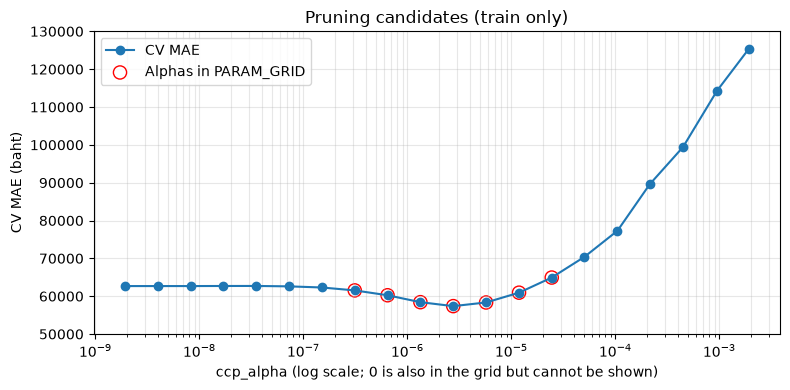

In [27]:
# [27] ccp 6: กราฟ
# ==================================================
# ทำอะไร: วาดกราฟ CV MAE ของแต่ละตัวเลือก alpha (แกน x เป็นสเกล log) และวงกลมสีแดงล้อมตัวที่
#         ถูกใส่ลง PARAM_GRID ในเซลล์ [26]
# ทำไม: ดูภาพรวมได้ง่ายกว่าตาราง และตรวจได้ว่าตัวที่เลือกอยู่ตรงจุดต่ำสุดของเส้นจริงหรือไม่
# ผลที่ควรเห็น: เส้นรูปตัว U (มักเป็นแบบนี้)
#   - ฝั่งซ้าย (alpha น้อย): ต้นไม้ใหญ่และซับซ้อนเกิน จำข้อมูลฝึก (overfit) CV MAE จึงสูง
#   - ฝั่งขวา (alpha มาก): ต้นไม้เล็กและเรียบง่ายเกิน จับรูปแบบไม่ทัน (underfit) CV MAE จึงสูงขึ้นอีก
#   - ก้นตัว U คือช่วง alpha ที่สมดุลที่สุด วงกลมสีแดงควรอยู่รอบก้นนี้
#   - แกนถูกล็อกด้วยค่าคงที่ใน [03] (MAE_CCP_AXIS) เหมือนกันทั้ง DT / RF / XGB จึงเทียบความสูงข้ามโน้ตบุ๊คได้ตรงๆ
# ข้อควรระวัง: ตัวเลือก 0 อยู่ใน grid ด้วย แต่วาดบนแกน log ไม่ได้ จึงไม่ปรากฏในกราฟ
#              ข้อความในกราฟเป็นภาษาอังกฤษ เพราะฟอนต์ของกราฟอาจไม่มีตัวอักษรไทย (กติกาของโน้ตบุ๊คชุดนี้)
#   - ถ้ามีค่านอกแกนที่ล็อกไว้ จะพิมพ์ WARN หลังกราฟ (ไม่ตัดทิ้งเงียบๆ) ให้ขยาย MAE_CCP_AXIS ใน [03] ให้เหมือนกันทั้ง 3 โน้ตบุ๊ค
# ==================================================
print("=== [27] ccp 6: กราฟ ===")

selected = ccp_table[ccp_table["alpha"].isin(PARAM_GRID["ccp_alpha"])]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(ccp_table["alpha"], ccp_table["cv_mae"], "o-", label="CV MAE")
ax.scatter(
    selected["alpha"],
    selected["cv_mae"],
    s=90,
    facecolors="none",
    edgecolors="red",
    label="Alphas in PARAM_GRID",
)
ax.set_xscale("log")
ax.set_xlabel("ccp_alpha (log scale; 0 is also in the grid but cannot be shown)")
ax.set_ylabel("CV MAE (baht)")
ax.set_title("Pruning candidates (train only)")
ax.set_ylim(*MAE_CCP_AXIS)
ax.grid(True, which="both", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

if ccp_table["cv_mae"].min() < MAE_CCP_AXIS[0] or ccp_table["cv_mae"].max() > MAE_CCP_AXIS[1]:
    print("WARN: ค่าบางจุดอยู่นอกแกนที่ล็อกไว้ (ccp 6 กราฟ) ให้ขยาย MAE_CCP_AXIS ในเซลล์ [03]")

In [28]:
# [28] Pipeline และฟังก์ชันนับใบ
# ==================================================
# ทำอะไร: ต่อขั้นตอน "แปลงข้อมูล -> โมเดล" เป็น Pipeline ชุดเดียว
#         แล้วสร้างฟังก์ชัน count_pipeline_leaves(params) ที่ฝึกต้นไม้ด้วยพารามิเตอร์ที่ให้มา
#         และบอกว่าต้นไม้นั้นมีกี่ใบ (leaf)
# ทำไม:
#   - Pipeline คือสายพานต่อขั้นตอนเข้าด้วยกัน ที่นี่มี 2 ขั้น ชื่อ "encode" (FoldOneHot จากเซลล์ [19])
#     และ "model" (ต้นไม้จาก make_model ในเซลล์ [20]) ชื่อทั้งสองต้องคงไว้ เพราะ grid ใช้ prefix
#     "model__regressor__" ชี้เข้าไปตั้งค่าพารามิเตอร์ของต้นไม้ (เช่น model__regressor__max_depth)
#   - ใน CV ทุก fold จะ fit Pipeline ใหม่ทั้งสาย ทำให้ encoder เรียนรู้จากแถวฝึกของ fold นั้นเท่านั้น
#     ข้อมูลฝั่งตรวจจึงไม่รั่วเข้ามา
#   - ใบ (leaf) คือปลายสุดของต้นไม้ที่ให้คำตอบ ยิ่งมีใบมากต้นไม้ยิ่งซับซ้อนและจำข้อมูลฝึกได้ละเอียด
#     จำนวนใบจึงใช้วัดความเรียบง่ายได้ตรงตัว (ใบน้อย = เรียบง่าย) ซึ่งเป็นแนวคิดของ CART
#   - ที่ต้องมี cache (leaf_counts) เพราะชุดเดียวกันถูกนับใบหลายครั้ง ในเซลล์ [29], [33] และ [40]
#     การฝึกต้นไม้ใหม่ทุกครั้งเปลืองเวลา จึงนับครั้งเดียวแล้วจำค่าไว้
# ผลที่ควรเห็น: พิมพ์ชื่อเซลล์ และบอกว่าสร้าง pipeline กับฟังก์ชันแล้ว ยังไม่มีตัวเลขผลลัพธ์
# ข้อควรระวัง: การนับใบฝึกจาก train ทั้งชุดเท่านั้น ไม่แตะ validation หรือ test
#         และใช้ clone เพื่อสร้างสำเนา จึงไม่กระทบ pipeline ต้นแบบ
# ==================================================
print("=== [28] Pipeline และฟังก์ชันนับใบ ===")

pipeline = Pipeline([
    ("encode", FoldOneHot(NUM_COLS, CAT_COLS, scale_numeric=True)),
    ("model", TransformedTargetRegressor(regressor=make_model(), func=np.log, inverse_func=np.exp)),
])
leaf_counts = {}


def count_pipeline_leaves(params):
    """ฝึก pipeline ตาม params บน train ทั้งชุด แล้วคืนจำนวนใบ (จำค่าไว้ใน cache)"""
    key = tuple(sorted(params.items()))
    if key not in leaf_counts:
        fitted = clone(pipeline).set_params(**params)
        fitted.fit(train[features], train_prices)
        leaf_counts[key] = int(fitted.named_steps["model"].regressor_.get_n_leaves())
    return leaf_counts[key]


print("สร้าง pipeline และฟังก์ชัน count_pipeline_leaves แล้ว")

=== [28] Pipeline และฟังก์ชันนับใบ ===
สร้าง pipeline และฟังก์ชัน count_pipeline_leaves แล้ว


In [29]:
# [29] ฟังก์ชันกฎ 1-SE
# ==================================================
# ทำอะไร: สร้างฟังก์ชัน select_1se ที่รับผลของ GridSearchCV (cv_results) แล้วคืน "ลำดับ index"
#         ของชุดพารามิเตอร์ที่ชนะตามกฎ 1-SE และ refit_1se ที่เป็นตัวห่อสำหรับ GridSearchCV
# แนวคิด (เปรียบเทียบง่าย ๆ): ลองนึกถึงการเลือกร้านอาหารที่คะแนนรีวิวต่างกันนิดเดียว
#         ถ้าร้านที่คะแนนสูงสุดได้ 4.80 และร้านอื่นต่างกันไม่เกินความผันผวนปกติของคะแนน
#         ก็ถือว่า "ดีพอ ๆ กัน" เราจึงเลือกร้านที่เมนูน้อยและเรียบง่ายที่สุดในกลุ่มนั้น
#         เหมือนกัน ถ้าต้นไม้หลายแบบให้ error เกือบเท่ากัน ให้เลือกต้นไม้ที่เรียบง่ายที่สุด
#         เพราะมักทำนายข้อมูลใหม่ได้เสถียรกว่า
# หลักการ: มาจาก Breiman, Friedman, Olshen & Stone, Classification and Regression Trees (1984)
#         และ Hastie, Tibshirani & Friedman, The Elements of Statistical Learning, ฉบับที่ 2,
#         §7.10 หน้า 244 คือเลือกต้นไม้ที่เรียบง่ายที่สุดในช่วงหนึ่ง SE ของความผิดพลาดต่ำสุด
#         เป็น heuristic ไม่ใช่การพิสูจน์ว่าสองชุดเท่ากันทางสถิติ
#         อ้างอิง:
#           CART (1984), สำนักพิมพ์:
#             https://www.routledge.com/Classification-and-RegressionTrees/Breiman-Friedman-Stone-Olshen/p/book/9780412048418
#           ESL ฉบับที่ 2, เว็บไซต์ผู้เขียนและหนังสือ:
#             https://hastie.su.domains/ElemStatLearn/main.html
# ขั้นตอนของกฎ:
#   1. CV MAE = -mean_test_MAE (sklearn เก็บเป็นค่าติดลบ จึงกลับเครื่องหมายให้เป็นบาทบวก)
#   2. หาชุดที่ CV MAE ต่ำสุด (ถ้าเสมอ ใช้ index แรก)
#   3. เกณฑ์ (threshold) = CV MAE ต่ำสุด + std_test_MAE ของชุดนั้น / sqrt(n_splits)
#      std คือส่วนเบี่ยงเบนมาตรฐานของคะแนนแต่ละ fold, n_splits คือจำนวน fold
#      (นับจากชื่อ split0_test_MAE, split1_test_MAE, ...) ส่วน SE = std / sqrt(n_splits)
#      sd ของ sklearn คำนวณแบบ ddof=0 (หารด้วย n ไม่ใช่ n-1)
#   4. ทุกชุดที่ CV MAE ไม่เกินเกณฑ์ ถือว่า eligible (มีสิทธิ์ถูกเลือก)
#   5. ฝึกต้นไม้ของแต่ละชุด eligible ใหม่บน train ทั้งชุดเพื่อนับใบ (count_pipeline_leaves จากเซลล์ [28])
#   6. ลำดับตัดสิน: จำนวนใบน้อยสุดก่อน -> ถ้าเสมอดู CV MAE ต่ำกว่า -> ถ้ายังเสมอดู index ต่ำกว่า
# ทำไมต้องเป็นฟังก์ชัน: GridSearchCV รับ refit เป็นฟังก์ชันได้ โดยจะส่ง cv_results ให้เพียงตัวเดียว
#         แล้วคาดว่าได้ index ของชุดที่ชนะกลับมา refit_1se จึงห่อ select_1se
#         และส่งตัวนับใบเข้าไป select_1se แยกออกมาเพื่อให้ทดสอบด้วยตัวนับใบปลอมได้ในเซลล์ [30]
# ข้อควรระวัง: เลือกด้วยผล CV บน train เท่านั้น ไม่ใช้ validation หรือ test
#         และเมื่อ refit เป็นฟังก์ชัน sklearn จะไม่มี search.best_score_
#         gap = CV MAE - train MAE เป็นอาการที่ต้องอ่านคู่กับระดับ CV MAE ไม่ใช่มาตรวัด overfitting
#         ด้วยตัวเอง (gap เล็กอาจเพราะ fit บน train แย่ลง) จึงไม่ใช้ gap ตัดสินผู้ชนะ
# ==================================================
print("=== [29] ฟังก์ชันกฎ 1-SE ===")


def select_1se(cv_results, leaf_counter):
    """เลือก index ของชุดที่เรียบง่ายที่สุดในช่วง 1 SE (ใบน้อยสุด, แล้ว CV MAE, แล้ว index)"""
    n_splits = 0
    for key in cv_results:
        if key.startswith("split") and key.endswith("_test_MAE"):
            n_splits = n_splits + 1
    cv_mae = -np.asarray(cv_results["mean_test_MAE"], dtype=float)
    best = int(np.argmin(cv_mae))
    standard_error = float(cv_results["std_test_MAE"][best]) / np.sqrt(n_splits)
    limit = cv_mae[best] + standard_error
    eligible = np.flatnonzero(cv_mae <= limit)
    chosen = None
    chosen_key = None
    for index in eligible:
        key = (leaf_counter(cv_results["params"][index]), cv_mae[index], index)
        if chosen_key is None or key < chosen_key:  # เสมอกันให้ตัวแรกชนะ
            chosen = index
            chosen_key = key
    return int(chosen)


def refit_1se(cv_results):
    """ตัวห่อให้ GridSearchCV เรียก (รับ cv_results ตัวเดียว) โดยใช้ตัวนับใบจริง"""
    return select_1se(cv_results, count_pipeline_leaves)


print("สร้างฟังก์ชัน select_1se และ refit_1se แล้ว")

=== [29] ฟังก์ชันกฎ 1-SE ===
สร้างฟังก์ชัน select_1se และ refit_1se แล้ว


In [30]:
# [30] ทดสอบกฎ 1-SE ด้วยตัวอย่างเล็ก
# ==================================================
# ทำอะไร: ลองฟังก์ชัน select_1se จากเซลล์ [29] กับข้อมูลจำลอง 4 ชุดพารามิเตอร์
#         ที่เราคำนวณคำตอบด้วยมือได้ แล้วใช้ assert (คำสั่งตรวจว่าเงื่อนไขเป็นจริง
#         ถ้าไม่จริงจะหยุดพร้อมแจ้ง error) ยืนยันว่าฟังก์ชันตอบถูก
# ทำไม: กฎ 1-SE เป็นตรรกะที่ผิดง่ายแต่ไม่มี error เตือน และการรัน GridSearchCV จริงใช้เวลานาน
#         จึงทดสอบกับตัวอย่างเล็กก่อน ใช้ตัวนับใบปลอมจาก dict แทนการฝึกต้นไม้จริง
# ตัวอย่างข้อมูลจำลอง (4 ชุด A, B, C, D และ 4 fold):
#         CV MAE (บวก)  = 100, 104, 120, 101   (mean_test_MAE เก็บเป็นลบ)
#         std ของทุกชุด = 8
#   คำนวณด้วยมือ:
#     ชุดที่ CV MAE ต่ำสุดคือ A (100)
#     SE = 8 / sqrt(4) = 8 / 2 = 4
#     เกณฑ์ = 100 + 4 = 104
#     eligible = A (100), B (104 ไม่เกิน 104 จึงผ่าน), D (101) ส่วน C (120) เกินเกณฑ์
#   จำนวนใบจำลองครั้งที่ 1: A=50, B=30, C=5, D=40
#     กรณี 1: C มีใบน้อยที่สุด (5) แต่อยู่นอกช่วง 1 SE จึงต้องไม่ถูกเลือก
#     กรณี 2: ในกลุ่ม eligible B มีใบน้อยสุด (30) จึงต้องชนะ -> index 1
#   จำนวนใบจำลองครั้งที่ 2: A=50, B=30, C=5, D=30 (B กับ D มีใบเท่ากัน)
#     กรณี 3: เสมอที่จำนวนใบ จึงดู CV MAE ที่ต่ำกว่า D (101) ชนะ B (104) -> index 3
# ผลที่ควรเห็น: ข้อความว่าผ่านทั้ง 3 กรณี ถ้ามี assert ไม่ผ่านจะเห็น AssertionError
# ==================================================
print("=== [30] ทดสอบกฎ 1-SE ด้วยตัวอย่างเล็ก ===")

fake_cv_results = {
    "split0_test_MAE": [-95, -100, -118, -99],
    "split1_test_MAE": [-105, -108, -122, -103],
    "split2_test_MAE": [-98, -102, -119, -100],
    "split3_test_MAE": [-102, -106, -121, -102],
    "mean_test_MAE": [-100.0, -104.0, -120.0, -101.0],
    "std_test_MAE": [8.0, 8.0, 8.0, 8.0],
    "params": [{"name": "A"}, {"name": "B"}, {"name": "C"}, {"name": "D"}],
}
leaves_round_one = {"A": 50, "B": 30, "C": 5, "D": 40}
leaves_round_two = {"A": 50, "B": 30, "C": 5, "D": 30}


def fake_leaf_counter_one(params):
    """ตัวนับใบปลอมครั้งที่ 1"""
    return leaves_round_one[params["name"]]


def fake_leaf_counter_two(params):
    """ตัวนับใบปลอมครั้งที่ 2 (B กับ D ใบเท่ากัน)"""
    return leaves_round_two[params["name"]]


chosen_one = select_1se(fake_cv_results, fake_leaf_counter_one)
assert chosen_one != 2, "ชุดนอกช่วง 1 SE ต้องไม่ถูกเลือก"
assert chosen_one == 1, "ในชุด eligible ต้องเลือกชุดที่ใบน้อยสุด (B)"
chosen_two = select_1se(fake_cv_results, fake_leaf_counter_two)
assert chosen_two == 3, "ใบเท่ากัน ต้องเลือกชุดที่ CV MAE ต่ำกว่า (D)"
print("ผ่านทั้ง 3 กรณี: ไม่เลือกชุดนอก 1 SE, ใบน้อยสุดชนะ, ใบเท่ากันดู CV MAE")

=== [30] ทดสอบกฎ 1-SE ด้วยตัวอย่างเล็ก ===
ผ่านทั้ง 3 กรณี: ไม่เลือกชุดนอก 1 SE, ใบน้อยสุดชนะ, ใบเท่ากันดู CV MAE


In [31]:
# [31] ตั้งค่า GridSearchCV
# ==================================================
# ทำอะไร: สร้างตัวค้นหา GridSearchCV (ยังไม่ฝึก) ที่จะลองทุกชุดค่าใน PARAM_GRID
#         ด้วย 5 fold จาก train แล้วใช้กฎ 1-SE (เซลล์ [29]) เลือกผู้ชนะ
# ทำไม:
#   - GridSearchCV คือการลองทุกชุดผสมของพารามิเตอร์ (grid) วัดผลด้วย cross-validation
#     (แบ่ง train เป็น fold ผลัดกันเป็นชุดตรวจ) แล้วเฉลี่ยคะแนน
#   - search_grid ใส่ prefix "model__regressor__" ให้ชื่อพารามิเตอร์ เพื่อชี้เข้าไปที่ขั้น "model" ใน Pipeline
#   - จำนวน fit ทั้งหมด = จำนวนชุดผสม x จำนวน fold (พิมพ์ให้ดูก่อนรัน)
#     นอกจากนี้ขั้น 1-SE จะ refit แต่ละชุด eligible อีกชุดละ 1 ครั้งเพื่อนับใบ
#     และ refit ผู้ชนะบน train ทั้งชุดอีก 1 ครั้ง
#   - scoring วัด 4 ค่า (ทุกค่าเป็นราคาจริงในหน่วยบาท ไม่ได้แปลง log):
#       MAE  = ความคลาดเคลื่อนสัมบูรณ์เฉลี่ย (เช่น ทำนาย 500,000 จริง 450,000 พลาด 50,000)
#       RMSE = รากของค่าเฉลี่ยความคลาดเคลื่อนกำลังสอง ลงโทษพลาดหนัก ๆ มากกว่า MAE
#       MAPE = ความคลาดเคลื่อนเป็นสัดส่วนของราคาจริง
#       R2   = สัดส่วนความแปรปรวนของราคาที่โมเดลอธิบายได้ (1 ดีที่สุด)
#   - sklearn ถือว่า "ค่ามากคือดี" จึงเก็บ error เป็นค่าติดลบ (neg_...) ค่า -50,000 ดีกว่า -80,000
#     ตอนสรุปผลเราจะกลับเครื่องหมายให้เป็นบาทบวก
#   - error_score="raise" คือถ้าชุดไหนฝึกพัง ให้หยุดทันทีแทนที่จะเงียบ
#   - return_train_score=True เก็บคะแนนบน train ของแต่ละ fold ไว้ดู gap
#   - n_jobs และ pre_dispatch ใช้ SEARCH_JOBS (เซลล์ [03]) เพื่อจำกัดงานที่ทำพร้อมกัน
# ข้อควรระวัง: ส่งเฉพาะ train เข้า search เท่านั้น validation และ test ถูกกันไว้ตรวจภายนอก
# ผลที่ควรเห็น: จำนวนชุดผสม และจำนวน fit ของ CV
# ==================================================
print("=== [31] ตั้งค่า GridSearchCV ===")

search_grid = {"model__regressor__" + name: values for name, values in PARAM_GRID.items()}

combinations = 1
for values in PARAM_GRID.values():
    combinations = combinations * len(values)
fits = combinations * len(folds)
print(f"จำนวนชุดผสมพารามิเตอร์ : {combinations:,}")
print(f"จำนวน CV fits         : {fits:,} ({combinations:,} ชุด x {len(folds)} fold)")
print("(ยังมี refit เพิ่มอีก 1 ครั้งต่อชุด eligible เพื่อนับใบ และ 1 ครั้งสำหรับผู้ชนะ)")

search = GridSearchCV(
    pipeline,
    param_grid=search_grid,
    cv=folds,
    scoring={
        "MAE": "neg_mean_absolute_error",
        "RMSE": "neg_root_mean_squared_error",
        "MAPE": "neg_mean_absolute_percentage_error",
        "R2": "r2",
    },
    refit=refit_1se,
    return_train_score=True,
    error_score="raise",
    n_jobs=SEARCH_JOBS,
    pre_dispatch=SEARCH_JOBS,
    verbose=0,
)
print("สร้าง search แล้ว (ยังไม่ได้ฝึก)")

=== [31] ตั้งค่า GridSearchCV ===
จำนวนชุดผสมพารามิเตอร์ : 240
จำนวน CV fits         : 1,200 (240 ชุด x 5 fold)
(ยังมี refit เพิ่มอีก 1 ครั้งต่อชุด eligible เพื่อนับใบ และ 1 ครั้งสำหรับผู้ชนะ)
สร้าง search แล้ว (ยังไม่ได้ฝึก)


In [32]:
# [32] รัน GridSearchCV
# ==================================================
# ทำอะไร: สั่ง search.fit บน train เพื่อลองทุกชุดพารามิเตอร์ใน grid ทุก fold
#         แล้วให้กฎ 1-SE (เซลล์ [29]) เลือกผู้ชนะ และ refit ผู้ชนะบน train ทั้งชุด
# ทำไม: ตรงนี้คือขั้นที่ใช้เวลามากที่สุดของโน้ตบุ๊ค
#         parallel_backend("loky", ...) จำกัดจำนวน thread ภายในแต่ละ worker ตาม MODEL_THREADS
#         (เซลล์ [03]) เพื่อไม่ให้ CPU ถูกแย่งกันเอง
# ผลที่ควรเห็น: เซลล์ไม่พิมพ์อะไรจนกว่าจะเสร็จ ช่วงรันจึงเงียบเป็นเรื่องปกติ
#         เวลาที่ใช้ขึ้นกับเครื่องและ SEARCH_JOBS ท้ายเซลล์พิมพ์เวลาที่ใช้จริง
# ข้อควรระวัง: อย่าหยุดรันกลางคัน ถ้าหยุดต้องเริ่มใหม่ทั้งเซลล์
# ==================================================
print("=== [32] รัน GridSearchCV ===")

started = time.monotonic()
with parallel_backend("loky", inner_max_num_threads=MODEL_THREADS, max_nbytes=None):
    search.fit(train[features], train_prices)
search_seconds = time.monotonic() - started

minutes, seconds = divmod(search_seconds, 60)
print(f"ค้นหาเสร็จแล้ว ใช้เวลา {int(minutes)} นาที {seconds:.0f} วินาที")

=== [32] รัน GridSearchCV ===


ค้นหาเสร็จแล้ว ใช้เวลา 3 นาที 18 วินาที


In [33]:
# [33] สรุปผลกฎ 1-SE
# ==================================================
# ทำอะไร: สรุปว่ากฎ 1-SE เลือกอะไรจากผล search ในเซลล์ [32] โดยเทียบกับชุดที่ CV MAE ต่ำสุด
#         แสดงเกณฑ์ (threshold) จำนวนชุด eligible และตารางของชุด eligible พร้อมจำนวนใบ
# ทำไม: เพื่อให้เห็นว่าผู้ชนะไม่ใช่ชุดที่ MAE ต่ำสุดเสมอไป แต่เป็นชุดที่เรียบง่ายที่สุดในช่วงที่ error
#         ต่างกันไม่เกิน 1 SE (คำนวณซ้ำด้วยสูตรเดียวกับเซลล์ [29])
#         ทุกชุดใน grid ถูกเก็บไว้ครบ ไม่ตัดค่าทิ้งทีละตัว เพราะพารามิเตอร์มีผลร่วมกัน
# คำอธิบายตาราง:
#   candidate = index ของชุดใน cv_results_   cv_mae = CV MAE (บาท)
#   gap = CV MAE - train MAE (บาท)           leaves = จำนวนใบของต้นไม้ (ยิ่งน้อยยิ่งเรียบง่าย)
#   chosen = เครื่องหมาย * ที่ชุดผู้ชนะ
# ข้อควรระวัง: gap เป็นอาการที่ต้องอ่านคู่กับระดับ CV MAE ไม่ใช่มาตรวัด overfitting ด้วยตัวเอง
#         (gap เล็กอาจเพราะ train fit แย่ลง) เราไม่ใช้ gap ตัดสิน
#         ผล CV หลังเลือกไม่ใช่การประเมินอิสระ ส่วน validation/test ถูกกันไว้ประเมินภายนอกใน [36]
# ผลที่ควรเห็น: บรรทัดสรุป 1) ชุด CV ต่ำสุด 2) เกณฑ์ 1-SE 3) จำนวน eligible 4) ชุดที่เลือก
#         และตาราง eligible ที่ผู้ชนะควรเป็นแถวที่ใบน้อยสุด (หรือเสมอแล้วมี CV MAE ต่ำกว่า)
# ==================================================
print("=== [33] สรุปผลกฎ 1-SE ===")

cv_results = search.cv_results_
cv_mae_all = -np.asarray(cv_results["mean_test_MAE"])
train_mae_all = -np.asarray(cv_results["mean_train_MAE"])
min_index = int(np.argmin(cv_mae_all))
n_splits = 0
for key in cv_results:
    if key.startswith("split") and key.endswith("_test_MAE"):
        n_splits = n_splits + 1
threshold = cv_mae_all[min_index] + cv_results["std_test_MAE"][min_index] / np.sqrt(n_splits)
eligible_indices = np.flatnonzero(cv_mae_all <= threshold)
best_params = {}
for key, value in search.best_params_.items():
    best_params[key.removeprefix("model__regressor__")] = value

chosen_index = search.best_index_
min_params = {}
for key, value in cv_results["params"][min_index].items():
    min_params[key.removeprefix("model__regressor__")] = value

print("ชุดที่ CV MAE ต่ำสุด")
print(f"  params       : {min_params}")
print(f"  CV MAE       : {cv_mae_all[min_index]:,.0f} บาท")
print(f"  gap          : {cv_mae_all[min_index] - train_mae_all[min_index]:,.0f} บาท")
print(f"  leaves       : {count_pipeline_leaves(cv_results['params'][min_index]):,}")
print(f"เกณฑ์ 1-SE      : {threshold:,.0f} บาท")
print(f"จำนวน eligible  : {len(eligible_indices):,} ชุด")
print("ชุดที่กฎ 1-SE เลือก")
print(f"  index        : {chosen_index}")
print(f"  params       : {best_params}")
print(f"  CV MAE       : {cv_mae_all[chosen_index]:,.0f} บาท")
print(f"  gap          : {cv_mae_all[chosen_index] - train_mae_all[chosen_index]:,.0f} บาท")
print(f"  leaves       : {count_pipeline_leaves(search.best_params_):,}")
print(f"เวลาที่ใช้ค้นหา  : {search_seconds:,.0f} วินาที")

rows = []
for index in eligible_indices:
    params = cv_results["params"][index]
    rows.append({
        "candidate": int(index),
        "max_depth": params["model__regressor__max_depth"],
        "min_samples_leaf": params["model__regressor__min_samples_leaf"],
        "ccp_alpha": params["model__regressor__ccp_alpha"],
        "cv_mae": cv_mae_all[index],
        "gap": cv_mae_all[index] - train_mae_all[index],
        "leaves": count_pipeline_leaves(params),
        "chosen": "*" if index == chosen_index else "",
    })
eligible_table = pd.DataFrame(rows)

print("ตารางชุดที่อยู่ในช่วง 1 SE: เปรียบเทียบคอลัมน์ leaves กับ cv_mae ของแต่ละแถว")
display(
    eligible_table.style.format({
        "cv_mae": "{:,.0f}",
        "gap": "{:,.0f}",
        "ccp_alpha": "{:.3e}",
        "leaves": "{:,.0f}",
    }).hide(axis="index")
)

=== [33] สรุปผลกฎ 1-SE ===
ชุดที่ CV MAE ต่ำสุด
  params       : {'ccp_alpha': 2.7592604952954323e-06, 'max_depth': None, 'min_samples_leaf': 1}
  CV MAE       : 57,379 บาท
  gap          : 12,095 บาท
  leaves       : 1,721
เกณฑ์ 1-SE      : 57,488 บาท
จำนวน eligible  : 1 ชุด
ชุดที่กฎ 1-SE เลือก
  index        : 144
  params       : {'ccp_alpha': 2.7592604952954323e-06, 'max_depth': None, 'min_samples_leaf': 1}
  CV MAE       : 57,379 บาท
  gap          : 12,095 บาท
  leaves       : 1,721
เวลาที่ใช้ค้นหา  : 198 วินาที
ตารางชุดที่อยู่ในช่วง 1 SE: เปรียบเทียบคอลัมน์ leaves กับ cv_mae ของแต่ละแถว


candidate,max_depth,min_samples_leaf,ccp_alpha,cv_mae,gap,leaves,chosen
144,None,1,2.759e-06,"57,379","12,095","1,721",*


In [34]:
# [34] ตรวจขอบ grid
# ==================================================
# ทำอะไร: ตรวจทีละพารามิเตอร์ว่าค่าของผู้ชนะตามกฎ 1-SE อยู่ "ด้านใน" ของ grid หรือไปตกที่ขอบ
#         (ค่าต่ำสุดหรือสูงสุดของรายการใน PARAM_GRID) แล้วพิมพ์ PASS หรือ WARN
#         และพิมพ์ตำแหน่งของชุดที่ CV MAE ต่ำสุด (ไม่ใช้กฎ 1-SE) ด้วยวิธีเดียวกัน
#         พารามิเตอร์ที่ปรับมี 3 ตัว: max_depth, min_samples_leaf และ ccp_alpha
# ทำไม: grid search เลือกได้แค่ค่าที่เราเตรียมไว้ ถ้าค่าที่ดีที่สุดอยู่ที่ขอบของช่วงที่ลอง
#       ค่าที่ดีกว่าอาจอยู่นอกช่วง (เช่น ถ้าชนะที่ min_samples_leaf = 15 ซึ่งเป็นค่ามากสุดใน grid
#       ค่า 20 หรือ 25 อาจดีกว่าอีก) เราจึงอ้างไม่ได้ว่าปรับดีแล้ว ต้องขยาย grid ด้านนั้นแล้วรันใหม่
#       ถ้าค่าอยู่ด้านใน แปลว่ามีค่าที่ลองแล้วแย่กว่าทั้งสองข้าง grid "ครอบ" จุดที่ดีไว้แล้ว
#   ยกเว้น "ขอบธรรมชาติ" ที่ขยายต่อไม่ได้อยู่แล้ว จึงนับเป็น PASS:
#     - min_samples_leaf = 1 (ใบเล็กกว่า 1 คันไม่ได้)
#     - max_depth = None (ไม่จำกัดความลึก ลึกกว่านี้ไม่ได้อีกแล้ว ถือเป็นขอบบนของ max_depth
#       ตอนเรียงลำดับเราให้ None อยู่หลังตัวเลขทุกตัว)
#     - ccp_alpha = 0 (ไม่ตัดกิ่งเลย เล็กกว่านี้ไม่ได้)
#   ccp_alpha ขอบบนไม่ใช่ขอบธรรมชาติ: grid ของ ccp_alpha ถูกเลือกจากข้อมูลในเซลล์ [22]-[26]
#   (ตัวที่ CV MAE ต่ำสุดพร้อมเพื่อนบ้านข้างละ CCP_NEIGHBOURS ตัว และ 0) ถ้าผู้ชนะอยู่ที่ alpha
#   ตัวมากสุด แปลว่าอาจมี alpha ที่ใหญ่กว่านั้นที่ให้ต้นไม้เล็กกว่าแต่ยังดีพอ จึง WARN
#   กฎ 1-SE ชอบต้นไม้ที่ใบน้อย (min_samples_leaf ใหญ่ ccp_alpha ใหญ่ max_depth เล็ก) ผู้ชนะจึงมักอยู่
#   ริมช่วง 1-SE ซึ่งเป็นขอบด้านที่ต้นไม้เล็กลง WARN ในที่นี้จึงเป็นสัญญาณให้รู้ ไม่ใช่ข้อผิดพลาด
#   วิธีปรับ grid ของ DT ถูกตรึงไว้ตามต้นฉบับ เซลล์นี้จึงแค่รายงานผล ไม่แก้ grid
# ผลที่ควรเห็น: หนึ่งบรรทัดต่อพารามิเตอร์ต่อชุด (ผู้ชนะ 1-SE และชุด CV MAE ต่ำสุด)
#       บอกค่า ช่วงของ grid และสถานะ แล้วบรรทัดสรุป
# ข้อควรระวัง: PASS บอกแค่ว่าไม่ได้ตกขอบ grid ไม่ได้รับประกันว่าไม่มีค่าที่ดีกว่าระหว่างจุดที่ลอง
#       และ WARN เฉพาะของผู้ชนะ 1-SE เท่านั้นที่นับในบรรทัดสรุป ส่วนชุด CV MAE ต่ำสุดพิมพ์ให้ดูเฉยๆ
# ==================================================
print("=== [34] ตรวจขอบ grid ===")

natural_bounds = {"max_depth": [None], "min_samples_leaf": [1], "ccp_alpha": [0.0]}


def edge_order(value):
    """ลำดับสำหรับหาขอบ: None (ไม่จำกัดความลึก) ถือว่ามากกว่าตัวเลขทุกตัว"""
    return float("inf") if value is None else value


def show(name, value):
    """แสดงค่าพารามิเตอร์ ccp_alpha เป็นรูป .3e ตัวอื่นแสดงตามปกติ"""
    return f"{value:.3e}" if name == "ccp_alpha" else str(value)


warnings_found = 0
for label, params in [("ผู้ชนะ 1-SE", best_params), ("ชุด CV MAE ต่ำสุด", min_params)]:
    print(label)
    for name in PARAM_GRID:
        values = sorted(PARAM_GRID[name], key=edge_order)
        value = params[name]
        at_edge = value == values[0] or value == values[-1]
        if not at_edge:
            status = "PASS (อยู่ด้านในของ grid)"
        elif value in natural_bounds[name]:
            status = "PASS (อยู่ที่ขอบธรรมชาติ ขยายต่อไม่ได้)"
        else:
            status = "WARN (ตกขอบ grid ค่าที่ดีกว่าอาจอยู่นอกช่วง ควรขยาย grid ด้านนี้)"
            if label == "ผู้ชนะ 1-SE":
                warnings_found = warnings_found + 1
        print(f"  {name:<17}: {show(name, value)} "
              f"(grid {show(name, values[0])} ถึง {show(name, values[-1])}) -> {status}")

if warnings_found == 0:
    print("สรุป: PASS ค่าของผู้ชนะ 1-SE ไม่ตกขอบ grid ทุกพารามิเตอร์")
else:
    print(f"สรุป: WARN ผู้ชนะ 1-SE ตกขอบ grid {warnings_found} พารามิเตอร์")

=== [34] ตรวจขอบ grid ===
ผู้ชนะ 1-SE
  max_depth        : None (grid 10 ถึง None) -> PASS (อยู่ที่ขอบธรรมชาติ ขยายต่อไม่ได้)
  min_samples_leaf : 1 (grid 1 ถึง 15) -> PASS (อยู่ที่ขอบธรรมชาติ ขยายต่อไม่ได้)
  ccp_alpha        : 2.759e-06 (grid 0.000e+00 ถึง 2.443e-05) -> PASS (อยู่ด้านในของ grid)
ชุด CV MAE ต่ำสุด
  max_depth        : None (grid 10 ถึง None) -> PASS (อยู่ที่ขอบธรรมชาติ ขยายต่อไม่ได้)
  min_samples_leaf : 1 (grid 1 ถึง 15) -> PASS (อยู่ที่ขอบธรรมชาติ ขยายต่อไม่ได้)
  ccp_alpha        : 2.759e-06 (grid 0.000e+00 ถึง 2.443e-05) -> PASS (อยู่ด้านในของ grid)
สรุป: PASS ค่าของผู้ชนะ 1-SE ไม่ตกขอบ grid ทุกพารามิเตอร์


In [35]:
# [35] ฟังก์ชัน score
# ==================================================
# ทำอะไร: สร้างฟังก์ชัน score(actual, predicted) ที่คำนวณ 4 metric เทียบราคาจริงกับราคาที่ทำนาย
# ทำไม: ใช้ซ้ำกับ train, validation และ test ในเซลล์ [36] จึงสร้างเป็นฟังก์ชัน ลำดับ key คงที่
#         (RMSE, MAE, MAPE, R2) เพื่อให้ตารางและ RESULT_JSON เรียงเหมือนเดิม
#   ตัวอย่างสมมติ: รถราคาจริง 500,000 บาท โมเดลทำนาย 450,000 บาท
#   - MAE  (Mean Absolute Error) เฉลี่ยของ |จริง - ทำนาย| เป็นบาท ตัวอย่างนี้พลาด 50,000 บาท
#   - RMSE (Root Mean Squared Error) ยกกำลังสองก่อนเฉลี่ยแล้วถอดรากที่สอง จึงลงโทษข้อพลาดใหญ่หนักกว่า
#          MAE ถ้า RMSE สูงกว่า MAE มาก แปลว่ามีบางคันที่ทำนายพลาดมาก
#   - MAPE (Mean Absolute Percentage Error) พลาดเป็นสัดส่วนของราคาจริง ตัวอย่างนี้ 50,000 / 500,000
#          = 0.10 (10%) ทำให้เทียบรถถูกกับรถแพงได้ยุติธรรมกว่า
#   - R2 (R-squared) สัดส่วนความแปรปรวนของราคาที่โมเดลอธิบายได้ 1 คือสมบูรณ์ 0 คือไม่ดีกว่าเดาค่าเฉลี่ย
# ผลที่ควรเห็น: บอกว่าสร้างฟังก์ชันแล้ว ยังไม่มีตัวเลข
# ==================================================
print("=== [35] ฟังก์ชัน score ===")


def score(actual, predicted):
    """คำนวณ RMSE, MAE, MAPE และ R2 เทียบราคาจริงกับราคาที่ทำนาย (ไม่ปัดเศษ)"""
    return {
        "RMSE": mean_squared_error(actual, predicted) ** 0.5,
        "MAE": mean_absolute_error(actual, predicted),
        "MAPE": np.mean(np.abs(predicted / actual - 1)),
        "R2": r2_score(actual, predicted),
    }


print("สร้างฟังก์ชัน score แล้ว")

=== [35] ฟังก์ชัน score ===
สร้างฟังก์ชัน score แล้ว


In [36]:
# [36] วัดผล train / validation / test
# ==================================================
# ทำอะไร: ใช้โมเดลผู้ชนะ (search.best_estimator_ ซึ่งถูก refit บน train ทั้งชุดแล้ว) ทำนายราคา
#         ของ 3 ชุดข้อมูล แล้วคำนวณ 4 metric ด้วย score จากเซลล์ [35]
# ทำไม: เทียบผลของ 3 ชุดเพื่อดูว่าโมเดลเรียนรู้พอดีหรือไม่
# วิธีอ่านตาราง (หน่วยเงินเป็นบาท):
#   - validation ใกล้เคียง test แปลว่าโมเดลทำนายข้อมูลใหม่ได้สม่ำเสมอ (generalise ได้)
#   - ถ้า train ดีกว่า validation มาก (error ต่ำกว่ามาก) แสดงว่าอาจ overfit คือจำข้อมูลฝึกแต่ทำนาย
#     ข้อมูลใหม่ได้แย่กว่า ให้อ่านส่วนต่างคู่กับระดับของ error ไม่ใช่ดูส่วนต่างอย่างเดียว
#   - test ใช้รายงานผลเท่านั้น ไม่เคยใช้เลือกพารามิเตอร์หรือโมเดลใด ๆ
# ผลที่ควรเห็น: ตาราง 3 แถว (train, validation, test) 4 คอลัมน์ metric
#         MAE/RMSE เป็นบาท MAPE/R2 ทศนิยม 4 ตำแหน่ง
# ==================================================
print("=== [36] วัดผล train / validation / test ===")

model = search.best_estimator_
results = {}
for name, part in [("train", train), ("validation", val), ("test", test)]:
    results[name] = score(part["price"], model.predict(part[features]))

print("ตารางผล: แต่ละแถวคือชุดข้อมูล แต่ละคอลัมน์คือ metric (error ยิ่งต่ำยิ่งดี, R2 ยิ่งสูงยิ่งดี)")
display(
    pd.DataFrame.from_dict(results, orient="index").style.format({
        "RMSE": "{:,.0f}",
        "MAE": "{:,.0f}",
        "MAPE": "{:.4f}",
        "R2": "{:.4f}",
    })
)

=== [36] วัดผล train / validation / test ===


ตารางผล: แต่ละแถวคือชุดข้อมูล แต่ละคอลัมน์คือ metric (error ยิ่งต่ำยิ่งดี, R2 ยิ่งสูงยิ่งดี)


,RMSE,MAE,MAPE,R2
train,"70,398","47,147",0.0877,0.9543
validation,"88,995","56,283",0.1065,0.9239
test,"88,897","57,187",0.1072,0.9262


In [37]:
# [37] พิมพ์ RESULT_JSON
# ==================================================
# ทำอะไร: พิมพ์ผลสรุปของการทดลองเป็นข้อความ JSON บรรทัดเดียวขึ้นต้นด้วย "RESULT_JSON="
# ทำไม: บรรทัดนี้ออกแบบให้เครื่องอ่าน โน้ตบุ๊คอื่นหรือสคริปต์อื่นค้นหาบรรทัดที่ขึ้นต้นด้วย
#         "RESULT_JSON=" แล้วแปลง JSON เพื่อเทียบผลของหลายโมเดลได้ ค่าทั้งหมดพิมพ์เต็มความละเอียด
#         (ไม่ปัดเศษ) คีย์เรียงตาม: model, version, features, best_params, train, validation, test
# ผลที่ควรเห็น: บรรทัดสุดท้ายของเซลล์คือ RESULT_JSON=... ยาวบรรทัดเดียว
# ข้อควรระวัง: ให้เป็นผลลัพธ์สุดท้ายของเซลล์ อย่าเพิ่ม print อื่นต่อท้าย
#         default=float แปลงตัวเลขชนิดของ NumPy ให้ JSON รองรับ
# ==================================================
print("=== [37] พิมพ์ RESULT_JSON ===")

print("RESULT_JSON=" + json.dumps({
    "run_id": RUN_ID,
    "dataset": DATASET,
    "variant": VARIANT,
    "model": MODEL_NAME,
    "version": VERSION,
    "features": features,
    "best_params": best_params,
    "train": results["train"],
    "validation": results["validation"],
    "test": results["test"],
}, default=float))

=== [37] พิมพ์ RESULT_JSON ===
RESULT_JSON={"run_id": "DT_merge50minC_adj", "dataset": "merge_50min_clean.csv", "variant": "adj", "model": "DT", "version": "v5", "features": ["engine", "mileage", "car_age", "brand", "model", "car_type", "fuel", "gear"], "best_params": {"ccp_alpha": 2.7592604952954323e-06, "max_depth": null, "min_samples_leaf": 1}, "train": {"RMSE": 70397.99654410724, "MAE": 47147.17550681636, "MAPE": 0.08773456570508097, "R2": 0.9543421871663219}, "validation": {"RMSE": 88995.23934877825, "MAE": 56283.13870841901, "MAPE": 0.10652380266660444, "R2": 0.9238705429710486}, "test": {"RMSE": 88896.69647434758, "MAE": 57187.17605445705, "MAPE": 0.10724654086293987, "R2": 0.9262389810302329}}


In [38]:
# [38] sensitivity ccp: คำนวณ
# ==================================================
# ทำอะไร: ลองค่า ccp_alpha หลายค่า (รวม 0 = ไม่ตัดกิ่งเลย) กับต้นไม้ที่ใช้ max_depth และ
#         min_samples_leaf ของผู้ชนะ แล้ววัด CV MAE ของแต่ละค่า
#         (ccp_alpha = ตัวเลขที่ยิ่งมาก ต้นไม้ยิ่งถูกตัดกิ่งให้เล็กลง,
#          pruning = การตัดกิ่งที่ไม่คุ้มออก,
#          MAE = ค่าเฉลี่ยของความคลาดเคลื่อนสัมบูรณ์ หน่วยบาท,
#          fold = ส่วนย่อยของ train ที่สลับกันเป็นชุดตรวจ)
# ทำไม: เซลล์ [24]-[26] เลือกช่วง alpha ไว้ใน PARAM_GRID แล้ว เซลล์นี้ตรวจแบบหยาบว่าช่วงนั้น
#       ครอบคลุมค่าที่ดีที่สุดหรือไม่ โดยเลือกจุดจาก pruning path (over_min_alphas ของเซลล์ [23])
#       ให้กระจายเท่า ๆ กันบนสเกล log ตลอดช่วงบวกที่ต้นไม้ยังมีมากกว่า MIN_LEAVES ใบ
#       และรวมค่าที่ต่ำกว่าเกณฑ์ 1e-6 ที่เซลล์ [24] ข้ามไปด้วย
#       (ใช้ over_min_alphas ได้เลย เพราะเป็น alpha ชุดเดียวกับที่ผ่านทั้งเกณฑ์บวก
#        และเกณฑ์จำนวนใบ)
# ผลที่ควรเห็น: ตาราง 2 คอลัมน์ alpha กับ cv_mae หนึ่งแถวต่อค่า alpha
#              (แถวแรกคือ alpha = 0) ค่า cv_mae ยิ่งต่ำยิ่งดี ดูกราฟและสรุปในเซลล์ [39]
# ข้อควรระวัง:
#   - เป็นการตรวจแบบหยาบ ณ ความลึกและขนาดใบของผู้ชนะเท่านั้น ไม่ได้ลองคู่พารามิเตอร์อื่น
#     และไม่ยืนยันว่าไม่มีค่าที่ดีกว่าระหว่างจุดที่ลอง
#   - ใช้ folds ชุดเดิมที่ใช้เลือกผู้ชนะ จึงไม่ใช่การประเมินอิสระ
#   - ไม่เปลี่ยน search, model, results, best_params หรือ PARAM_GRID
# ==================================================
print("=== [38] sensitivity ccp: คำนวณ ===")

# เลือก alpha ที่ใกล้จุดเป้าหมายบนสเกล log มากที่สุด
targets = np.linspace(
    np.log(over_min_alphas[0]),
    np.log(over_min_alphas[-1]),
    CCP_N_CANDIDATES,
)
picks = []
for target in targets:
    nearest = np.argmin(np.abs(np.log(over_min_alphas) - target))
    picks.append(over_min_alphas[nearest])
sensitivity_alphas = np.unique([0.0] + picks)  # 0 = ไม่ตัดกิ่ง, unique ตัดค่าซ้ำ

rows = []
for alpha in sensitivity_alphas:
    estimator = clone(search.best_estimator_).set_params(model__regressor__ccp_alpha=float(alpha))
    scores = cross_val_score(
        estimator,
        train[features],
        train["price"],
        cv=folds,
        scoring="neg_mean_absolute_error",
        n_jobs=SEARCH_JOBS,
        pre_dispatch=SEARCH_JOBS,
        error_score="raise",
    )
    rows.append({"alpha": float(alpha), "cv_mae": float(-scores.mean())})

sensitivity_table = pd.DataFrame(rows)
print("อ่านตาราง: หนึ่งแถวต่อค่า ccp_alpha ที่ลอง, cv_mae คือ MAE เฉลี่ยข้าม fold (บาท) ยิ่งต่ำยิ่งดี")
display(
    sensitivity_table.style
    .format({"alpha": "{:.3e}", "cv_mae": "{:,.0f}"})
    .hide(axis="index")
)

=== [38] sensitivity ccp: คำนวณ ===


อ่านตาราง: หนึ่งแถวต่อค่า ccp_alpha ที่ลอง, cv_mae คือ MAE เฉลี่ยข้าม fold (บาท) ยิ่งต่ำยิ่งดี


alpha,cv_mae
0.000e+00,"62,674"
7.559e-19,"62,674"
4.535e-18,"62,674"
3.326e-17,"62,674"
5.193e-16,"62,674"
1.053e-14,"62,674"
5.685e-14,"62,674"
3.684e-13,"62,674"
2.136e-12,"62,674"
1.499e-11,"62,674"


=== [39] sensitivity ccp: กราฟและสรุป ===
alpha ที่ดีที่สุด     : 7.089e-06
CV MAE ของ alpha นี้  : 58,981 บาท
ช่วง alpha บวกใน grid : 3.115e-07 ถึง 2.443e-05
ตำแหน่ง               : อยู่ในช่วง grid
CV MAE ของผู้ชนะ      : 57,379 บาท


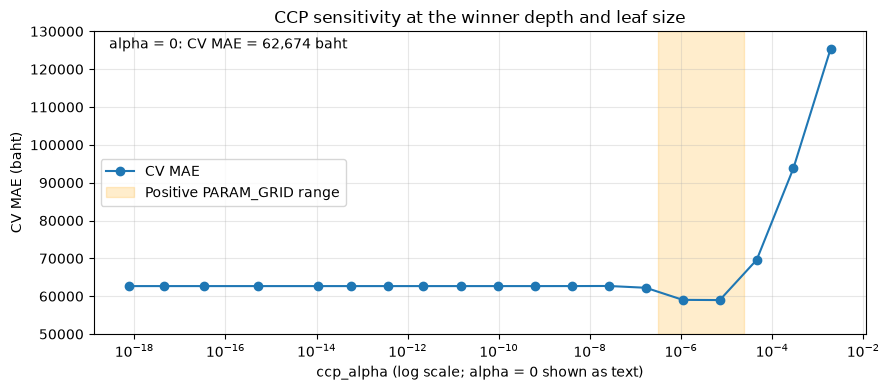

In [39]:
# [39] sensitivity ccp: กราฟและสรุป
# ==================================================
# ทำอะไร: หา alpha ที่ให้ CV MAE ต่ำสุดจากตารางในเซลล์ [38] แล้วดูว่าค่านั้นอยู่ในช่วง alpha บวก
#         ของ PARAM_GRID["ccp_alpha"] หรือไม่ พร้อมเทียบกับ CV MAE ของผู้ชนะ และวาดกราฟ
# ทำไม: ถ้าค่าที่ดีที่สุด "อยู่ในช่วง grid" แปลว่า grid ครอบคลุมบริเวณที่ดีแล้ว
#       ถ้า "อยู่นอกช่วง grid" (รวมกรณี alpha = 0 ซึ่งอยู่นอกช่วงบวกเสมอ)
#       แปลว่า grid อาจพลาดค่าที่ดีกว่า
# ผลที่ควรเห็น: สรุปเป็นบรรทัด ๆ แล้วกราฟเส้น CV MAE ของ alpha บวกบนแกน x แบบ log
#              แถบสีส้มคือช่วง alpha บวกใน PARAM_GRID ส่วนค่าของ alpha = 0
#              เขียนเป็นข้อความบนกราฟ (เพราะ log ของ 0 วาดไม่ได้)
#   - แกนถูกล็อกด้วยค่าคงที่ใน [03] (MAE_CCP_AXIS) เหมือนกันทั้ง DT / RF / XGB จึงเทียบความสูงข้ามโน้ตบุ๊คได้ตรงๆ
# ข้อควรระวัง: เป็นแค่การตรวจ ไม่เลือกผู้ชนะใหม่ และไม่เปลี่ยนค่าใดของ search
#   - ถ้ามีค่านอกแกนที่ล็อกไว้ จะพิมพ์ WARN หลังกราฟ (ไม่ตัดทิ้งเงียบๆ) ให้ขยาย MAE_CCP_AXIS ใน [03] ให้เหมือนกันทั้ง 3 โน้ตบุ๊ค
# ==================================================
print("=== [39] sensitivity ccp: กราฟและสรุป ===")

best_row = sensitivity_table.loc[sensitivity_table["cv_mae"].idxmin()]
positive_grid_alphas = [alpha for alpha in PARAM_GRID["ccp_alpha"] if alpha > 0]
grid_min = min(positive_grid_alphas)
grid_max = max(positive_grid_alphas)
is_inside = grid_min <= best_row["alpha"] <= grid_max

print(f"alpha ที่ดีที่สุด     : {best_row['alpha']:.3e}")
print(f"CV MAE ของ alpha นี้  : {best_row['cv_mae']:,.0f} บาท")
print(f"ช่วง alpha บวกใน grid : {grid_min:.3e} ถึง {grid_max:.3e}")
print(f"ตำแหน่ง               : {'อยู่ในช่วง grid' if is_inside else 'อยู่นอกช่วง grid'}")
print(f"CV MAE ของผู้ชนะ      : {cv_mae_all[search.best_index_]:,.0f} บาท")

positive_table = sensitivity_table[sensitivity_table["alpha"] > 0]
zero_cv_mae = sensitivity_table.iloc[0]["cv_mae"]  # แถวแรกคือ alpha = 0

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(positive_table["alpha"], positive_table["cv_mae"], "o-", label="CV MAE")
ax.axvspan(grid_min, grid_max, alpha=0.2, color="orange", label="Positive PARAM_GRID range")
ax.text(
    0.02,
    0.98,
    f"alpha = 0: CV MAE = {zero_cv_mae:,.0f} baht",
    transform=ax.transAxes,
    va="top",
)
ax.set(
    xscale="log",
    xlabel="ccp_alpha (log scale; alpha = 0 shown as text)",
    ylabel="CV MAE (baht)",
    title="CCP sensitivity at the winner depth and leaf size",
)
ax.set_ylim(*MAE_CCP_AXIS)
ax.grid(True, which="both", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

if positive_table["cv_mae"].min() < MAE_CCP_AXIS[0] or positive_table["cv_mae"].max() > MAE_CCP_AXIS[1]:
    print("WARN: ค่าบางจุดอยู่นอกแกนที่ล็อกไว้ (sensitivity ccp) ให้ขยาย MAE_CCP_AXIS ในเซลล์ [03]")

In [40]:
# [40] ตาราง 10 อันดับแรก
# ==================================================
# ทำอะไร: แสดง 10 ชุดพารามิเตอร์ที่ CV MAE ต่ำสุดจาก GridSearchCV (เซลล์ [32]) พร้อมพารามิเตอร์
#         ทุกตัว, ส่วนเบี่ยงเบนมาตรฐานข้าม fold (cv_mae_sd), train MAE และ gap
#         (MAE = ความคลาดเคลื่อนสัมบูรณ์เฉลี่ย หน่วยบาท)
# ทำไม: ดูว่าผู้ชนะตามกฎ 1-SE ต่างจากชุดที่ CV MAE ต่ำสุดอย่างไร และชุดคะแนนใกล้เคียงกันมากแค่ไหน
#       (1-SE = เลือกต้นไม้ที่เล็กที่สุดที่ CV MAE ไม่แย่กว่าค่าต่ำสุดเกิน 1 ส่วนเบี่ยงเบนมาตรฐาน)
# ผลที่ควรเห็น: ตารางประมาณ 10 แถว (บวกอีก 1 แถวถ้าผู้ชนะอยู่นอก 10 อันดับ) คอลัมน์:
#   - candidate : ลำดับของชุดพารามิเตอร์ใน grid
#   - chosen    : เครื่องหมาย * คือผู้ชนะตามกฎ 1-SE (ใบน้อยที่สุดในช่วง 1-SE ถ้าเสมอเลือก
#                 CV MAE ต่ำกว่า แล้วเลือกดัชนีต่ำกว่า)
#   - eligible  : "yes" คือชุดที่อยู่ในเกณฑ์ 1-SE
#   - leaves    : จำนวนใบของต้นไม้ที่ฝึกบน train ทั้งชุด แสดงเฉพาะแถว eligible (นอกนั้นเว้นว่าง)
#   - rank      : อันดับตาม CV MAE (1 = ต่ำสุด)
#   - max_depth, min_samples_leaf, ccp_alpha : ค่าพารามิเตอร์ของชุดนั้น
#   - cv_mae, cv_mae_sd, train_mae : MAE ตรวจสอบเฉลี่ย, ความแกว่งข้าม fold, MAE บนส่วนที่ใช้ฝึก
#   - gap       : cv_mae - train_mae
#   ผู้ชนะ "ไม่จำเป็นต้องเป็น rank 1" เพราะกฎ 1-SE ชอบต้นไม้ที่เล็กกว่า ซึ่งเป็นเรื่องปกติ
# ข้อควรระวัง:
#   - gap เป็นแค่อาการ ต้องอ่านคู่กับระดับของ CV MAE และ cv_mae_sd gap ต่ำอาจเกิดจากการที่
#     train ฟิตได้แย่ลง จึงไม่ใช่หลักฐานว่า overfit (จำข้อมูลฝึกมากเกินจนใช้กับข้อมูลใหม่ไม่ดี)
#     น้อยกว่าเพียงลำพัง
#   - ถ้าผู้ชนะอยู่นอก 10 อันดับ จะมีแถวเสริมต่อท้ายตาราง
#   - ถ้าค่าของผู้ชนะอยู่ที่ขอบของ grid ค่าที่ดีที่สุดอาจอยู่นอกช่วงที่ลอง
#     เซลล์ [38]-[39] ให้หลักฐานเพิ่มได้เฉพาะจุดที่ประเมินไว้
#   - เซลล์นี้ไม่เปลี่ยนโมเดลหรือ RESULT_JSON
# ==================================================
print("=== [40] ตาราง 10 อันดับแรก ===")

all_results = pd.DataFrame(search.cv_results_)
# mean_test_MAE เป็นค่าลบ จึงเรียงจากมากไปน้อย = MAE ต่ำสุดก่อน, stable คงลำดับเดิมเมื่อเสมอ
top = all_results.sort_values("mean_test_MAE", ascending=False, kind="stable").head(10)
if search.best_index_ not in top.index:  # ผู้ชนะอาจอยู่นอก 10 อันดับ
    top = pd.concat([top, all_results.loc[[search.best_index_]]])

rows = []
for index in top.index:
    result = all_results.loc[index]
    params = result["params"]
    is_eligible = index in eligible_indices
    cv_mae = -result["mean_test_MAE"]
    train_mae = -result["mean_train_MAE"]
    rows.append({
        "candidate": index,
        "chosen": "*" if index == search.best_index_ else "",
        "eligible": "yes" if is_eligible else "",
        "leaves": count_pipeline_leaves(params) if is_eligible else None,
        "rank": result["rank_test_MAE"],
        "max_depth": str(params["model__regressor__max_depth"]),  # แสดง None เป็นข้อความ
        "min_samples_leaf": params["model__regressor__min_samples_leaf"],
        "ccp_alpha": params["model__regressor__ccp_alpha"],
        "cv_mae": cv_mae,
        "cv_mae_sd": result["std_test_MAE"],
        "train_mae": train_mae,
        "gap": cv_mae - train_mae,
    })

top10 = pd.DataFrame(rows)
top10["leaves"] = pd.array(top10["leaves"], dtype="Int64")  # ช่องว่างเป็นค่าว่างได้

print("อ่านตาราง: เรียงตาม CV MAE ต่ำสุดก่อน, * = ผู้ชนะ 1-SE, แถวท้ายอาจเป็นแถวเสริมของผู้ชนะ")
display(
    top10.style
    .format(
        {
            "leaves": "{:,.0f}",
            "rank": "{:.0f}",
            "ccp_alpha": "{:.3e}",
            "cv_mae": "{:,.0f}",
            "cv_mae_sd": "{:,.0f}",
            "train_mae": "{:,.0f}",
            "gap": "{:,.0f}",
        },
        na_rep="",
    )
    .hide(axis="index")
)

=== [40] ตาราง 10 อันดับแรก ===
อ่านตาราง: เรียงตาม CV MAE ต่ำสุดก่อน, * = ผู้ชนะ 1-SE, แถวท้ายอาจเป็นแถวเสริมของผู้ชนะ


candidate,chosen,eligible,leaves,rank,max_depth,min_samples_leaf,ccp_alpha,cv_mae,cv_mae_sd,train_mae,gap
144,*,yes,"1,721",1,None,1,2.759e-06,"57,379",244,"45,283","12,095"
138,,,,2,25,1,2.759e-06,"57,651",469,"45,773","11,878"
145,,,,3,None,5,2.759e-06,"58,139",505,"49,935","8,204"
115,,,,4,None,5,1.334e-06,"58,185",553,"47,309","10,876"
139,,,,5,25,5,2.759e-06,"58,248",715,"50,123","8,125"
109,,,,6,25,5,1.334e-06,"58,259",714,"47,605","10,654"
174,,,,7,None,1,5.710e-06,"58,344",274,"51,051","7,293"
114,,,,8,None,1,1.334e-06,"58,423",135,"38,250","20,173"
168,,,,9,25,1,5.710e-06,"58,455",411,"51,255","7,200"
85,,,,10,None,5,6.443e-07,"58,601",523,"45,600","13,001"


In [41]:
# [41] learning curve: คำนวณ
# ==================================================
# ทำอะไร: ฝึกโมเดลผู้ชนะซ้ำหลายรอบบนข้อมูล train ที่มีขนาดเพิ่มขึ้นตาม LC_FRACTIONS
#         (10%, 20%, ... 100%) แล้ววัด MAE และ R² บนชุดย่อยที่ใช้ฝึกกับบน test
#         (MAE = ความคลาดเคลื่อนสัมบูรณ์เฉลี่ย หน่วยบาท,
#          R² = สัดส่วนความผันผวนของราคาที่โมเดลอธิบายได้ 1 = ดีที่สุด,
#          sd = ส่วนเบี่ยงเบนมาตรฐาน บอกว่าค่าแกว่งแค่ไหนระหว่างรอบ)
# ทำไม: learning curve ตอบคำถามว่า "ถ้ามีข้อมูลเพิ่ม โมเดลจะดีขึ้นไหม"
#       ถ้า test MAE ยังลดลงเรื่อย ๆ เมื่อเพิ่มแถว อาจได้ประโยชน์จากข้อมูลเพิ่ม
#       ถ้าเส้นนิ่งแล้ว ข้อมูลเพิ่มอาจช่วยน้อย
#       ทำซ้ำ LC_REPEATS (5) รอบ แต่ละรอบสุ่มลำดับแถวของ train ใหม่ด้วย seed ที่กำหนดจาก
#       [SEED, เลขรอบ] จึงทำซ้ำได้เหมือนเดิมทุกครั้ง ภายในรอบเดียวกันชุดเล็กเป็นส่วนหนึ่งของชุดใหญ่
#       (ซ้อนกัน) เพื่อให้เทียบขนาดต่าง ๆ ได้เป็นธรรม แล้วรายงานค่าเฉลี่ยและ sd ข้ามรอบ
#       (pandas คำนวณ sd แบบ ddof=1)
# ผลที่ควรเห็น: ข้อความ "รอบที่ k/5 เสร็จ" ทีละบรรทัด จากนั้นได้
#   - lc_runs  : ผลดิบ หนึ่งแถวต่อรอบและขนาด
#   - lc_table : ผลสรุปต่อขนาด (mean และ sd ของ train/test MAE และ R², จำนวนรอบ repeats)
#   เซลล์ [42] แสดงตารางและกราฟ
# ข้อควรระวัง:
#   - ผลเป็นหลักฐานเชิงชี้แนะเท่านั้น ไม่รับประกันผลนอกขนาดและข้อมูลที่ลอง
#   - ใช้ test เพื่ออธิบายกราฟเท่านั้น ไม่ใช้เลือกพารามิเตอร์หรือย้อนปรับโมเดล
#   - ไม่เปลี่ยน RESULT_JSON
# ==================================================
print("=== [41] learning curve: คำนวณ ===")

# ขนาดที่ใช้ฝึก: ปัดลง และมีอย่างน้อย 2 แถวเพื่อให้คำนวณ R² ได้
sizes = np.unique(np.clip((LC_FRACTIONS * len(train)).astype(int), 2, len(train)))

records = []
for repeat in range(LC_REPEATS):
    seed_sequence = np.random.SeedSequence([SEED, repeat])
    order = np.random.default_rng(seed_sequence).permutation(len(train))
    for size in sizes:
        subset = train.iloc[order[:size]]  # ชุดเล็กเป็นส่วนหนึ่งของชุดใหญ่
        estimator = clone(search.best_estimator_)  # พารามิเตอร์ผู้ชนะ ไม่แก้ search
        estimator.fit(subset[features], subset["price"])
        train_pred = estimator.predict(subset[features])
        test_pred = estimator.predict(test[features])
        records.append({
            "repeat": repeat + 1,
            "rows": int(size),
            "train MAE": mean_absolute_error(subset["price"], train_pred),
            "test MAE": mean_absolute_error(test["price"], test_pred),
            "train R2": r2_score(subset["price"], train_pred),
            "test R2": r2_score(test["price"], test_pred),
        })
    print(f"รอบที่ {repeat + 1}/{LC_REPEATS} เสร็จ")

lc_runs = pd.DataFrame(records)
metric_columns = ["train MAE", "test MAE", "train R2", "test R2"]
lc_table = lc_runs.groupby("rows")[metric_columns].agg(["mean", "std"])

# ทำชื่อคอลัมน์สองชั้นให้เป็นชั้นเดียว เช่น "train MAE mean", "train MAE sd"
flat_columns = []
for metric, statistic in lc_table.columns:
    flat_columns.append(f"{metric} {'sd' if statistic == 'std' else 'mean'}")
lc_table.columns = flat_columns

lc_table["repeats"] = lc_runs.groupby("rows")["repeat"].nunique()
lc_table = lc_table.reset_index()
print(f"ได้ผลครบ {len(lc_runs)} แถว ใน lc_runs และสรุป {len(lc_table)} ขนาดใน lc_table")

=== [41] learning curve: คำนวณ ===


รอบที่ 1/5 เสร็จ


รอบที่ 2/5 เสร็จ


รอบที่ 3/5 เสร็จ


รอบที่ 4/5 เสร็จ


รอบที่ 5/5 เสร็จ
ได้ผลครบ 50 แถว ใน lc_runs และสรุป 10 ขนาดใน lc_table


=== [42] learning curve: ตารางและกราฟ ===
อ่านตาราง: ค่าเฉลี่ยและ sd ข้าม 5 รอบ ของ MAE (บาท) และ R² ที่แต่ละจำนวนแถวฝึก


rows,train MAE mean,train MAE sd,test MAE mean,test MAE sd,train R2 mean,train R2 sd,test R2 mean,test R2 sd,repeats
"3,760","17,475",353,"82,302","2,290",0.9922,0.0004,0.8348,0.0115,5
"7,520","27,261",490,"71,793","1,438",0.9838,0.0005,0.8798,0.0067,5
"11,280","33,230",332,"66,775","1,181",0.9768,0.0007,0.8963,0.0059,5
"15,040","37,632",373,"64,006",144,0.9710,0.0008,0.9061,0.0027,5
"18,800","40,359",283,"61,893",494,0.9670,0.0006,0.9097,0.0037,5
"22,560","42,405",299,"60,339",873,0.9636,0.0005,0.9170,0.0053,5
"26,320","43,928",335,"59,233",416,0.9605,0.0008,0.9198,0.0015,5
"30,080","45,259",296,"57,842",356,0.9581,0.0006,0.9241,0.0016,5
"33,840","46,390",176,"57,543",220,0.9560,0.0003,0.9257,0.0011,5
"37,600","47,147",0,"57,267",88,0.9543,0.0000,0.9255,0.0008,5


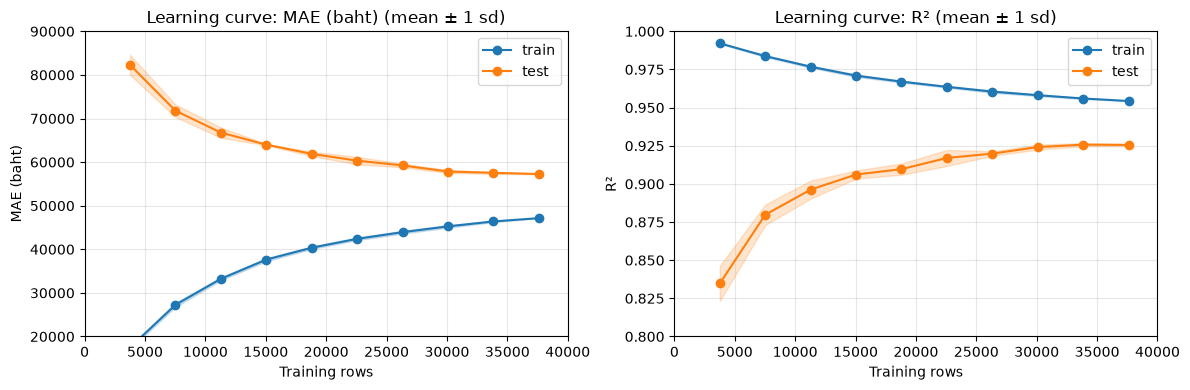

WARN: ค่าบางจุดอยู่นอกแกนที่ล็อกไว้ (learning curve) ให้ขยาย MAE_AXIS / R2_AXIS / ROWS_AXIS ในเซลล์ [03]


In [42]:
# [42] learning curve: ตารางและกราฟ
# ==================================================
# ทำอะไร: แสดง lc_table จากเซลล์ [41] เป็นตาราง แล้ววาดกราฟ 2 ช่องเคียงกัน (MAE และ R²)
#         แต่ละช่องมีเส้นค่าเฉลี่ยของ train และ test พร้อมแถบ ±1 sd
# ทำไม: ดูแนวโน้มว่าเมื่อเพิ่มแถวฝึกแล้วคะแนนเปลี่ยนอย่างไร และช่องว่างระหว่าง train กับ test
#       เปลี่ยนอย่างไร
# ผลที่ควรเห็น: ตารางหนึ่งแถวต่อขนาด และกราฟ 2 ช่อง
#   - ถ้า test MAE ยังลดลง (หรือ test R² ยังเพิ่ม) ที่ขนาดมาก ๆ อาจได้ประโยชน์จากข้อมูลเพิ่ม
#   - ถ้า train ดีกว่า test มาก แปลว่าโมเดลจำข้อมูลฝึกได้ดีกว่าข้อมูลใหม่ (อาการ overfit)
#   - แกนถูกล็อกด้วยค่าคงที่ใน [03] (MAE_AXIS, R2_AXIS, ROWS_AXIS) เหมือนกันทั้ง DT / RF / XGB จึงเทียบความสูงข้ามโน้ตบุ๊คได้ตรงๆ
# ข้อควรระวัง:
#   - เป็นหลักฐานเชิงชี้แนะเท่านั้น ไม่ใช่คำยืนยัน
#   - test ใช้อธิบายกราฟเท่านั้น ไม่ใช้เลือกพารามิเตอร์
#   - แถบ ±1 sd คือความแกว่งจากการเลือกชุดย่อยต่างกัน ไม่ใช่ confidence interval
#     (ช่วงความเชื่อมั่น) และไม่รวมความไม่แน่นอนจากการสุ่ม test ชุดใหม่
#   - ที่ขนาดเต็ม ทุกรอบใช้แถวชุดเดียวกัน (แค่เรียงลำดับต่างกัน) จึงได้ sd = 0
#   - ช่องว่าง (gap) ต้องอ่านคู่กับระดับคะแนน ไม่ใช้วัด overfit เพียงลำพัง
#   - ถ้ามีค่านอกแกนที่ล็อกไว้ จะพิมพ์ WARN หลังกราฟ (ไม่ตัดทิ้งเงียบๆ) ให้ขยาย MAE_AXIS, R2_AXIS, ROWS_AXIS ใน [03] ให้เหมือนกันทั้ง 3 โน้ตบุ๊ค
# ==================================================
print("=== [42] learning curve: ตารางและกราฟ ===")

table_formats = {"rows": "{:,.0f}", "repeats": "{:.0f}"}
for column in lc_table.columns:
    if "MAE" in column:
        table_formats[column] = "{:,.0f}"
    elif "R2" in column:
        table_formats[column] = "{:.4f}"

print("อ่านตาราง: ค่าเฉลี่ยและ sd ข้าม 5 รอบ ของ MAE (บาท) และ R² ที่แต่ละจำนวนแถวฝึก")
display(lc_table.style.format(table_formats).hide(axis="index"))

out_of_axis = False
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric, ylabel in zip(axes, ["MAE", "R2"], ["MAE (baht)", "R²"]):
    limits = MAE_AXIS if metric == "MAE" else R2_AXIS
    for part in ["train", "test"]:
        mean = lc_table[f"{part} {metric} mean"].to_numpy()
        sd = lc_table[f"{part} {metric} sd"].to_numpy()
        line, = ax.plot(lc_table["rows"], mean, marker="o", label=part)
        ax.fill_between(lc_table["rows"], mean - sd, mean + sd, color=line.get_color(), alpha=0.2)
        if (mean - sd).min() < limits[0] or (mean + sd).max() > limits[1] or lc_table["rows"].max() > ROWS_AXIS[1]:
            out_of_axis = True
    ax.set(xlabel="Training rows", ylabel=ylabel, title=f"Learning curve: {ylabel} (mean ± 1 sd)")
    ax.set_xlim(*ROWS_AXIS)
    ax.set_ylim(*limits)
    ax.grid(True, alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

if out_of_axis:
    print("WARN: ค่าบางจุดอยู่นอกแกนที่ล็อกไว้ (learning curve) ให้ขยาย MAE_AXIS / R2_AXIS / ROWS_AXIS ในเซลล์ [03]")

=== [43] ตาราง CV train เทียบ validation ===


อ่านตาราง: หนึ่งแถวต่อ fold, MAE เป็นบาท, gap = validation - train (R² gap = train - validation)


,train MAE,validation MAE,MAE gap,gap % of validation MAE,train R2,validation R2,R2 gap
1,"45,130","57,388","12,258",21.36,0.9581,0.9282,0.0299
2,"45,369","57,653","12,284",21.31,0.9577,0.9271,0.0306
3,"45,254","57,118","11,865",20.77,0.9586,0.9194,0.0392
4,"45,177","57,645","12,467",21.63,0.9582,0.9271,0.0311
5,"45,486","57,089","11,603",20.32,0.9582,0.9219,0.0363
mean,"45,283","57,379","12,095",21.08,0.9582,0.9247,0.0334
sd,130,244,315,0.47,0.0003,0.0035,0.0037


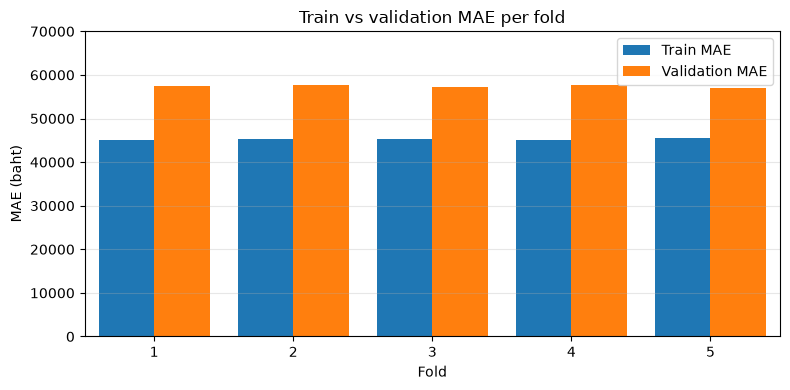

In [43]:
# [43] ตาราง CV train เทียบ validation
# ==================================================
# ทำอะไร: ฝึกโมเดลผู้ชนะใหม่ในแต่ละ fold ของ train แล้วเทียบคะแนนบนแถวที่ใช้ฝึก (train)
#         กับแถวที่กันไว้ตรวจ (validation) ของ fold นั้น ทั้ง MAE (บาท) และ R²
#         (fold = ส่วนย่อยของ train ที่สลับกันเป็นชุดตรวจ, MAE = ความคลาดเคลื่อนสัมบูรณ์เฉลี่ย,
#          R² = สัดส่วนความผันผวนของราคาที่โมเดลอธิบายได้ 1 = ดีที่สุด)
# ทำไม: ดูขนาดและความสม่ำเสมอของช่องว่างระหว่าง train กับ validation
#       - train ดีกว่า validation มาก อาจเป็นสัญญาณ overfit (จำข้อมูลฝึกมากเกินไป)
#       - ถ้าทั้งสองแย่และใกล้กัน อาจเป็น underfit (โมเดลง่ายเกินไป)
#       เซลล์นี้ไม่ตัดสินให้อัตโนมัติ ให้ดูระดับคะแนนและความกระจายร่วมกัน
# ผลที่ควรเห็น: ตารางหนึ่งแถวต่อ fold (เลข fold เริ่มที่ 1) คอลัมน์ train MAE, validation MAE,
#              MAE gap (validation - train), gap เป็น % ของ validation MAE, train R²,
#              validation R², R² gap (train - validation) และท้ายตารางมีแถว mean กับ sd
#              (sd แบบ ddof=0 คำนวณจากแถว fold เท่านั้น) กับกราฟแท่งเทียบ train/validation MAE
#   - แกนถูกล็อกด้วยค่าคงที่ใน [03] (MAE_BAR_AXIS, FOLD_AXIS) เหมือนกันทั้ง DT / RF / XGB จึงเทียบความสูงข้ามโน้ตบุ๊คได้ตรงๆ
# ข้อควรระวัง:
#   - ใช้เฉพาะ train และ folds ไม่ใช้ val หรือ test และเป็นการตรวจผู้ชนะที่เลือกจาก fold เดิม
#     จึงไม่ใช่ผลประเมินอิสระจากการเลือกพารามิเตอร์
#   - ข้อจำกัดของ ccp: CV MAE อาจดีเกินจริงเล็กน้อย เพราะ alpha ถูกสร้างและคัดกรองจาก train
#     ทั้งชุด รวมแถว held-out ของ fold ด้วย ควรใช้ test ที่ยังไม่แตะ (และ val) ตรวจอิสระ
#   - ช่องว่างเป็นอาการที่ต้องอ่านคู่กับระดับ CV และความกระจาย ไม่ใช่มาตรวัด overfit เพียงลำพัง
#   - learning curve (เซลล์ [41]-[42]) เป็นการตรวจที่สาม ช่วยดูว่าเพิ่มแถวฝึกแล้วคะแนนและ
#     ช่องว่างเปลี่ยนอย่างไร ให้หลักฐานเชิงชี้แนะเท่านั้น
#   - ถ้ามีค่านอกแกนที่ล็อกไว้ จะพิมพ์ WARN หลังกราฟ (ไม่ตัดทิ้งเงียบๆ) ให้ขยาย MAE_BAR_AXIS, FOLD_AXIS ใน [03] ให้เหมือนกันทั้ง 3 โน้ตบุ๊ค
# ==================================================
print("=== [43] ตาราง CV train เทียบ validation ===")

scores = cross_validate(
    clone(search.best_estimator_),
    train[features],
    train["price"],
    cv=folds,
    scoring={"MAE": "neg_mean_absolute_error", "R2": "r2"},
    return_train_score=True,
    n_jobs=SEARCH_JOBS,
    pre_dispatch=SEARCH_JOBS,
    error_score="raise",
)

train_mae = -scores["train_MAE"]  # คะแนนเป็นค่าลบ จึงกลับเครื่องหมายให้เป็น MAE บวก
validation_mae = -scores["test_MAE"]  # "test" ของ sklearn คือแถว validation ใน fold
mae_gap = validation_mae - train_mae

fold_table = pd.DataFrame(
    {
        "train MAE": train_mae,
        "validation MAE": validation_mae,
        "MAE gap": mae_gap,
        "gap % of validation MAE": mae_gap * 100 / validation_mae,
        "train R2": scores["train_R2"],
        "validation R2": scores["test_R2"],
        "R2 gap": scores["train_R2"] - scores["test_R2"],
    },
    index=pd.Index(range(1, len(train_mae) + 1), name="fold"),
)

summary_rows = pd.DataFrame(
    [fold_table.mean(), fold_table.std(ddof=0)],
    index=["mean", "sd"],
)
cv_check_table = pd.concat([fold_table, summary_rows])

table_formats = {
    "train MAE": "{:,.0f}",
    "validation MAE": "{:,.0f}",
    "MAE gap": "{:,.0f}",
    "gap % of validation MAE": "{:.2f}",
    "train R2": "{:.4f}",
    "validation R2": "{:.4f}",
    "R2 gap": "{:.4f}",
}
print("อ่านตาราง: หนึ่งแถวต่อ fold, MAE เป็นบาท, gap = validation - train (R² gap = train - validation)")
display(cv_check_table.style.format(table_formats))

positions = np.arange(len(fold_table))
bar_width = 0.4
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(positions - bar_width / 2, fold_table["train MAE"], bar_width, label="Train MAE")
ax.bar(positions + bar_width / 2, fold_table["validation MAE"], bar_width, label="Validation MAE")
ax.set_xticks(positions, fold_table.index)
ax.set(xlabel="Fold", ylabel="MAE (baht)", title="Train vs validation MAE per fold")
ax.set_xlim(*FOLD_AXIS)
ax.set_ylim(*MAE_BAR_AXIS)
ax.grid(True, axis="y", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

if (
    fold_table[["train MAE", "validation MAE"]].max().max() > MAE_BAR_AXIS[1]
    or len(fold_table) - 1 + bar_width > FOLD_AXIS[1]
):
    print("WARN: ค่าบางจุดอยู่นอกแกนที่ล็อกไว้ (กราฟแท่ง CV train เทียบ validation) ให้ขยาย MAE_BAR_AXIS / FOLD_AXIS ในเซลล์ [03]")

In [44]:
# [44] validation curve: คำนวณ
# ==================================================
# ทำอะไร: เปลี่ยนพารามิเตอร์ของต้นไม้ทีละตัว (max_depth, min_samples_leaf, ccp_alpha)
#         ตามทุกค่าใน PARAM_GRID โดยคงพารามิเตอร์ตัวอื่นไว้ตามผู้ชนะ แล้ววัด MAE บนส่วนฝึกและ
#         ส่วนตรวจสอบ (validation) ของแต่ละ fold เก็บลง vc_results
#         (validation curve = กราฟคะแนนเมื่อเปลี่ยนพารามิเตอร์หนึ่งตัว,
#          fold = ส่วนย่อยของ train ที่สลับกันเป็นชุดตรวจ,
#          MAE = ความคลาดเคลื่อนสัมบูรณ์เฉลี่ย หน่วยบาท,
#          sd = ส่วนเบี่ยงเบนมาตรฐานข้าม fold แบบ ddof=0)
# ทำไม: ดูว่าพารามิเตอร์แต่ละตัวทำให้โมเดลซับซ้อนขึ้น/ง่ายลงแล้ว MAE ฝึกกับ MAE ตรวจสอบ
#       ห่างกันอย่างไร เพื่ออ่านความซับซ้อนร่วมกับช่องว่างของคะแนน
# ผลที่ควรเห็น: ข้อความหนึ่งบรรทัดต่อพารามิเตอร์ จากนั้น vc_results พร้อมให้เซลล์ [45]
#              แสดงตารางและกราฟ (ไม่มีผลลัพธ์อื่นในเซลล์นี้)
# ข้อควรระวัง:
#   - ฝึกสำเนาของ Pipeline บน train ด้วย folds เดิมเท่านั้น ไม่เปลี่ยน search
#   - ค่าที่ลองคือทุกค่าใน PARAM_GRID ตามลำดับเดิม (รวม None ของ max_depth และ 0 ของ ccp_alpha)
# ==================================================
print("=== [44] validation curve: คำนวณ ===")

vc_results = {}
for name in ["max_depth", "min_samples_leaf", "ccp_alpha"]:
    values = list(PARAM_GRID[name])
    train_scores, valid_scores = validation_curve(
        clone(search.best_estimator_),
        train[features],
        train["price"],
        param_name="model__regressor__" + name,
        param_range=values,
        cv=folds,
        scoring="neg_mean_absolute_error",
        n_jobs=SEARCH_JOBS,
        pre_dispatch=SEARCH_JOBS,
        error_score="raise",
    )
    train_mae = -train_scores  # หนึ่งแถวต่อค่า หนึ่งคอลัมน์ต่อ fold
    valid_mae = -valid_scores
    vc_results[name] = {
        "values": values,
        "train_mean": train_mae.mean(axis=1),
        "train_sd": train_mae.std(axis=1, ddof=0),
        "cv_mean": valid_mae.mean(axis=1),
        "cv_sd": valid_mae.std(axis=1, ddof=0),
    }
    print(f"{name} เสร็จ ({len(values)} ค่า)")

=== [44] validation curve: คำนวณ ===


max_depth เสร็จ (5 ค่า)


min_samples_leaf เสร็จ (6 ค่า)


ccp_alpha เสร็จ (8 ค่า)


=== [45] validation curve: ตารางและกราฟ ===
อ่านตาราง max_depth: MAE เป็นบาท, gap = CV MAE - train MAE (ยิ่งกว้างยิ่งเสี่ยง overfit)


value,train MAE mean,CV MAE mean,CV MAE sd,gap
10,"75,915","79,681","1,421","3,766"
15,"55,137","63,651","1,306","8,514"
20,"47,752","58,742",821,"10,990"
25,"45,773","57,651",469,"11,878"
None,"45,283","57,379",244,"12,095"


อ่านตาราง min_samples_leaf: MAE เป็นบาท, gap = CV MAE - train MAE (ยิ่งกว้างยิ่งเสี่ยง overfit)


value,train MAE mean,CV MAE mean,CV MAE sd,gap
1,"45,283","57,379",244,"12,095"
5,"49,935","58,139",505,"8,204"
7,"51,453","59,021",467,"7,568"
9,"52,978","59,687",594,"6,708"
12,"54,613","60,874",576,"6,261"
15,"56,298","62,303",716,"6,004"


อ่านตาราง ccp_alpha: MAE เป็นบาท, gap = CV MAE - train MAE (ยิ่งกว้างยิ่งเสี่ยง overfit)


value,train MAE mean,CV MAE mean,CV MAE sd,gap
0.000e+00,"15,461","62,674",678,"47,213"
3.115e-07,"24,789","61,535",509,"36,746"
6.443e-07,"30,757","60,251",299,"29,494"
1.334e-06,"38,250","58,423",135,"20,173"
2.759e-06,"45,283","57,379",244,"12,095"
5.710e-06,"51,051","58,344",274,"7,293"
1.184e-05,"56,014","60,934",453,"4,920"
2.443e-05,"61,347","64,932",712,"3,585"


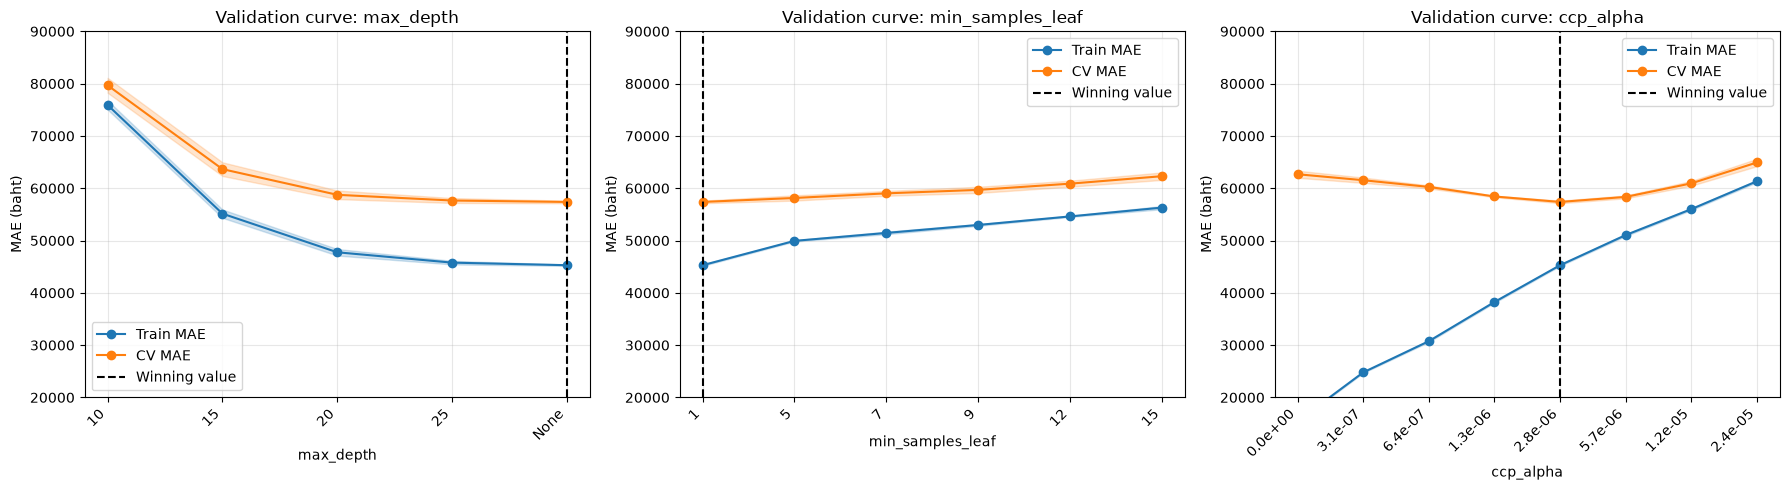

WARN: ค่าบางจุดอยู่นอกแกนที่ล็อกไว้ (validation curve) ให้ขยาย MAE_AXIS ในเซลล์ [03]


In [45]:
# [45] validation curve: ตารางและกราฟ
# ==================================================
# ทำอะไร: แสดงตารางของแต่ละพารามิเตอร์จาก vc_results (เซลล์ [44]) แล้ววาดกราฟ 3 ช่องเคียงกัน
#         เส้น train และ CV MAE เฉลี่ย พร้อมแถบ ±1 sd และเส้นประแนวตั้งที่ค่าของผู้ชนะ
# ทำไม: ดูว่าพารามิเตอร์แต่ละตัวพาโมเดลไปทาง overfit หรือ underfit
#       (overfit = จำข้อมูลฝึกมากเกินจนใช้กับข้อมูลใหม่ไม่ดี, underfit = ง่ายเกินจนจับแบบแผนไม่ได้)
# วิธีอ่าน:
#   - ทิศทางความซับซ้อน: max_depth ยิ่งลึก, min_samples_leaf ยิ่งเล็ก และ ccp_alpha ยิ่งเล็ก
#     ต้นไม้ยิ่งซับซ้อน (บนกราฟ ตำแหน่ง x เรียงตามลำดับค่าใน PARAM_GRID ไม่ใช่ระยะห่างจริง)
#   - overfit: train MAE ต่ำมากแต่ CV MAE สูงกว่ามาก (ช่องว่างกว้าง) มักเกิดทางด้านซับซ้อน
#   - underfit: ทั้ง train และ CV MAE สูงและใกล้กัน มักเกิดทางด้านง่าย
#   - ผู้ชนะ (เส้นประ) ไม่จำเป็นต้องอยู่ที่จุดต่ำสุดของ CV MAE เพราะกฎ 1-SE
#     (เลือกต้นไม้ที่เล็กที่สุดที่ CV MAE ไม่แย่กว่าค่าต่ำสุดเกิน 1 ส่วนเบี่ยงเบนมาตรฐาน)
#     ชอบรุ่นที่ง่ายกว่า
# ผลที่ควรเห็น: ตาราง 3 ตาราง (คอลัมน์ value, train MAE mean, CV MAE mean, CV MAE sd, gap
#              โดย gap = CV MAE - train MAE) และรูปเดียวที่มี 3 กราฟ
#   - แกนถูกล็อกด้วยค่าคงที่ใน [03] (MAE_AXIS) เหมือนกันทั้ง DT / RF / XGB จึงเทียบความสูงข้ามโน้ตบุ๊คได้ตรงๆ
# ข้อควรระวัง: ตารางและกราฟนี้ใช้ train กับ folds เดิม จึงไม่ใช่ผลประเมินอิสระ
#   - ถ้ามีค่านอกแกนที่ล็อกไว้ จะพิมพ์ WARN หลังกราฟ (ไม่ตัดทิ้งเงียบๆ) ให้ขยาย MAE_AXIS ใน [03] ให้เหมือนกันทั้ง 3 โน้ตบุ๊ค
# ==================================================
print("=== [45] validation curve: ตารางและกราฟ ===")

parameter_names = ["max_depth", "min_samples_leaf", "ccp_alpha"]

for name in parameter_names:
    result = vc_results[name]
    value_labels = []
    for value in result["values"]:
        if name == "ccp_alpha":
            value_labels.append(f"{value:.3e}")
        else:
            value_labels.append(str(value))  # None แสดงเป็น "None"
    table = pd.DataFrame(
        {
            "value": value_labels,
            "train MAE mean": result["train_mean"],
            "CV MAE mean": result["cv_mean"],
            "CV MAE sd": result["cv_sd"],
            "gap": result["cv_mean"] - result["train_mean"],
        }
    )
    print(f"อ่านตาราง {name}: MAE เป็นบาท, gap = CV MAE - train MAE (ยิ่งกว้างยิ่งเสี่ยง overfit)")
    display(
        table.style
        .format(
            {
                "train MAE mean": "{:,.0f}",
                "CV MAE mean": "{:,.0f}",
                "CV MAE sd": "{:,.0f}",
                "gap": "{:,.0f}",
            }
        )
        .hide(axis="index")
    )

out_of_axis = False
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, name in zip(axes, parameter_names):
    result = vc_results[name]
    values = result["values"]
    positions = np.arange(len(values))  # ใช้ตำแหน่งแทนค่าจริง เพื่อแสดง None และ 0 ได้

    tick_labels = []
    for value in values:
        if value is None:
            tick_labels.append("None")
        elif name == "ccp_alpha":
            tick_labels.append(f"{value:.1e}")
        else:
            tick_labels.append(str(value))

    for mean, sd, label in [
        (result["train_mean"], result["train_sd"], "Train MAE"),
        (result["cv_mean"], result["cv_sd"], "CV MAE"),
    ]:
        line, = ax.plot(positions, mean, marker="o", label=label)
        ax.fill_between(positions, mean - sd, mean + sd, color=line.get_color(), alpha=0.2)
        if (mean - sd).min() < MAE_AXIS[0] or (mean + sd).max() > MAE_AXIS[1]:
            out_of_axis = True

    winner_value = search.best_params_["model__regressor__" + name]
    ax.axvline(values.index(winner_value), color="black", linestyle="--", label="Winning value")
    ax.set_xticks(positions, tick_labels, rotation=45, ha="right")
    ax.set(xlabel=name, ylabel="MAE (baht)", title=f"Validation curve: {name}")
    ax.set_ylim(*MAE_AXIS)
    ax.grid(True, alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

if out_of_axis:
    print("WARN: ค่าบางจุดอยู่นอกแกนที่ล็อกไว้ (validation curve) ให้ขยาย MAE_AXIS ในเซลล์ [03]")

In [46]:
# [46] สรุปการตรวจ overfit
# ==================================================
# ทำอะไร: รวมหลักฐานเรื่อง overfit ของโมเดลผู้ชนะไว้ที่เดียว แล้วพิมพ์ PASS หรือ WARN ทีละข้อพร้อมเกณฑ์
#   1) เทียบ MAE ที่ประเมินจากฝั่ง train (CV จากเซลล์ [33]) กับ MAE บนข้อมูลที่ไม่เคยแตะเลย
#      (validation และ test จากเซลล์ [36]) และเทียบ validation กับ test
#   2) learning curve (เซลล์ [41]-[42]): เมื่อแถวฝึกมากขึ้น test MAE ต้องลดลง และช่องว่าง train-test
#      ต้องแคบลง
#   3) INFO: train MAE เทียบ CV MAE (พิมพ์ให้ดูเฉยๆ ไม่นับเป็น WARN เหตุผลอยู่ด้านล่าง)
# ทำไม:
#   - overfit คือโมเดลจำข้อมูลฝึกจนทายข้อมูลใหม่แย่ลง ถ้าเกิดขึ้น (หรือถ้าการเลือกพารามิเตอร์ไปเข้าข้าง
#     ความบังเอิญของ fold) MAE บน validation / test จะสูงกว่าค่าที่ประเมินจากฝั่ง train อย่างชัดเจน
#     CV วัดบนแถวที่โมเดลตัวนั้นไม่ได้ฝึก จึงควรตรงกับ validation / test ถ้าไม่ overfit
#   - เกณฑ์ "ต่างกันได้ไม่เกิน 2 SE": MAE ที่วัดจากรถ n คันมีความคลาดเคลื่อนจากการสุ่มว่ารถคันไหนตกอยู่
#     ในชุดนั้น เรียกว่า SE (standard error) = sd ของ |ทายผิด| / sqrt(n) ส่วน SE ของ CV ใช้
#     std ของ MAE ราย fold / sqrt(จำนวน fold) แบบเดียวกับกฎ 1-SE ผลต่างของค่าประมาณสองค่ามี
#     SE = sqrt(SE1² + SE2²) ถ้าต่างกันเกิน 2 เท่าของค่านี้ (ราว 95% ของความต่างที่เกิดจากการสุ่มล้วนๆ
#     จะไม่เกินระยะนี้ ตามการประมาณแบบการแจกแจงปกติ) จึงไม่น่าใช่แค่ความบังเอิญ ให้ WARN
#     เกณฑ์คิดจากข้อมูลจริงทุกครั้ง ไม่ได้ตั้งเลขตายตัว
#   - ทิศของความต่าง: validation / test แย่กว่าเกินเกณฑ์ = สัญญาณ overfit
#     (ค่าที่ประเมินจากฝั่ง train มองโลกในแง่ดีเกินไป) ส่วน validation / test ดีกว่าเกินเกณฑ์
#     ไม่ใช่ overfit แต่ควรหาสาเหตุ เช่น แถวที่ค่าเหมือนกันข้ามชุด (ต่างกันแค่สี ดูเซลล์ [13])
#     ทำให้ชุดนั้นง่ายขึ้นเล็กน้อย
#   - ความต่างเล็กๆ ที่คาดได้ล่วงหน้า: โมเดลสุดท้ายฝึกบน train ทั้งชุด (CV ฝึกบน 4/5)
#     จึงมักดีกว่า CV นิดหน่อย และ CV MAE ของผู้ชนะที่ถูกเลือกจากทุกชุดใน grid อาจดีเกินจริงเล็กน้อย
#     (กฎ 1-SE ลดผลนี้ลง เพราะไม่ได้เลือกชุดที่ต่ำสุดตรงๆ) ยังมีอีกข้อ: ccp_alpha ถูกสร้างและคัดกรอง
#     จาก train ทั้งชุด (เซลล์ [22]-[26]) ซึ่งรวมแถวที่แต่ละ fold กันไว้ CV MAE จึงอาจดีเกินจริงเพิ่มอีกนิด
#     ทำให้ validation / test แย่กว่า CV เล็กน้อยได้ เกณฑ์ 2 SE ช่วยแยกความต่างระดับนี้ออกจากของจริง
#   - learning curve: โมเดลที่ไม่ overfit จะทายข้อมูลใหม่ดีขึ้นเมื่อมีข้อมูลฝึกมากขึ้น และช่องว่าง
#     train-test แคบลง ถ้าช่องว่างกว้างขึ้นหรือ test MAE ไม่ลดลง ถือว่าผิดปกติ ให้ WARN
#   - ความจริงเฉพาะของต้นไม้ต้นเดียว: ต้นไม้ที่ใบเล็ก (min_samples_leaf น้อย ไม่ตัดกิ่ง) จำแถวฝึกได้เกือบหมด
#     train MAE จึงต่ำกว่า CV MAE มากเป็นปกติ ช่องว่างนี้ลำพังไม่ใช่ overfit
#     (ถ้าต้นไม้ overfit จริง CV / validation / test จะแย่ลงด้วย ซึ่งข้อ 1 ตรวจอยู่แล้ว)
#     กฎ 1-SE และ ccp_alpha ถูกออกแบบมาให้เลือกต้นไม้ที่เล็กพอ จึงพิมพ์อัตราส่วน train / CV ไว้ให้ดูเป็น INFO
# ผลที่ควรเห็น: ตารางย่อ MAE ± SE ของ CV, validation, test แล้วบรรทัด PASS/WARN 4 บรรทัด
#       (validation เทียบ CV, test เทียบ CV, test เทียบ validation, learning curve)
#       บรรทัด INFO 1 บรรทัด และบรรทัดสรุปสุดท้าย
# ข้อควรระวัง: PASS ทุกข้อแปลว่า "ไม่พบหลักฐาน overfit" ตามเกณฑ์เหล่านี้ ไม่ใช่การพิสูจน์ว่าไม่มีเลย
#       และ test ใช้ตรวจอย่างเดียว ห้ามย้อนกลับไปปรับโมเดลตามผลนี้
# ==================================================
print("=== [46] สรุปการตรวจ overfit ===")

estimates = {
    "CV": (cv_mae_all[chosen_index], cv_results["std_test_MAE"][chosen_index] / np.sqrt(n_splits)),
}
for name, part in [("validation", val), ("test", test)]:
    errors = np.abs(part["price"].to_numpy() - model.predict(part[features]))
    estimates[name] = (errors.mean(), errors.std(ddof=1) / np.sqrt(len(errors)))

print("MAE ของโมเดลผู้ชนะจากแต่ละแหล่ง (± 1 SE)")
for name, (mae, standard_error) in estimates.items():
    print(f"  {name:<10}: {mae:,.0f} ± {standard_error:,.0f} บาท")

warn_count = 0
comparisons = [
    ("validation", "CV"),
    ("test", "CV"),
    ("test", "validation"),
]
for held_out, reference in comparisons:
    held_out_mae, held_out_se = estimates[held_out]
    reference_mae, reference_se = estimates[reference]
    difference = held_out_mae - reference_mae
    band = 2 * np.sqrt(held_out_se**2 + reference_se**2)
    if abs(difference) <= band:
        status = "PASS"
    else:
        status = "WARN"
        warn_count = warn_count + 1
    label = f"{held_out} เทียบ {reference}"
    print(
        f"{status} {label:<24}: ต่างกัน {difference:+,.0f} บาท "
        f"({difference * 100 / reference_mae:+.2f}%) เกณฑ์ ±{band:,.0f} บาท (2 SE)"
    )

first = lc_table.iloc[0]
last = lc_table.iloc[-1]
first_gap = first["test MAE mean"] - first["train MAE mean"]
last_gap = last["test MAE mean"] - last["train MAE mean"]
if last["test MAE mean"] < first["test MAE mean"] and last_gap < first_gap:
    status = "PASS"
else:
    status = "WARN"
    warn_count = warn_count + 1
print(
    f"{status} learning curve ({int(first['rows']):,} -> {int(last['rows']):,} แถว): "
    f"test MAE {first['test MAE mean']:,.0f} -> {last['test MAE mean']:,.0f} บาท, "
    f"gap {first_gap:,.0f} -> {last_gap:,.0f} บาท (ต้องลดลงทั้งคู่)"
)

train_ratio = results["train"]["MAE"] / estimates["CV"][0]
print(
    f"INFO train MAE {results['train']['MAE']:,.0f} บาท = {train_ratio:.4f} เท่าของ CV MAE "
    "(ต่ำกว่ามากเป็นปกติของต้นไม้ที่ใบเล็ก ไม่นับเป็น WARN)"
)

if warn_count == 0:
    print("สรุป: PASS ทุกข้อ ไม่พบหลักฐานว่าโมเดล overfit ตามเกณฑ์ของเซลล์นี้")
else:
    print(f"สรุป: มี WARN {warn_count} ข้อ อ่านคำอธิบายทิศของความต่างที่หัวเซลล์ก่อนนำโมเดลไปใช้")

=== [46] สรุปการตรวจ overfit ===
MAE ของโมเดลผู้ชนะจากแต่ละแหล่ง (± 1 SE)
  CV        : 57,379 ± 109 บาท
  validation: 56,283 ± 1,006 บาท
  test      : 57,187 ± 993 บาท
PASS validation เทียบ CV     : ต่างกัน -1,096 บาท (-1.91%) เกณฑ์ ±2,023 บาท (2 SE)
PASS test เทียบ CV           : ต่างกัน -192 บาท (-0.33%) เกณฑ์ ±1,997 บาท (2 SE)
PASS test เทียบ validation   : ต่างกัน +904 บาท (+1.61%) เกณฑ์ ±2,826 บาท (2 SE)
PASS learning curve (3,760 -> 37,600 แถว): test MAE 82,302 -> 57,267 บาท, gap 64,827 -> 10,120 บาท (ต้องลดลงทั้งคู่)
INFO train MAE 47,147 บาท = 0.8217 เท่าของ CV MAE (ต่ำกว่ามากเป็นปกติของต้นไม้ที่ใบเล็ก ไม่นับเป็น WARN)
สรุป: PASS ทุกข้อ ไม่พบหลักฐานว่าโมเดล overfit ตามเกณฑ์ของเซลล์นี้


In [47]:
# [47] Ablation: เปรียบเทียบการปรับข้อมูล
# ==================================================
# ทำอะไร: ตรึงพารามิเตอร์ที่ปรับสำหรับ both แล้ววัด none, scale only, log only, both ด้วย folds เดิมและ train ไป test
# ทำไม: ใช้ข้อมูลและกติกาเดียวกันเพื่อเปรียบเทียบการทดลองได้อย่างเป็นธรรม
# ผลที่ควรเห็น: ตารางผลที่คำนวณจริงและกราฟที่มีข้อความภาษาอังกฤษ
# ข้อควรระวัง: ไม่ได้ปรับพารามิเตอร์ใหม่ราย variant; test ใช้รายงานเท่านั้น; ตัดสินด้วยหนึ่ง SE ของ CV ของ none
# ==================================================
print("=== [47] Ablation: เปรียบเทียบการปรับข้อมูล ===")

# พารามิเตอร์ถูกปรับสำหรับ both และตรึงไว้ ไม่ปรับใหม่แยกแต่ละ variant
fixed_model_params = {key.removeprefix("model__regressor__"): value
                      for key, value in search.best_params_.items()}
ablation_rows = []
ablation_fold_mae = {}
for label, scale, log_target in [("none", False, False), ("scale only", True, False),
                                  ("log only", False, True), ("both", True, True)]:
    regressor = make_model().set_params(**fixed_model_params)
    if log_target:
        regressor = TransformedTargetRegressor(regressor=regressor, func=np.log, inverse_func=np.exp)
    estimator = Pipeline([("encode", FoldOneHot(NUM_COLS, CAT_COLS, scale_numeric=scale)),
                          ("model", regressor)])
    fold_mae = -cross_val_score(estimator, train[features], train["price"], cv=folds,
                                scoring="neg_mean_absolute_error", n_jobs=SEARCH_JOBS,
                                pre_dispatch=SEARCH_JOBS, error_score="raise")
    ablation_fold_mae[label] = fold_mae
    estimator.fit(train[features], train["price"])
    metrics = score(test["price"], estimator.predict(test[features]))
    ablation_rows.append({"variant": label, "CV MAE mean": fold_mae.mean(),
                          "CV MAE SD": fold_mae.std(ddof=0), "test MAE": metrics["MAE"],
                          "test RMSE": metrics["RMSE"], "test R2": metrics["R2"],
                          "test MAPE": metrics["MAPE"]})
ablation_table = pd.DataFrame(ablation_rows)
for metric in ["test MAE", "CV MAE mean"]:
    reference = ablation_table.loc[0, metric]
    ablation_table[f"change {metric} (baht)"] = ablation_table[metric] - reference
    ablation_table[f"change {metric} (%)"] = (ablation_table[metric] - reference) / reference * 100
print("พารามิเตอร์ปรับสำหรับ both เท่านั้น ไม่ได้ปรับใหม่ราย variant; ค่าเงินทั้งหมดเป็นบาท")
print(ablation_table.to_string(index=False, float_format=lambda value: f"{value:.4f}"))
display(ablation_table)
none_se = ablation_table.loc[0, "CV MAE SD"] / np.sqrt(len(folds))
for _, row in ablation_table.iloc[1:].iterrows():
    delta = row["change CV MAE mean (baht)"]
    verdict = "ต่างจากไม่ปรับไม่เกินหนึ่ง CV SE" if abs(delta) <= none_se else ("ช่วยลดความผิดพลาด" if delta < 0 else "ทำให้ความผิดพลาดเพิ่มขึ้น")
    print(f"การปรับ {row['variant']} {verdict} เมื่อเทียบกับ none ตาม CV MAE")


=== [47] Ablation: เปรียบเทียบการปรับข้อมูล ===


พารามิเตอร์ปรับสำหรับ both เท่านั้น ไม่ได้ปรับใหม่ราย variant; ค่าเงินทั้งหมดเป็นบาท
   variant  CV MAE mean  CV MAE SD   test MAE  test RMSE  test R2  test MAPE  change test MAE (baht)  change test MAE (%)  change CV MAE mean (baht)  change CV MAE mean (%)
      none   63112.5260   425.0033 61229.7046 96352.2970   0.9133     0.1169                  0.0000               0.0000                     0.0000                  0.0000
scale only   63098.1303   447.6303 61175.3083 96317.8629   0.9134     0.1168                -54.3962              -0.0888                   -14.3957                 -0.0228
  log only   57415.7374   235.1518 57201.4798 88904.2465   0.9262     0.1073              -4028.2247              -6.5789                 -5696.7886                 -9.0264
      both   57378.7269   244.0291 57187.1761 88896.6965   0.9262     0.1072              -4042.5285              -6.6022                 -5733.7990                 -9.0850


,variant,CV MAE mean,CV MAE SD,test MAE,test RMSE,test R2,test MAPE,change test MAE (baht),change test MAE (%),change CV MAE mean (baht),change CV MAE mean (%)
0,none,63112.525963,425.003273,61229.704557,96352.296986,0.913348,0.116934,0.000000,0.000000,0.000000,0.000000
1,scale only,63098.130260,447.630314,61175.308329,96317.862932,0.913410,0.116830,-54.396228,-0.088840,-14.395703,-0.022810
2,log only,57415.737361,235.151754,57201.479838,88904.246460,0.926226,0.107283,-4028.224719,-6.578873,-5696.788602,-9.026399
3,both,57378.726943,244.029128,57187.176054,88896.696474,0.926239,0.107247,-4042.528503,-6.602234,-5733.799020,-9.085041


การปรับ scale only ต่างจากไม่ปรับไม่เกินหนึ่ง CV SE เมื่อเทียบกับ none ตาม CV MAE
การปรับ log only ช่วยลดความผิดพลาด เมื่อเทียบกับ none ตาม CV MAE
การปรับ both ช่วยลดความผิดพลาด เมื่อเทียบกับ none ตาม CV MAE


=== [48] Ablation: กราฟ CV MAE ===


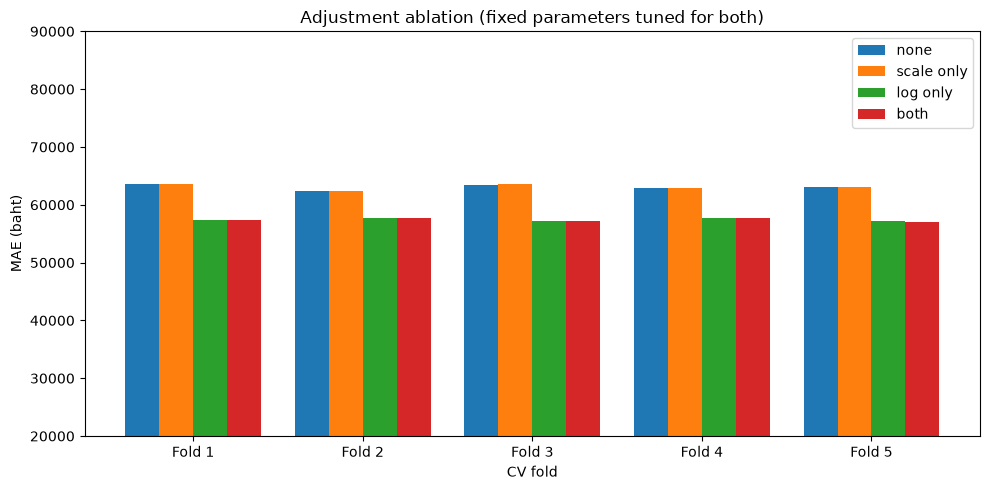

In [48]:
# [48] Ablation: กราฟ CV MAE
# ==================================================
# ทำอะไร: วาดกราฟแท่งแบบกลุ่มของ MAE ราย fold ทั้งสี่ variant
# ทำไม: ใช้ข้อมูลและกติกาเดียวกันเพื่อเปรียบเทียบการทดลองได้อย่างเป็นธรรม
# ผลที่ควรเห็น: ตารางผลที่คำนวณจริงและกราฟที่มีข้อความภาษาอังกฤษ
# ข้อควรระวัง: แกน MAE ใช้ MAE_AXIS เดียวกับทุกการทดลอง
# ==================================================
print("=== [48] Ablation: กราฟ CV MAE ===")

positions = np.arange(len(folds))
width = 0.2
fig, ax = plt.subplots(figsize=(10, 5))
for index, (label, values) in enumerate(ablation_fold_mae.items()):
    ax.bar(positions + (index - 1.5) * width, values, width, label=label)
ax.set_xticks(positions, [f"Fold {i + 1}" for i in positions])
ax.set(xlabel="CV fold", ylabel="MAE (baht)", title="Adjustment ablation (fixed parameters tuned for both)")
ax.set_ylim(*MAE_AXIS)
ax.legend()
plt.tight_layout()
plt.show()
plotted = np.concatenate(list(ablation_fold_mae.values()))
if plotted.min() < MAE_AXIS[0] or plotted.max() > MAE_AXIS[1]:
    print("WARN: ค่าบางจุดอยู่นอกแกนที่ล็อกไว้ (ablation) ให้ขยาย MAE_AXIS ในเซลล์ [03]")


=== [49] ความสำคัญแบบ permutation บน test ===

Permutation importance: increase in test MAE (baht)
variable        mean       std  share (%)
  engine 144512.2422 2015.4325    30.0352
 car_age 128689.4660 1751.8115    26.7466
car_type  74014.3761 1584.8573    15.3830
   brand  55891.5011  979.1071    11.6164
   model  35257.3977  647.5130     7.3278
    fuel  18968.3087  983.6591     3.9423
 mileage  18124.6559 1198.4804     3.7670
    gear   5685.2960  212.0918     1.1816


,variable,mean,std,share (%)
0,engine,144512.242176,2015.432479,30.035181
1,car_age,128689.465967,1751.811536,26.746601
2,car_type,74014.376073,1584.857287,15.383023
3,brand,55891.501065,979.107106,11.616395
4,model,35257.397677,647.512987,7.327838
5,fuel,18968.308723,983.659059,3.942341
6,mileage,18124.655943,1198.480380,3.766998
7,gear,5685.295978,212.091848,1.181622


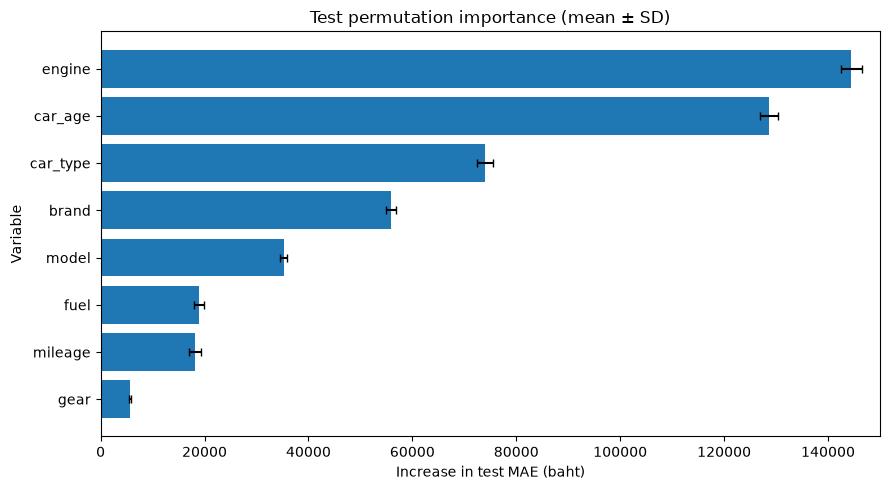

In [49]:
# [49] ความสำคัญแบบ permutation บน test
# ==================================================
# ทำอะไร: สลับตัวแปรต้นฉบับทีละคอลัมน์ก่อน encoding สิบรอบแล้ววัด MAE ที่เพิ่มเป็นบาท
# ทำไม: ใช้ข้อมูลและกติกาเดียวกันเพื่อเปรียบเทียบการทดลองได้อย่างเป็นธรรม
# ผลที่ควรเห็น: ตารางผลที่คำนวณจริงและกราฟที่มีข้อความภาษาอังกฤษ
# ข้อควรระวัง: ค่าติดลบเกิดได้; share ใช้ผลรวมมีเครื่องหมาย ไม่ตัดค่าลบทิ้ง; ถ้าผลรวมศูนย์ให้ share เป็นศูนย์
# ==================================================
print("=== [49] ความสำคัญแบบ permutation บน test ===")

importance_estimator = search.best_estimator_
X_test = test[features]
y_test = test["price"]
assert len(features) == 8 and list(X_test.columns) == features
permutation_result = permutation_importance(
    importance_estimator, X_test, y_test, scoring="neg_mean_absolute_error",
    n_repeats=10, random_state=SEED,
)
permutation_table = pd.DataFrame({"variable": features, "mean": permutation_result.importances_mean,
                                  "std": permutation_result.importances_std})
# ใช้ผลรวมแบบมีเครื่องหมาย ค่าลบหมายถึงสลับแล้วดีขึ้น; ถ้าผลรวมเป็นศูนย์ให้ share เป็นศูนย์
total_increase = permutation_table["mean"].sum()
permutation_table["share (%)"] = (100 * permutation_table["mean"] / total_increase
                                   if total_increase != 0 else 0.0)
permutation_table = permutation_table.sort_values("mean", ascending=False, kind="stable").reset_index(drop=True)
print("Permutation importance: increase in test MAE (baht)")
print(permutation_table.to_string(index=False, float_format=lambda value: f"{value:.4f}"))
display(permutation_table)
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(permutation_table["variable"], permutation_table["mean"], xerr=permutation_table["std"], capsize=3)
ax.invert_yaxis()
ax.set(xlabel="Increase in test MAE (baht)", ylabel="Variable", title="Test permutation importance (mean ± SD)")
ax.set_xlim(*PERM_AXIS)
plt.tight_layout()
plt.show()
if ((permutation_table["mean"] - permutation_table["std"]).min() < PERM_AXIS[0]
        or (permutation_table["mean"] + permutation_table["std"]).max() > PERM_AXIS[1]):
    print("WARN: ค่าบางจุดอยู่นอกแกนที่ล็อกไว้ (permutation importance) ให้ขยาย PERM_AXIS ในเซลล์ [03]")


=== [50] ความสำคัญจากโมเดลรวมกลับเป็นตัวแปร ===
Model-based importance: gain (XGB) or mean decrease of impurity (DT/RF)
variable  model_based
 car_age     0.377055
  engine     0.258812
car_type     0.127473
   brand     0.105688
   model     0.074123
 mileage     0.024569
    fuel     0.019868
    gear     0.012413


,variable,model_based
2,car_age,0.377055
0,engine,0.258812
5,car_type,0.127473
3,brand,0.105688
4,model,0.074123
1,mileage,0.024569
6,fuel,0.019868
7,gear,0.012413


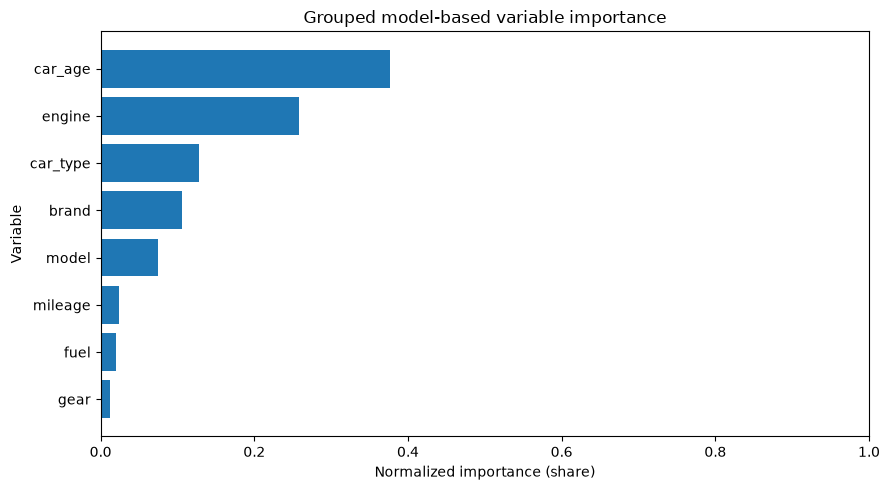

In [50]:
# [50] ความสำคัญจากโมเดลรวมกลับเป็นตัวแปร
# ==================================================
# ทำอะไร: รวม impurity หรือ gain ของ dummy กลับเป็นแปดตัวแปรและ normalize ให้รวมเป็นหนึ่ง
# ทำไม: ใช้ข้อมูลและกติกาเดียวกันเพื่อเปรียบเทียบการทดลองได้อย่างเป็นธรรม
# ผลที่ควรเห็น: ตารางผลที่คำนวณจริงและกราฟที่มีข้อความภาษาอังกฤษ
# ข้อควรระวัง: ใช้ผู้ชนะที่ fit บน train แล้ว; gain ขอผ่าน booster อย่างชัดเจน; ระดับมากอาจได้เปรียบ
# ==================================================
print("=== [50] ความสำคัญจากโมเดลรวมกลับเป็นตัวแปร ===")

fitted_model = importance_estimator.named_steps["model"]
if isinstance(fitted_model, TransformedTargetRegressor):
    fitted_model = fitted_model.regressor_
encoded_names = importance_estimator.named_steps["encode"].get_feature_names_out()
if MODEL_NAME == "XGB":
    # ขอ gain อย่างชัดเจนและจับคู่ชื่อตามลำดับจริงของ encoder (รองรับทั้งชื่อจริงและ f0, f1)
    booster = fitted_model.get_booster()
    gains = booster.get_score(importance_type="gain")
    booster_names = booster.feature_names
    if booster_names is None:
        booster_names = [f"f{i}" for i in range(len(encoded_names))]
    else:
        assert booster_names == list(encoded_names), "Booster feature order differs from encoder output"
    assert len(booster_names) == len(encoded_names)
    assert set(gains).issubset(booster_names), "Unknown booster feature name"
    weights = np.asarray([gains.get(name, 0.0) for name in booster_names], dtype=float)
else:
    weights = np.asarray(fitted_model.feature_importances_, dtype=float)
assert len(weights) == len(encoded_names)
grouped_importance = {name: 0.0 for name in features}
for encoded_name, weight in zip(encoded_names, weights):
    original_name = str(encoded_name).split("=", 1)[0]
    assert original_name in grouped_importance, f"Unknown encoded variable: {encoded_name}"
    grouped_importance[original_name] += float(weight)
total_weight = sum(grouped_importance.values())
assert total_weight > 0, "โมเดลไม่มีความสำคัญที่เป็นบวกให้ normalize"
grouped_importance = {name: weight / total_weight for name, weight in grouped_importance.items()}
assert np.isclose(sum(grouped_importance.values()), 1.0)
model_importance_table = pd.DataFrame({"variable": features,
    "model_based": [grouped_importance[name] for name in features]}).sort_values("model_based", ascending=False, kind="stable")
print("Model-based importance: gain (XGB) or mean decrease of impurity (DT/RF)")
print(model_importance_table.to_string(index=False, float_format=lambda value: f"{value:.6f}"))
display(model_importance_table)
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(model_importance_table["variable"], model_importance_table["model_based"])
ax.invert_yaxis()
ax.set(xlabel="Normalized importance (share)", ylabel="Variable", title="Grouped model-based variable importance")
ax.set_xlim(*SHARE_AXIS)
plt.tight_layout()
plt.show()
if (model_importance_table["model_based"].min() < SHARE_AXIS[0]
        or model_importance_table["model_based"].max() > SHARE_AXIS[1]):
    print("WARN: ค่าบางจุดอยู่นอกแกนที่ล็อกไว้ (model importance) ให้ขยาย SHARE_AXIS ในเซลล์ [03]")


In [51]:
# [51] เปรียบเทียบอันดับและพิมพ์ IMPORTANCE_JSON
# ==================================================
# ทำอะไร: แสดงความสำคัญและอันดับทั้งสองวิธีเคียงกันแล้วพิมพ์ JSON หนึ่งบรรทัด
# ทำไม: ใช้ข้อมูลและกติกาเดียวกันเพื่อเปรียบเทียบการทดลองได้อย่างเป็นธรรม
# ผลที่ควรเห็น: ตารางผลที่คำนวณจริงและกราฟที่มีข้อความภาษาอังกฤษ
# ข้อควรระวัง: เมื่อผลสองวิธีขัดกันควรเชื่อ permutation บนข้อมูลที่ไม่เคยเห็นมากกว่า
# ==================================================
print("=== [51] เปรียบเทียบอันดับและพิมพ์ IMPORTANCE_JSON ===")

# impurity/gain เอนเอียงไปหาตัวแปรที่มีหลายระดับ เช่น model ซึ่งมี dummy หลายร้อยตัว และคำนวณจากแถวฝึก
# permutation วัดว่า error เพิ่มบนแถวที่ไม่เคยเห็นเท่าใด เมื่อสองวิธีขัดกันควรเชื่อ permutation มากกว่า
importance_comparison = permutation_table.merge(model_importance_table, on="variable", validate="one_to_one")
importance_comparison["permutation rank"] = importance_comparison["mean"].rank(method="min", ascending=False).astype(int)
importance_comparison["model rank"] = importance_comparison["model_based"].rank(method="min", ascending=False).astype(int)
importance_comparison = importance_comparison[["variable", "mean", "std", "share (%)", "permutation rank", "model_based", "model rank"]]
print(importance_comparison.to_string(index=False, float_format=lambda value: f"{value:.4f}"))
display(importance_comparison)
print("IMPORTANCE_JSON=" + json.dumps({
    "run_id": RUN_ID,
    "permutation": {row["variable"]: {"mean": float(row["mean"]), "std": float(row["std"])}
                    for _, row in permutation_table.iterrows()},
    "model_based": grouped_importance,
}, allow_nan=False))


=== [51] เปรียบเทียบอันดับและพิมพ์ IMPORTANCE_JSON ===
variable        mean       std  share (%)  permutation rank  model_based  model rank
  engine 144512.2422 2015.4325    30.0352                 1       0.2588           2
 car_age 128689.4660 1751.8115    26.7466                 2       0.3771           1
car_type  74014.3761 1584.8573    15.3830                 3       0.1275           3
   brand  55891.5011  979.1071    11.6164                 4       0.1057           4
   model  35257.3977  647.5130     7.3278                 5       0.0741           5
    fuel  18968.3087  983.6591     3.9423                 6       0.0199           7
 mileage  18124.6559 1198.4804     3.7670                 7       0.0246           6
    gear   5685.2960  212.0918     1.1816                 8       0.0124           8


,variable,mean,std,share (%),permutation rank,model_based,model rank
0,engine,144512.242176,2015.432479,30.035181,1,0.258812,2
1,car_age,128689.465967,1751.811536,26.746601,2,0.377055,1
2,car_type,74014.376073,1584.857287,15.383023,3,0.127473,3
3,brand,55891.501065,979.107106,11.616395,4,0.105688,4
4,model,35257.397677,647.512987,7.327838,5,0.074123,5
5,fuel,18968.308723,983.659059,3.942341,6,0.019868,7
6,mileage,18124.655943,1198.480380,3.766998,7,0.024569,6
7,gear,5685.295978,212.091848,1.181622,8,0.012413,8


IMPORTANCE_JSON={"run_id": "DT_merge50minC_adj", "permutation": {"engine": {"mean": 144512.2421757915, "std": 2015.4324788751805}, "car_age": {"mean": 128689.46596652933, "std": 1751.8115360809686}, "car_type": {"mean": 74014.37607262761, "std": 1584.8572874268593}, "brand": {"mean": 55891.50106501639, "std": 979.107106140487}, "model": {"mean": 35257.39767703846, "std": 647.5129869431502}, "fuel": {"mean": 18968.308723092363, "std": 983.6590592981568}, "mileage": {"mean": 18124.655942749676, "std": 1198.4803795856023}, "gear": {"mean": 5685.29597789446, "std": 212.09184768850173}}, "model_based": {"engine": 0.258811601388008, "mileage": 0.024568824040969658, "car_age": 0.3770547989575815, "brand": 0.10568761762360342, "model": 0.07412299200092047, "car_type": 0.12747284932757705, "fuel": 0.019868319986366043, "gear": 0.012412996674973958}}
